# 03 – Dimensionality Reduction

**Projekt:** Unsupervised Learning (Uni Münster, WS 26/27) – 3.839 transkribierte Bittbriefe an Papst Pius XII.
**Ziel:** Struktur der Briefe in wenigen Dimensionen sichtbar machen, als Vorbereitung für das spätere Clustering.
**Kein Clustering** in diesem Notebook.

| Teil | Inhalt | Quelle |
|---|---|---|
| A | Curse of Dimensionality (Simulation + echte Daten) | Vorlesung 09 |
| B | PCA auf der Feature-Tabelle: Kovarianz vs. Korrelation, Eigenzerlegung, Scree, Kaiser, Biplot | Vorlesung 09 |
| B | Parallel Analysis nach Horn | **Erweiterung** (Vorlesung erwähnt Monte-Carlo-Vergleich mit Rauschen) |
| C | Text-Pre-Processing (spaCy) + TF-IDF | Grundlage aus der Text-Mining-Vorlesung |
| D | TruncatedSVD/LSA | **Erweiterung** (PCA für dünnbesetzte Matrizen) |
| D | PCA vs. t-SNE vs. UMAP, Autoencoder (nichtlinear + linear) | Vorlesung „Projections & Encoders“ |
| D | PaCMAP | **Erweiterung, nicht Vorlesung** |
| E | Qualitätsmaße (Trustworthiness, kNN-Erhalt, Spearman) | **Erweiterung, nicht Vorlesung** |
| F | Inhaltliche Exploration per Koordinaten-Rechteck, Outlier in der Projektion | – |

Eingaben aus dem Outlier-Notebook (`results/outliers/`): `features.csv`, `outlier_overview.csv`,
`outlier_flags_for_pipeline.csv`, `languages.csv`. Alle Ausgaben liegen getrennt in `figures/dimred/` und `results/dimred/`.
Rechenintensive Schritte werden in `results/dimred/projections/` bzw. `results/dimred/cache/` gecacht. `random_state = 42` überall.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats
from scipy.spatial.distance import pdist

warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import outliers as O  # noqa: E402
from src import dimred as D  # noqa: E402
from src.outliers import PALETTE, RANDOM_STATE, save_fig  # noqa: E402

DATA_ZIP = ROOT / "data" / "Habemus_Data_-20261108.zip"
RAW_DIR = ROOT / "data" / "raw"
OUT_RES = ROOT / "results" / "outliers"           # Eingaben aus dem Outlier-Notebook
RES = ROOT / "results" / "dimred"
PROJ = RES / "projections"
CACHE = RES / "cache"
FIG = ROOT / "figures" / "dimred"
for p in (RES, PROJ, CACHE, FIG):
    p.mkdir(parents=True, exist_ok=True)

O.set_style()
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
STATS = {}
import os
REBUILD = os.environ.get("DIMRED_REBUILD") == "1"   # =1 → alle Caches neu berechnen und überschreiben
print("Projektordner:", ROOT, "| REBUILD:", REBUILD)

Projektordner: C:\Users\Arne\uni_project\UL\new_results | REBUILD: False


## 0. Daten laden und ausgeschlossene Briefe entfernen

Die Rohdaten werden wie im Outlier-Notebook geladen. Features, Sprache und Outlier-Flags werden **wiederverwendet und nicht neu berechnet**.
Briefe mit `exclude = True` (Fragmente, Archivverweise) werden für alle Analysen entfernt.
Falls die Outlier-Ergebnisse fehlen, baut die Fallback-Logik die Features neu und setzt `exclude = False`.

In [2]:
df = O.load_data(DATA_ZIP, RAW_DIR)

if (OUT_RES / "features.csv").exists():
    feat = pd.read_csv(OUT_RES / "features.csv")
    lang = pd.read_csv(OUT_RES / "languages.csv")
    ov = pd.read_csv(OUT_RES / "outlier_overview.csv")[["id", "n_flags_all"]]
    flags = pd.read_csv(OUT_RES / "outlier_flags_for_pipeline.csv")[["id", "exclude"]]
    print("Outlier-Ergebnisse gefunden und wiederverwendet.")
else:  # Fallback: Features wie im Outlier-Notebook neu bauen
    print("WARNUNG: keine Outlier-Ergebnisse – Features werden neu gebaut, exclude = False.")
    df["year"] = df["date_extracted_from_text"].map(O.extract_year)
    df["lang_detected"] = df["raw_text"].map(O.detect_language)
    df["language_filled"] = df["main_language"].fillna(df["lang_detected"])
    feat = O.build_features(df)
    lang = df[["id", "main_language", "lang_detected", "language_filled"]]
    ov = pd.DataFrame({"id": df["id"], "n_flags_all": 0})
    flags = pd.DataFrame({"id": df["id"], "exclude": False})

df = (df.drop(columns=["main_language"])
        .merge(lang, on="id").merge(ov, on="id").merge(flags, on="id")
        .merge(feat.drop(columns=["lang_mismatch"]), on="id"))
n_total = len(df)
excluded_ids = df.loc[df["exclude"], "id"].tolist()
df = df.loc[~df["exclude"]].reset_index(drop=True)
print(f"Briefe gesamt: {n_total} | ausgeschlossen (exclude=True): {len(excluded_ids)} | verwendet: {len(df)}")
STATS["n_letters_total"] = n_total
STATS["n_excluded"] = len(excluded_ids)
STATS["n_used"] = len(df)

Outlier-Ergebnisse gefunden und wiederverwendet.
Briefe gesamt: 3839 | ausgeschlossen (exclude=True): 27 | verwendet: 3812


### Färbe-Variablen

Sie werden in allen 2D-Plots wiederverwendet (`D.plot_projection` erzeugt je Variable einen Subplot):

- **Sprache** (`language_filled`, 5 häufigste + „Andere“)
- **Jahr** (gruppiert; die Ränder „≤1939“ bzw. „≥1943“ fassen auch die wenigen Briefe von 1932–37 bzw. 1946–48 ein)
- **doc_style**
- **Archiv** (`signature_archive`, Kürzel)
- **Anliegen**: `what_is_requested` per Keyword-Regeln gebündelt. Die Regeln werden in fester Priorität geprüft:
  Freilassung/Internierung → Geld/Unterstützung → Visum/Emigration → Auskunft/Suche → Fürsprache/Empfehlung → Sonstiges.
  Die Regeln stehen in `src/dimred.py`.
- **Outlier**: `n_flags_all ≥ 3` aus dem Outlier-Notebook

In [3]:
style_map = {("Handschriftlich",): "Handschriftlich", ("Maschinenschriftlich",): "Maschinenschr.",
             ("Maschinenschriftlich", "Handschriftlich"): "Masch. + Handschr.", (): "(leer)"}
COLORS = pd.DataFrame({
    "Sprache": D.top_k(df["language_filled"].fillna("unbekannt"), 5),
    "Jahr": df["year"].map(D.year_group),
    "doc_style": df["doc_style"].map(lambda l: style_map.get(tuple(l), " + ".join(l))),
    "Archiv": D.top_k(df["signature_archive"].map(D.archive_short), 2),
    "Anliegen": df["what_is_requested"].map(D.request_category),
    "Outlier": np.where(df["n_flags_all"] >= 3, "ja", "nein"),
})
ORDERS = {"Jahr": D.YEAR_ORDER, "Anliegen": D.REQUEST_ORDER}
for c in COLORS:
    display(COLORS[c].value_counts().rename("Briefe").to_frame().T)

Sprache,Italienisch,Deutsch,Französisch,Andere,Englisch,Spanisch
Briefe,2116,1059,467,88,54,28


Jahr,1940,1941,≤1939,≥1943,1942,unbekannt
Briefe,1175,744,671,457,452,313


doc_style,Handschriftlich,Masch. + Handschr.,Maschinenschr.,(leer)
Briefe,1904,1255,632,21


Archiv,AAV,ASRS,Andere
Briefe,1954,1744,114


Anliegen,Visum/Emigration,Geld/Unterstützung,Sonstiges,Fürsprache/Empfehlung,Freilassung/Internierung,Auskunft/Suche
Briefe,1270,754,597,545,432,214


Outlier,nein,ja
Briefe,3702,110


## Teil A – Curse of Dimensionality  *[Vorlesung 09]*

### 1. Simulation: Distanzkonzentration

**Was:** Für $d \in \{2, 10, 50, 100, 500, 1000\}$ werden je 1.000 Punkte aus $\text{Unif}([0,1]^d)$ gezogen und alle paarweisen
euklidischen Distanzen berechnet. Maß ist der relative Kontrast $(\max - \min)/\min$.

**Vorlesung:** $E\|X-Y\|_2^2 = d/6$, und $\|X-Y\|_2/\sqrt{d} \to 1/\sqrt{6}$. Mit wachsendem $d$ werden alle Distanzen fast gleich.
„Nächster Nachbar“ und „Ausreißer“ verlieren dann ihre Bedeutung.

,(max-min)/min,mittl. Distanz / sqrt(d),Std/Mittelwert
d,,,
2,1064.254,0.371,0.476
10,8.328,0.399,0.194
50,1.346,0.407,0.084
100,0.825,0.407,0.059
500,0.285,0.408,0.026
1000,0.184,0.408,0.018


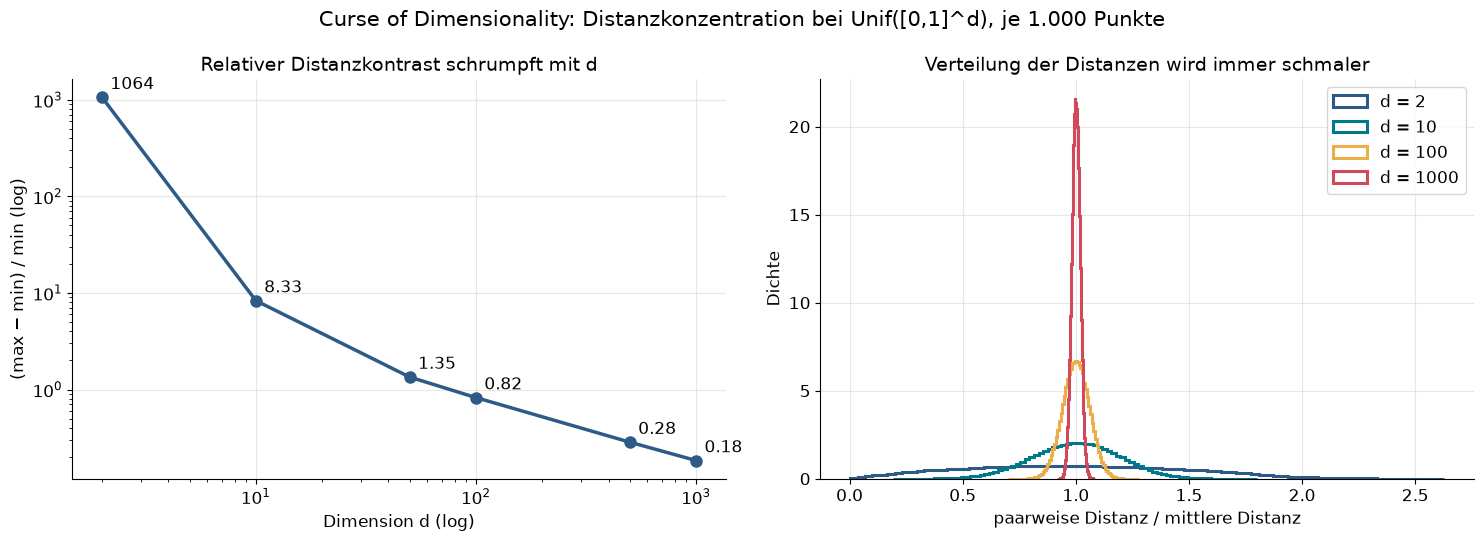

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
DIMS = [2, 10, 50, 100, 500, 1000]
sim = {}
for d in DIMS:
    Xs = rng.random((1000, d))
    dist = pdist(Xs)
    sim[d] = dist
contrast_tab = pd.DataFrame({
    "d": DIMS,
    "(max-min)/min": [(sim[d].max() - sim[d].min()) / sim[d].min() for d in DIMS],
    "mittl. Distanz / sqrt(d)": [sim[d].mean() / np.sqrt(d) for d in DIMS],
    "Std/Mittelwert": [sim[d].std() / sim[d].mean() for d in DIMS],
}).set_index("d")
display(contrast_tab.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
ax.plot(DIMS, contrast_tab["(max-min)/min"], "o-", color=PALETTE["main"], lw=2.5, ms=8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Dimension d (log)"); ax.set_ylabel("(max − min) / min (log)")
ax.set_title("Relativer Distanzkontrast schrumpft mit d")
for d, v in contrast_tab["(max-min)/min"].items():
    ax.annotate(f"{v:.2f}" if v < 100 else f"{v:.0f}", (d, v), xytext=(6, 6), textcoords="offset points", fontsize=12)
ax = axes[1]
cols = [PALETTE["main"], PALETTE["teal"], PALETTE["accent"], PALETTE["outlier"]]
for d, c in zip([2, 10, 100, 1000], cols):
    ax.hist(sim[d] / sim[d].mean(), bins=80, density=True, histtype="step", lw=2.2, color=c, label=f"d = {d}")
ax.set_xlabel("paarweise Distanz / mittlere Distanz")
ax.set_ylabel("Dichte")
ax.set_title("Verteilung der Distanzen wird immer schmaler")
ax.legend()
fig.suptitle("Curse of Dimensionality: Distanzkonzentration bei Unif([0,1]^d), je 1.000 Punkte")
fig.tight_layout()
save_fig(fig, "curse_of_dimensionality", FIG)
plt.show()
STATS["curse_simulation_contrast"] = contrast_tab["(max-min)/min"].round(4).to_dict()

**Interpretation:** Der relative Kontrast fällt von 1.064 (d = 2) über 8,3 (d = 10) auf 0,18 (d = 1.000), und Std/Mittelwert der Distanzen sinkt von 0,48 auf 0,018. Die mittlere Distanz geteilt durch √d nähert sich wie in der Vorlesung 1/√6 ≈ 0,408. In hohen Dimensionen sind praktisch alle Punkte gleich weit voneinander entfernt.

## Teil B – PCA auf der Feature-Tabelle  *[Vorlesung 09]*

### 3. Vorbereitung

**Was:** Die 9 stetigen Features aus dem Outlier-Notebook werden verwendet. Schiefe Features ($|\text{skew}| > 1$) werden wie dort per `log1p`
transformiert. Die Auswahl wird aus `results/outliers/skewness_before_after.csv` übernommen.
Mittelwerte und Varianzen zeigen, dass die Skalen stark voneinander abweichen.
**Vorlesung:** „Scaling issues“: Variablen mit großer Varianz dominieren die ersten PCs, wenn man die Kovarianzmatrix verwendet.

In [5]:
CONT = ["n_words", "n_chars", "avg_word_len", "share_non_alpha", "share_digits", "share_upper",
        "n_persons", "n_places", "n_organisations"]
sk_path = OUT_RES / "skewness_before_after.csv"
if sk_path.exists():
    sk = pd.read_csv(sk_path, index_col=0)
    LOG_COLS = [c for c in CONT if bool(sk.loc[c, "log1p?"])]
else:
    LOG_COLS = [c for c in CONT if abs(stats.skew(df[c])) > 1]
XF = df[CONT].astype(float).copy()
for c in LOG_COLS:
    XF[c] = np.log1p(XF[c])
print("log1p:", LOG_COLS)
scale_tab = pd.DataFrame({"Mittelwert": XF.mean(), "Varianz": XF.var(), "Std": XF.std()})
scale_tab["Anteil an Gesamtvarianz %"] = (100 * scale_tab["Varianz"] / scale_tab["Varianz"].sum()).round(2)
display(scale_tab.round(4))
print(f"Verhältnis größte/kleinste Varianz: {scale_tab['Varianz'].max() / scale_tab['Varianz'].min():,.0f}")

log1p: ['n_words', 'n_chars', 'share_non_alpha', 'share_digits', 'share_upper', 'n_persons', 'n_places', 'n_organisations']


,Mittelwert,Varianz,Std,Anteil an Gesamtvarianz %
n_words,5.5219,0.5601,0.7484,28.75
n_chars,7.3782,0.5628,0.7502,28.89
avg_word_len,5.4463,0.1577,0.3971,8.10
share_non_alpha,0.0440,0.0003,0.0159,0.01
share_digits,0.0146,0.0001,0.0107,0.01
share_upper,0.0744,0.0031,0.0557,0.16
n_persons,1.3283,0.2367,0.4865,12.15
n_places,1.6310,0.2244,0.4737,11.52
n_organisations,0.4188,0.2027,0.4503,10.41


Verhältnis größte/kleinste Varianz: 4,962


**Interpretation:** Die Skalen unterscheiden sich um mehr als den Faktor 4.900: Die Varianz von log(n_words) liegt bei 0,56, die von share_digits bei 0,0001. Die beiden Längen-Features tragen zusammen 58 % der Gesamtvarianz, die drei Anteils-Features weniger als 0,2 %.

### 4. PCA auf Kovarianz- vs. Korrelationsmatrix

(a) **Kovarianz:** Die Daten werden nur zentriert. (b) **Korrelation:** Die Daten werden zusätzlich auf Varianz 1 standardisiert.
Die Vorlesung empfiehlt (b), wenn die Skalen verschieden sind („This is rarely the case in practise!“).

,Kovarianz: erkl. Var. %,Korrelation: erkl. Var. %
PC1,61.53,36.42
PC2,13.93,17.45
PC3,9.08,12.06
PC4,8.41,10.75
PC5,6.91,8.16
PC6,0.14,7.20
PC7,0.01,6.21
PC8,0.00,1.75
PC9,0.00,0.00


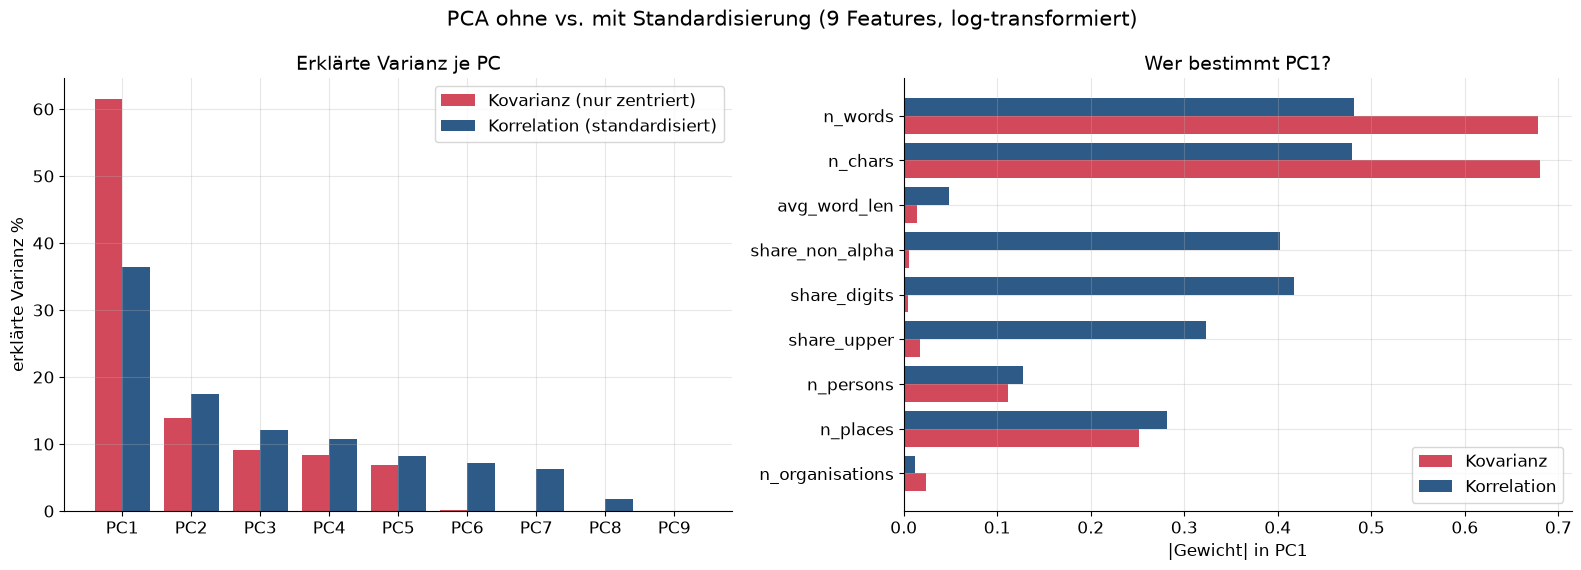

,n_words,n_chars,avg_word_len,share_non_alpha,share_digits,share_upper,n_persons,n_places,n_organisations
Kovarianz,0.679,0.68,0.015,0.006,0.004,0.017,0.111,0.252,0.024
Korrelation,0.482,0.48,0.049,0.402,0.417,0.323,0.127,0.281,0.012


In [6]:
from sklearn.decomposition import PCA

Xc = (XF - XF.mean()).to_numpy()
Xz = ((XF - XF.mean()) / XF.std(ddof=1)).to_numpy()      # ddof=1 → Kovarianz von Xz = Korrelationsmatrix
pca_cov = PCA(random_state=RANDOM_STATE).fit(Xc)
pca_cor = PCA(random_state=RANDOM_STATE).fit(Xz)
ev_tab = pd.DataFrame({"Kovarianz: erkl. Var. %": 100 * pca_cov.explained_variance_ratio_,
                       "Korrelation: erkl. Var. %": 100 * pca_cor.explained_variance_ratio_},
                      index=[f"PC{i+1}" for i in range(len(CONT))])
display(ev_tab.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))
ax = axes[0]
x = np.arange(len(CONT))
ax.bar(x - 0.2, ev_tab.iloc[:, 0], width=0.4, color=PALETTE["outlier"], label="Kovarianz (nur zentriert)")
ax.bar(x + 0.2, ev_tab.iloc[:, 1], width=0.4, color=PALETTE["main"], label="Korrelation (standardisiert)")
ax.set_xticks(x, ev_tab.index)
ax.set_ylabel("erklärte Varianz %")
ax.set_title("Erklärte Varianz je PC")
ax.legend()
ax = axes[1]
load1 = pd.DataFrame({"Kovarianz": np.abs(pca_cov.components_[0]), "Korrelation": np.abs(pca_cor.components_[0])}, index=CONT)
y = np.arange(len(CONT))
ax.barh(y + 0.2, load1["Kovarianz"], height=0.4, color=PALETTE["outlier"], label="Kovarianz")
ax.barh(y - 0.2, load1["Korrelation"], height=0.4, color=PALETTE["main"], label="Korrelation")
ax.set_yticks(y, CONT)
ax.invert_yaxis()
ax.set_xlabel("|Gewicht| in PC1")
ax.set_title("Wer bestimmt PC1?")
ax.legend(loc="lower right")
fig.suptitle("PCA ohne vs. mit Standardisierung (9 Features, log-transformiert)")
fig.tight_layout()
save_fig(fig, "pca_cov_vs_corr", FIG)
plt.show()
display(load1.round(3).T)

**Interpretation:** Ohne Standardisierung erklärt PC1 61,5 % der Varianz und besteht fast nur aus n_words und n_chars (Gewicht je 0,68). Die Anteils-Features gehen mit Gewichten unter 0,02 unter. Mit Standardisierung sinkt PC1 auf 36,4 %, und share_digits/share_non_alpha/share_upper (0,32–0,42) bekommen ein echtes Gewicht. Wie in der Vorlesung gefordert, wird im Folgenden die Korrelationsmatrix verwendet.

### 5. Eigenzerlegung „von Hand“

$\Sigma_X = Q D Q^\top$ mit `numpy.linalg.eigh` auf der Korrelationsmatrix, nach absteigenden Eigenwerten sortiert, und Vergleich mit sklearn.
Sanity-Check aus der Vorlesung: $\sum_i \lambda_i = \text{tr}(\Sigma) = p$ (bei der Korrelationsmatrix).

In [7]:
R = np.corrcoef(Xz, rowvar=False)
lam, Q = np.linalg.eigh(R)
order = np.argsort(lam)[::-1]
lam, Q = lam[order], Q[:, order]
cmp = pd.DataFrame({"λ (eigh)": lam, "λ (sklearn)": pca_cor.explained_variance_,
                    "max |Δ Eigenvektor| (bis auf Vorzeichen)":
                        [np.min([np.abs(Q[:, i] - pca_cor.components_[i]).max(),
                                 np.abs(Q[:, i] + pca_cor.components_[i]).max()]) for i in range(len(CONT))]},
                   index=[f"PC{i+1}" for i in range(len(CONT))])
display(cmp.style.format("{:.2e}", subset=["max |Δ Eigenvektor| (bis auf Vorzeichen)"]).format("{:.4f}", subset=["λ (eigh)", "λ (sklearn)"]))
print(f"Summe der Eigenwerte = {lam.sum():.6f}  |  tr(R) = {np.trace(R):.6f}  |  p = {len(CONT)}")
Y_scores = Xz @ Q
print("Kovarianz der Scores ist diagonal (max |Nebendiagonale|):",
      f"{np.abs(np.cov(Y_scores, rowvar=False) - np.diag(lam)).max():.2e}")
STATS["features_pca"] = {"eigenvalues": lam.round(4).tolist(),
                         "explained_variance_pc1_3_pct": (100 * lam[:3] / lam.sum()).round(2).tolist(),
                         "trace_check": round(float(lam.sum()), 6)}

,λ (eigh),λ (sklearn),max |Δ Eigenvektor| (bis auf Vorzeichen)
PC1,3.2774,3.2774,4.44e-16
PC2,1.5706,1.5706,2.55e-15
PC3,1.0852,1.0852,4.27e-15
PC4,0.9677,0.9677,1.12e-15
PC5,0.7342,0.7342,3.11e-15
PC6,0.6483,0.6483,1.63e-15
PC7,0.5590,0.5590,1.86e-15
PC8,0.1576,0.1576,9.61e-16
PC9,0.0000,0.0000,8.06e-16


Summe der Eigenwerte = 9.000000  |  tr(R) = 9.000000  |  p = 9
Kovarianz der Scores ist diagonal (max |Nebendiagonale|): 9.99e-16


**Interpretation:** Die Eigenzerlegung mit numpy.linalg.eigh stimmt mit sklearn überein. Die Summe der Eigenwerte ist exakt tr(R) = p = 9, und die Kovarianz der Scores ist diagonal (Abweichung ~1e-15). Der letzte Eigenwert ist praktisch 0: Im Log-Raum gilt fast exakt log(n_chars) ≈ log(n_words) + log(avg_word_len + 1). Das ist die „perfekte lineare Beziehung“ aus der Vorlesung, also reine Redundanz.

### 6. Wie viele Komponenten?

Alle Kriterien der Vorlesung, zusätzlich Parallel Analysis:

- **Scree-Plot**: $\lambda_k$ gegen $k$, Ellbogen (hier automatisch als größte zweite Differenz bestimmt, visuell geprüft).
- **Kumulierte erklärte Varianz** mit 80-%-Linie (Vorlesung: Schwelle meist 70–90 %).
- **Kaiser-Kriterium**: Bei der Korrelationsmatrix werden PCs mit $\lambda < 1$ (unter der durchschnittlichen Varianz) ausgeschlossen.
- **Parallel Analysis nach Horn** *[Erweiterung]*: Die Spalten werden 100× unabhängig permutiert. Das zerstört alle Korrelationen,
  erhält aber die Randverteilungen. Behalten werden PCs, deren $\lambda_k$ über dem 95-%-Quantil der Rausch-Eigenwerte liegt.
  Das ist genau der Monte-Carlo-Vergleich mit weißem Rauschen, den die Vorlesung erwähnt („diagonalize covariance matrices of white noise“).

,Kriterium,empfohlene Anzahl PCs
0,Scree-Ellbogen,2
1,Kaiser (λ > 1),3
2,kumuliert ≥ 80 %,5
3,Parallel Analysis (95 %),3


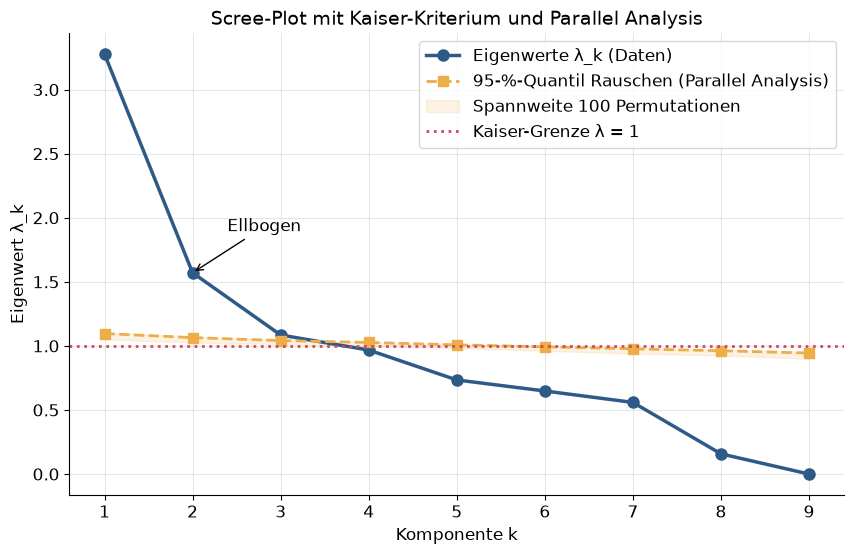

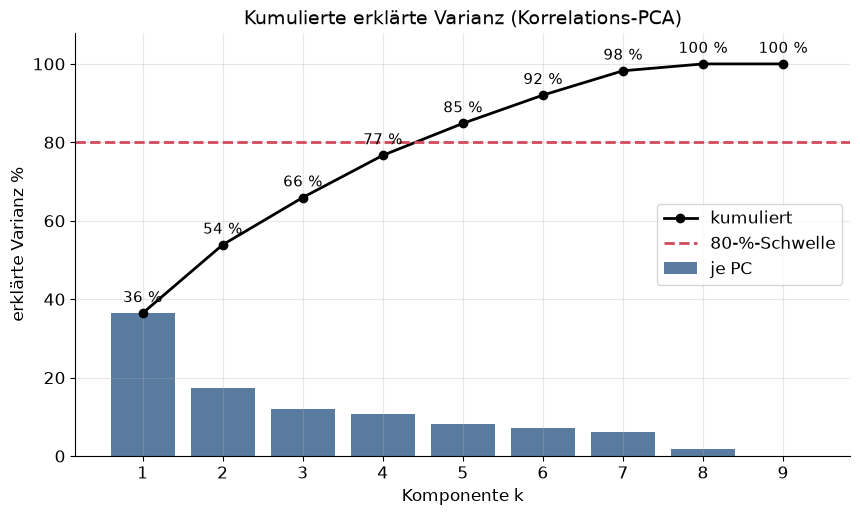

In [8]:
rng = np.random.default_rng(RANDOM_STATE)
perm_eigs = []
for _ in range(100):
    Xp = np.column_stack([rng.permutation(Xz[:, j]) for j in range(Xz.shape[1])])
    perm_eigs.append(np.sort(np.linalg.eigvalsh(np.corrcoef(Xp, rowvar=False)))[::-1])
perm_eigs = np.array(perm_eigs)
pa95 = np.quantile(perm_eigs, 0.95, axis=0)

k_idx = np.arange(1, len(lam) + 1)
cum = np.cumsum(lam) / lam.sum()
elbow = int(np.argmax(np.diff(lam, 2)) + 2)     # größte Krümmung
kaiser = int((lam > 1).sum())
k80 = int(np.argmax(cum >= 0.8) + 1)
pa_k = int(np.argmax(~(lam > pa95))) if (~(lam > pa95)).any() else len(lam)
crit = pd.DataFrame({"Kriterium": ["Scree-Ellbogen", "Kaiser (λ > 1)", "kumuliert ≥ 80 %", "Parallel Analysis (95 %)"],
                     "empfohlene Anzahl PCs": [elbow, kaiser, k80, pa_k]})
display(crit)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(k_idx, lam, "o-", color=PALETTE["main"], lw=2.5, ms=8, label="Eigenwerte λ_k (Daten)")
ax.plot(k_idx, pa95, "s--", color=PALETTE["accent"], lw=2, ms=7, label="95-%-Quantil Rauschen (Parallel Analysis)")
ax.fill_between(k_idx, perm_eigs.min(0), perm_eigs.max(0), color=PALETTE["accent"], alpha=0.15, label="Spannweite 100 Permutationen")
ax.axhline(1, color=PALETTE["outlier"], ls=":", lw=2, label="Kaiser-Grenze λ = 1")
ax.annotate("Ellbogen", (elbow, lam[elbow - 1]), xytext=(25, 30), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="black"), fontsize=12)
ax.set_xticks(k_idx)
ax.set_xlabel("Komponente k")
ax.set_ylabel("Eigenwert λ_k")
ax.set_title("Scree-Plot mit Kaiser-Kriterium und Parallel Analysis")
ax.legend()
save_fig(fig, "scree_kaiser_parallel", FIG)
plt.show()

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(k_idx, 100 * lam / lam.sum(), color=PALETTE["main"], alpha=0.8, label="je PC")
ax.plot(k_idx, 100 * cum, "o-", color="black", lw=2, label="kumuliert")
ax.axhline(80, color=PALETTE["outlier"], ls="--", lw=2, label="80-%-Schwelle")
for k, v in zip(k_idx, 100 * cum):
    ax.annotate(f"{v:.0f} %", (k, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=11)
ax.set_xticks(k_idx)
ax.set_xlabel("Komponente k")
ax.set_ylabel("erklärte Varianz %")
ax.set_ylim(0, 108)
ax.set_title("Kumulierte erklärte Varianz (Korrelations-PCA)")
ax.legend(loc="center right")
save_fig(fig, "cumulative_variance", FIG)
plt.show()
crit.to_csv(RES / "features_pca_n_components.csv", index=False)
STATS["features_pca"]["recommended_n_components"] = dict(zip(crit["Kriterium"], crit["empfohlene Anzahl PCs"].astype(int)))

**Interpretation:** Ellbogen: 2 PCs, Kaiser: 3 (λ₃ = 1,09), Parallel Analysis: 3, 80-%-Regel: 5. Kaiser und Parallel Analysis stimmen überein. Wir empfehlen 3 PCs (≈ 66 % der Varianz). Die 80-%-Regel verlangt mehr, weil die übrigen Features (Wortlänge, Organisationen) jeweils eigene, kaum korrelierte Varianz tragen.

### 7. Loadings der ersten vier PCs

Die Loadings sind die Eigenvektor-Gewichte $\gamma_{ij}$ (wie in der Vorlesung, „results['loadings']“). Das Vorzeichen jeder PC ist frei wählbar.
Es wird so gesetzt, dass das betragsgrößte Gewicht positiv ist.

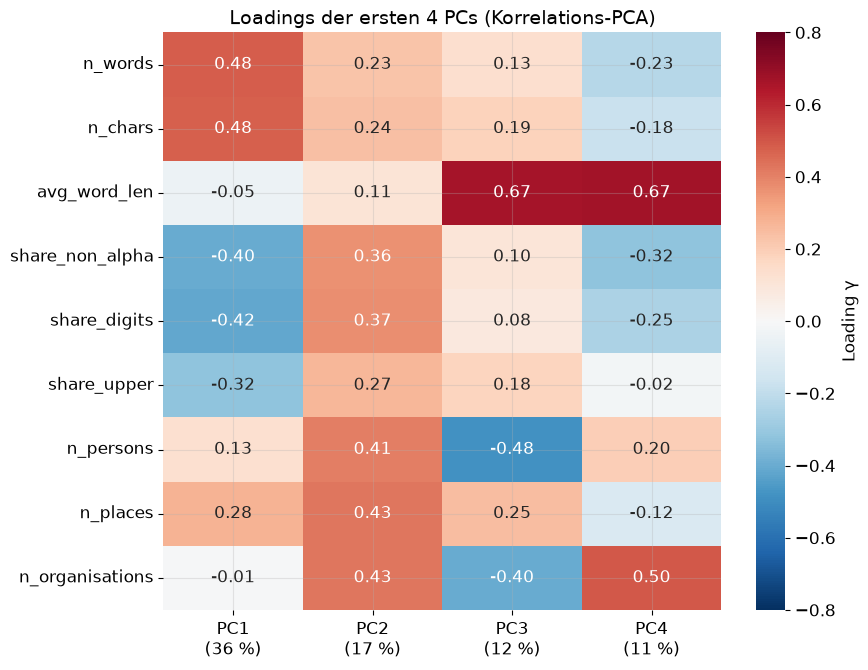

PC1 → n_words (+0.48), n_chars (+0.48), share_digits (-0.42)
PC2 → n_organisations (+0.43), n_places (+0.43), n_persons (+0.41)
PC3 → avg_word_len (+0.67), n_persons (-0.48), n_organisations (-0.40)
PC4 → avg_word_len (+0.67), n_organisations (+0.50), share_non_alpha (-0.32)


In [9]:
NPC = 4
Qs = Q[:, :NPC].copy()
for i in range(NPC):
    if Qs[np.argmax(np.abs(Qs[:, i])), i] < 0:
        Qs[:, i] *= -1
Y_scores[:, :NPC] = Xz @ Qs
loadings = pd.DataFrame(Qs, index=CONT, columns=[f"PC{i+1}" for i in range(NPC)])
loadings.to_csv(RES / "features_pca_loadings.csv")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap=O.DIV_CMAP, vmin=-0.8, vmax=0.8, center=0,
            annot_kws={"size": 12}, cbar_kws={"label": "Loading γ"}, ax=ax)
ax.set_xticklabels([f"PC{i+1}\n({100 * lam[i] / lam.sum():.0f} %)" for i in range(NPC)], rotation=0)
ax.set_title("Loadings der ersten 4 PCs (Korrelations-PCA)")
save_fig(fig, "loadings_heatmap", FIG)
plt.show()
for c in loadings:
    top = loadings[c].abs().sort_values(ascending=False).index[:3]
    print(c, "→", ", ".join(f"{t} ({loadings.loc[t, c]:+.2f})" for t in top))

**Interpretation:** **PC1 – „Textumfang vs. Zeichenrauschen“**: n_words/n_chars positiv, share_digits/share_non_alpha/share_upper negativ. Lange Fließtexte stehen kurzen, ziffern- und versalienreichen Texten (Telegramme, Formulare) gegenüber. **PC2 – „Entitätendichte“**: n_persons, n_places, n_organisations, alle positiv. **PC3 – „Wortlänge vs. Personen/Organisationen“**: lange Wörter (z. B. deutsche Komposita) gegen viele Personen-/Organisationsnennungen. **PC4 – „Transkriptionsqualität/Formalität“**: lange Wörter und Organisationen gegen viele Sonderzeichen.

### 8. Biplot

Die Punkte sind die Scores der Briefe auf den PCs, die Pfeile die Loadings (zur Lesbarkeit skaliert). Lesart nach der Vorlesung (Rossiter):
- **Winkel zwischen Pfeilen** zeigt die Korrelation: klein heißt positiv, 90° unkorreliert, entgegengesetzt negativ.
- **Pfeillänge** zeigt, wie gut die Variable in den beiden PCs abgebildet ist.
- **Parallelität zu einer Achse** heißt: Die Variable trägt vor allem zu dieser PC bei.
- **Distanz eines Punktes zum Ursprung** heißt: starke Ausprägung in mindestens einer Variable.

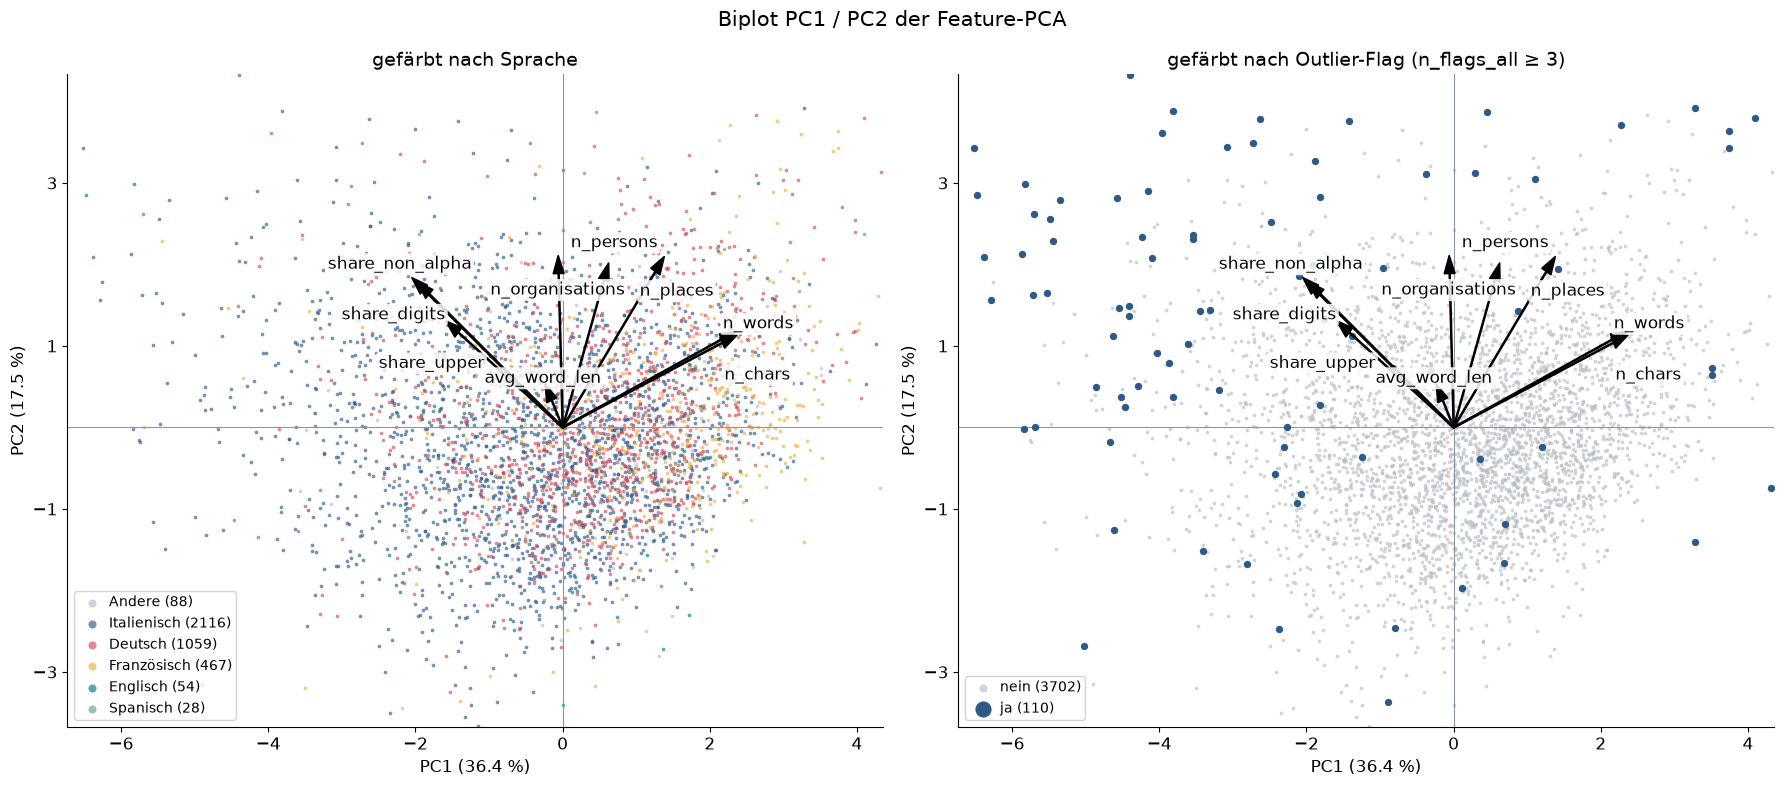

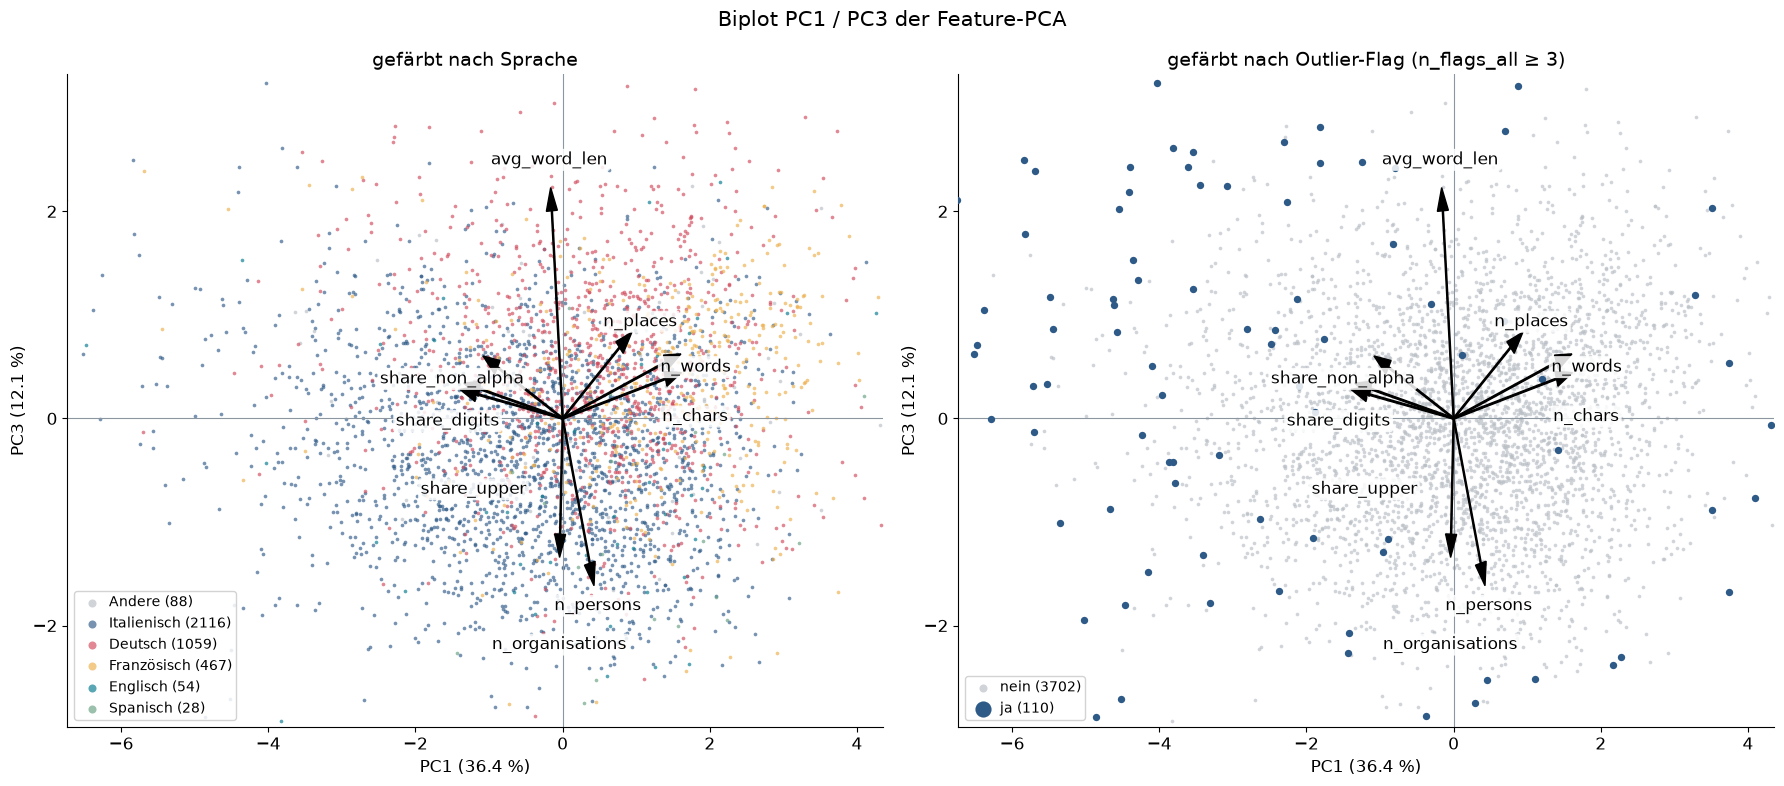

In [10]:
def biplot(ax, scores, load, i, j, labels, order=None, highlight=None):
    D.scatter_by(ax, scores[:, [i, j]], labels, order=order, s=7, highlight=highlight, legend_loc="lower left")
    lo = np.percentile(scores[:, [i, j]], 0.5, axis=0) - 0.5
    hi = np.percentile(scores[:, [i, j]], 99.5, axis=0) + 0.5
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
    ax.set_xticks(np.arange(np.ceil(lo[0]), hi[0], 2)); ax.set_yticks(np.arange(np.ceil(lo[1]), hi[1], 2))
    reach = 0.75 * min(np.abs(lo).min(), hi.min())
    scale = reach / np.sqrt((load[:, [i, j]] ** 2).sum(1)).max()
    placed = []
    for k, name in enumerate(CONT):
        ex, ey = load[k, i] * scale, load[k, j] * scale
        ax.arrow(0, 0, ex, ey, color="black", width=0.015, head_width=0.15, length_includes_head=True, zorder=4)
        tx, ty = ex * 1.12, ey * 1.12
        while any(abs(tx - px) < 1.2 and abs(ty - py) < 0.32 for px, py in placed):
            ty -= 0.34                                   # überlappende Beschriftungen stapeln
        placed.append((tx, ty))
        ax.text(tx, ty, name, fontsize=12, zorder=5, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    ax.axhline(0, color=PALETTE["grey"], lw=0.8); ax.axvline(0, color=PALETTE["grey"], lw=0.8)
    ax.set_xlabel(f"PC{i+1} ({100 * lam[i] / lam.sum():.1f} %)")
    ax.set_ylabel(f"PC{j+1} ({100 * lam[j] / lam.sum():.1f} %)")

for (i, j), name in [((0, 1), "biplot_pc1_pc2"), ((0, 2), "biplot_pc1_pc3")]:
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    biplot(axes[0], Y_scores, Qs, i, j, COLORS["Sprache"])
    axes[0].set_title("gefärbt nach Sprache")
    biplot(axes[1], Y_scores, Qs, i, j, COLORS["Outlier"], highlight="ja")
    axes[1].set_title("gefärbt nach Outlier-Flag (n_flags_all ≥ 3)")
    fig.suptitle(f"Biplot PC{i+1} / PC{j+1} der Feature-PCA")
    fig.tight_layout()
    save_fig(fig, name, FIG)
    plt.show()

**Interpretation:** Die Pfeile von n_words und n_chars liegen übereinander (r ≈ 1), ebenso share_digits und share_non_alpha (r = 0,86). Die Längen-Pfeile zeigen grob entgegengesetzt zu den Anteils-Pfeilen, das heißt: negative Korrelation. Die Entitäten-Pfeile stehen fast senkrecht und bilden PC2. Die Sprachen überlagern sich im Feature-Raum vollständig, die 9 Features trennen nicht nach Sprache. Die Outlier liegen fern vom Ursprung: links oben (kurz, ziffern- und sonderzeichenreich) und rechts oben (lang, viele Entitäten).

## Teil C – Textrepräsentation für hochdimensionale DR

### 9. Pre-Processing pro Sprache

Kleinschreibung, Entfernen von Zahlen und Satzzeichen, Stopwords und Lemmatisierung mit spaCy
(`it_core_news_sm`, `de_core_news_sm`, `fr_core_news_sm`) für die drei großen Sprachen. Für die übrigen Sprachen
(ca. 5 % der Briefe) gibt es keine Modelle. Sie werden nur tokenisiert und von den Stopwords des jeweiligen spaCy-Sprachpakets befreit.
Nur Tokens mit mindestens 3 Buchstaben werden behalten.

**Zwei Anpassungen nach dem ersten Lauf:**
- Das Lemmatisierungs-Modell richtet sich nach der **im Text erkannten** Sprache (`lang_detected`), wenn diese IT/DE/FR ist.
- Als Stopwords dient die **Vereinigung** der Listen für IT/DE/FR/EN/ES.

Sonst landen deutsche Funktionswörter („die, ich, und“) aus falsch etikettierten oder gemischtsprachigen Briefen im
italienischen Vokabular und bilden eine eigene SVD-Komponente. Das Ergebnis wird in `data/tokens_preprocessed.pkl` gecacht.

In [11]:
TOK_PATH = ROOT / "data" / "tokens_preprocessed.pkl"
if TOK_PATH.exists() and not REBUILD:
    tok_df = pd.read_pickle(TOK_PATH)
    print("Tokens aus Cache geladen:", TOK_PATH.name)
else:
    t0 = time.time()
    # Lemmatisierungs-Modell nach der im Text erkannten Sprache (lang_detected), falls IT/DE/FR;
    # sonst Metadaten-Sprache. So landen falsch etikettierte Briefe beim passenden Modell.
    route = df["lang_detected"].where(df["lang_detected"].isin(D.SPACY_MODELS), df["language_filled"])
    print("abweichendes Routing (lang_detected statt Metadaten):", int((route != df["language_filled"]).sum()), "Briefe")
    tok_df = pd.DataFrame({"id": df["id"], "tokens": D.preprocess_texts(df["raw_text"], route)})
    tok_df.to_pickle(TOK_PATH)
    print(f"Pre-Processing: {time.time() - t0:.0f} s")
tok_df = tok_df.set_index("id").loc[df["id"]].reset_index()
df["tokens"] = tok_df["tokens"].to_numpy()
df["n_tokens"] = df["tokens"].map(len)
display(df.groupby(COLORS["Sprache"])["n_tokens"].describe()[["count", "mean", "50%", "min", "max"]].round(1))
for lg in ["Italienisch", "Deutsch", "Französisch"]:
    ex = df.loc[df["language_filled"] == lg, "tokens"].iloc[0]
    print(f"{lg}: {' '.join(ex[:18])} …")

Tokens aus Cache geladen: tokens_preprocessed.pkl


,count,mean,50%,min,max
Sprache,,,,,
Andere,88.0,298.2,176.5,31.0,2176.0
Deutsch,1059.0,149.5,126.0,12.0,1115.0
Englisch,54.0,163.9,113.5,21.0,1010.0
Französisch,467.0,284.7,243.0,16.0,1233.0
Italienisch,2116.0,109.9,86.0,7.0,1091.0
Spanisch,28.0,158.3,120.5,9.0,706.0


Italienisch: bittschreiben rapporto rabbino atene barzilai data presumibilmente note tragedia attuale ebreo salonicco partire estate ebreo mobilitare forzare strada …
Deutsch: mainz märz vater erwählung krönung heiligkeit gedanke treu katholik stadt suchen besonderer innigkeit anhänglichkeit statthalter christi wunsch unbeschränkt …
Französisch: mayence février allemagne martinstr saint père prosterner pied sainteté ose supplier venir aide pauvre femme éprouvé naître mayence …


### 10. TF-IDF

`min_df = 5`, `max_df = 0.9`, `sublinear_tf = True`, L2-Norm, in zwei Varianten: **(a)** ein gemeinsames Vokabular über alle Sprachen,
**(b)** nur italienische Briefe (größte Gruppe, ohne Sprache als Störfaktor).

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

def tfidf(token_lists):
    vec = TfidfVectorizer(analyzer=D.identity, min_df=5, max_df=0.9, sublinear_tf=True, norm="l2")
    return vec, vec.fit_transform(token_lists)

vec_all, X_all = tfidf(df["tokens"])
it_mask = (df["language_filled"] == "Italienisch").to_numpy()
vec_it, X_it = tfidf(df.loc[it_mask, "tokens"])
tf_tab = pd.DataFrame({
    "Briefe": [X_all.shape[0], X_it.shape[0]], "Terme": [X_all.shape[1], X_it.shape[1]],
    "Nicht-Null-Einträge": [X_all.nnz, X_it.nnz],
    "Sparsity %": [100 * (1 - X_all.nnz / np.prod(X_all.shape)), 100 * (1 - X_it.nnz / np.prod(X_it.shape))],
    "leere Zeilen": [int((X_all.getnnz(axis=1) == 0).sum()), int((X_it.getnnz(axis=1) == 0).sum())],
}, index=["(a) alle Sprachen", "(b) nur Italienisch"])
display(tf_tab.round(3))
STATS["tfidf"] = {k: {"n_docs": int(r["Briefe"]), "n_terms": int(r["Terme"]), "sparsity_pct": round(float(r["Sparsity %"]), 3),
                      "empty_rows": int(r["leere Zeilen"])} for k, r in zip(["all", "italian"], tf_tab.to_dict("records"))}

,Briefe,Terme,Nicht-Null-Einträge,Sparsity %,leere Zeilen
(a) alle Sprachen,3812,12546,344645,99.279,0
(b) nur Italienisch,2116,4912,150679,98.550,0


**Interpretation:** Das gemeinsame Vokabular umfasst 12.546 Terme bei 99,3 % Nullen, die italienische Variante 4.912 Terme (98,6 % Nullen). Kein Brief ist nach dem Pre-Processing leer. 112 Briefe wurden nach der im Text erkannten statt nach der Metadaten-Sprache lemmatisiert.

### 2. Curse of Dimensionality auf echten Daten  *[Vorlesung 09, Fortsetzung von Teil A]*

Für eine Zufallsstichprobe von 1.000 Briefen werden alle paarweisen **Kosinus**- und **euklidischen** Distanzen der TF-IDF-Vektoren (a) berechnet.
Zum Vergleich dient der niedrigdimensionale Raum der 9 standardisierten Features.

**Warum relevant?** k-Means, DBSCAN und distanzbasierte Outlier-Verfahren brauchen Distanzkontrast. Wenn fast alle Paare gleich weit
voneinander entfernt sind, ändern Zentren kaum die Zielfunktion, ε-Nachbarschaften springen, und „Randpunkte“ sind nicht mehr besonders (Vorlesung 09, Folie 5).

,Dimension,Mittelwert,Std/Mittelwert,(max-min)/min,"Anteil Distanzen > 0,9·max %"
TF-IDF Kosinus,12546,0.978,0.033,21.980,97.334
TF-IDF euklidisch,12546,1.399,0.017,3.794,99.773
9 Features euklidisch,9,3.916,0.436,89.813,0.000


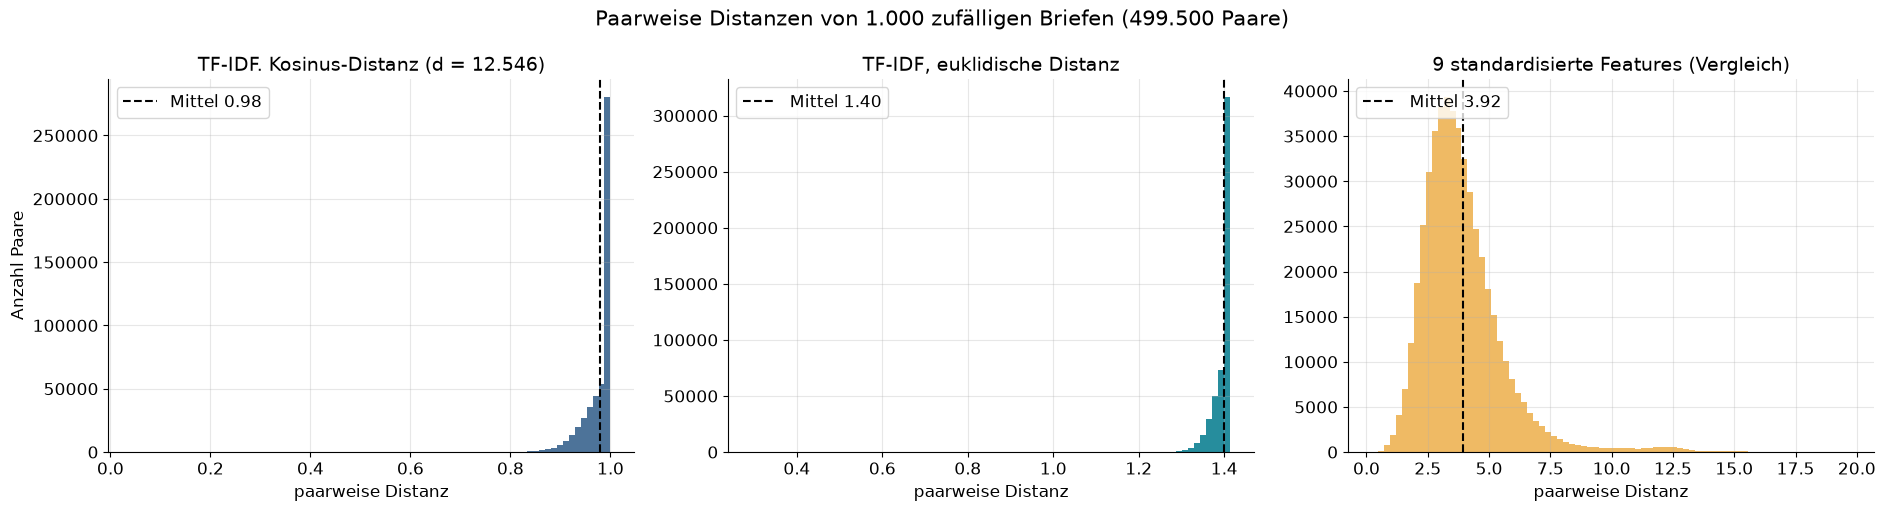

In [13]:
rng = np.random.default_rng(RANDOM_STATE)
samp = rng.choice(X_all.shape[0], 1000, replace=False)
Xs = X_all[samp].toarray()
d_cos = pdist(Xs, "cosine")
d_euc = pdist(Xs, "euclidean")
d_feat = pdist(Xz[samp], "euclidean")
real_tab = pd.DataFrame({
    "Dimension": [X_all.shape[1], X_all.shape[1], Xz.shape[1]],
    "Mittelwert": [d_cos.mean(), d_euc.mean(), d_feat.mean()],
    "Std/Mittelwert": [d_cos.std() / d_cos.mean(), d_euc.std() / d_euc.mean(), d_feat.std() / d_feat.mean()],
    "(max-min)/min": [(d.max() - d.min()) / d[d > 0].min() for d in (d_cos, d_euc, d_feat)],
    "Anteil Distanzen > 0,9·max %": [100 * (d > 0.9 * d.max()).mean() for d in (d_cos, d_euc, d_feat)],
}, index=["TF-IDF Kosinus", "TF-IDF euklidisch", "9 Features euklidisch"])
display(real_tab.round(3))

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
for ax, d, ttl, c in [(axes[0], d_cos, f"TF-IDF, Kosinus-Distanz (d = {X_all.shape[1]:,})".replace(",", "."), PALETTE["main"]),
                      (axes[1], d_euc, "TF-IDF, euklidische Distanz", PALETTE["teal"]),
                      (axes[2], d_feat, "9 standardisierte Features (Vergleich)", PALETTE["accent"])]:
    ax.hist(d, bins=80, color=c, alpha=0.85)
    ax.axvline(d.mean(), color="black", ls="--", lw=1.5, label=f"Mittel {d.mean():.2f}")
    ax.set_title(ttl)
    ax.set_xlabel("paarweise Distanz")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Anzahl Paare")
fig.suptitle("Paarweise Distanzen von 1.000 zufälligen Briefen (499.500 Paare)")
fig.tight_layout()
save_fig(fig, "curse_of_dimensionality_tfidf", FIG)
plt.show()
STATS["curse_real_data"] = real_tab.round(4).to_dict("index")

**Interpretation:** Die mittlere Kosinus-Distanz zwischen zwei Briefen liegt bei 0,978, Std/Mittelwert bei nur 0,033, und 97 % aller Paare liegen über 90 % der Maximaldistanz. Im TF-IDF-Raum ist also fast jeder Brief von fast jedem gleich weit entfernt. Im 9-Feature-Raum sind die Distanzen dagegen breit gestreut (Std/Mittelwert 0,44). Für Clustering und distanzbasierte Outlier-Verfahren heißt das: Auf der rohen TF-IDF-Matrix fehlt der Distanzkontrast. Vorher sollte man reduzieren (z. B. auf 50 SVD-Komponenten).

## Teil D – Linear vs. nichtlinear auf TF-IDF  *[Vorlesung „Projections & Encoders“]*

### 11. TruncatedSVD / LSA  *[Erweiterung]*

Klassische PCA zentriert die Daten. Eine zentrierte TF-IDF-Matrix ist aber nicht mehr dünnbesetzt: 3.800 × mehrere Tausend
dichte Einträge, die Struktur der Matrix geht verloren. **TruncatedSVD** (Latent Semantic Analysis) zerlegt die Matrix ohne Zentrierung.
Sie ist für L2-normierte TF-IDF-Vektoren die übliche „PCA für Text“. Es werden 100 Komponenten berechnet.

,alle Sprachen (erkl. Var. %),nur Italienisch (erkl. Var. %)
2 Komp.,2.36,2.03
10 Komp.,6.40,6.61
50 Komp.,13.16,16.05
100 Komp.,18.52,24.05


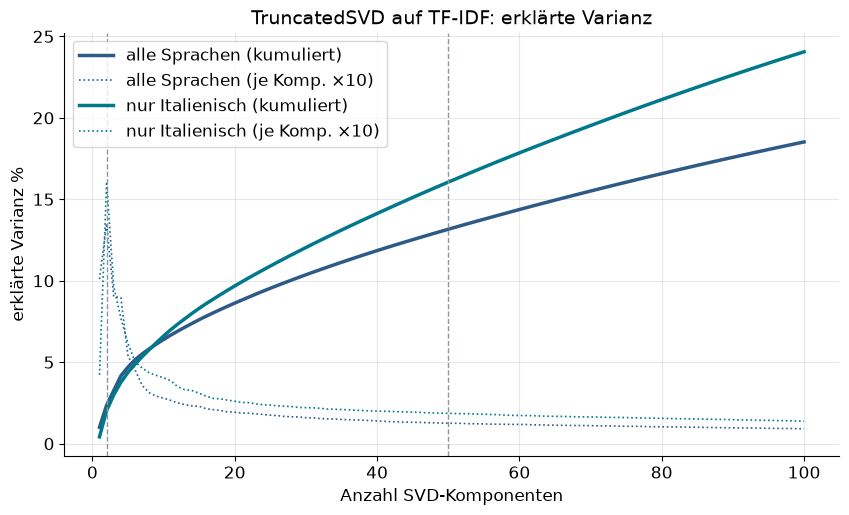

In [14]:
from sklearn.decomposition import TruncatedSVD

def run_svd(X, name):
    t0 = time.perf_counter()
    svd = TruncatedSVD(n_components=100, algorithm="randomized", n_iter=7, random_state=RANDOM_STATE)
    Z = svd.fit_transform(X)
    rt = time.perf_counter() - t0
    np.save(PROJ / f"svd100_{name}.npy", Z)
    return svd, Z, rt

svd_all, Z_all, rt_svd_all = run_svd(X_all, "all")
svd_it, Z_it, rt_svd_it = run_svd(X_it, "italian")
svd_ev = pd.DataFrame({k: [100 * s.explained_variance_ratio_[:n].sum() for n in (2, 10, 50, 100)]
                       for k, s in [("alle Sprachen", svd_all), ("nur Italienisch", svd_it)]},
                      index=["2 Komp.", "10 Komp.", "50 Komp.", "100 Komp."])
display(svd_ev.round(2).rename(lambda c: c + " (erkl. Var. %)", axis=1))

fig, ax = plt.subplots(figsize=(10, 5.5))
for s, lbl, c in [(svd_all, "alle Sprachen", PALETTE["main"]), (svd_it, "nur Italienisch", PALETTE["teal"])]:
    ax.plot(np.arange(1, 101), 100 * np.cumsum(s.explained_variance_ratio_), lw=2.5, color=c, label=f"{lbl} (kumuliert)")
    ax.plot(np.arange(1, 101), 100 * s.explained_variance_ratio_ * 10, lw=1.2, ls=":", color=c, label=f"{lbl} (je Komp. ×10)")
for n in (2, 50):
    ax.axvline(n, color=PALETTE["grey"], ls="--", lw=1)
ax.set_xlabel("Anzahl SVD-Komponenten")
ax.set_ylabel("erklärte Varianz %")
ax.set_title("TruncatedSVD auf TF-IDF: erklärte Varianz")
ax.legend()
save_fig(fig, "svd_explained_variance", FIG)
plt.show()
STATS["svd_explained_variance_pct"] = {"all": dict(zip(["2", "10", "50", "100"], svd_ev["alle Sprachen"].round(3))),
                                       "italian": dict(zip(["2", "10", "50", "100"], svd_ev["nur Italienisch"].round(3)))}

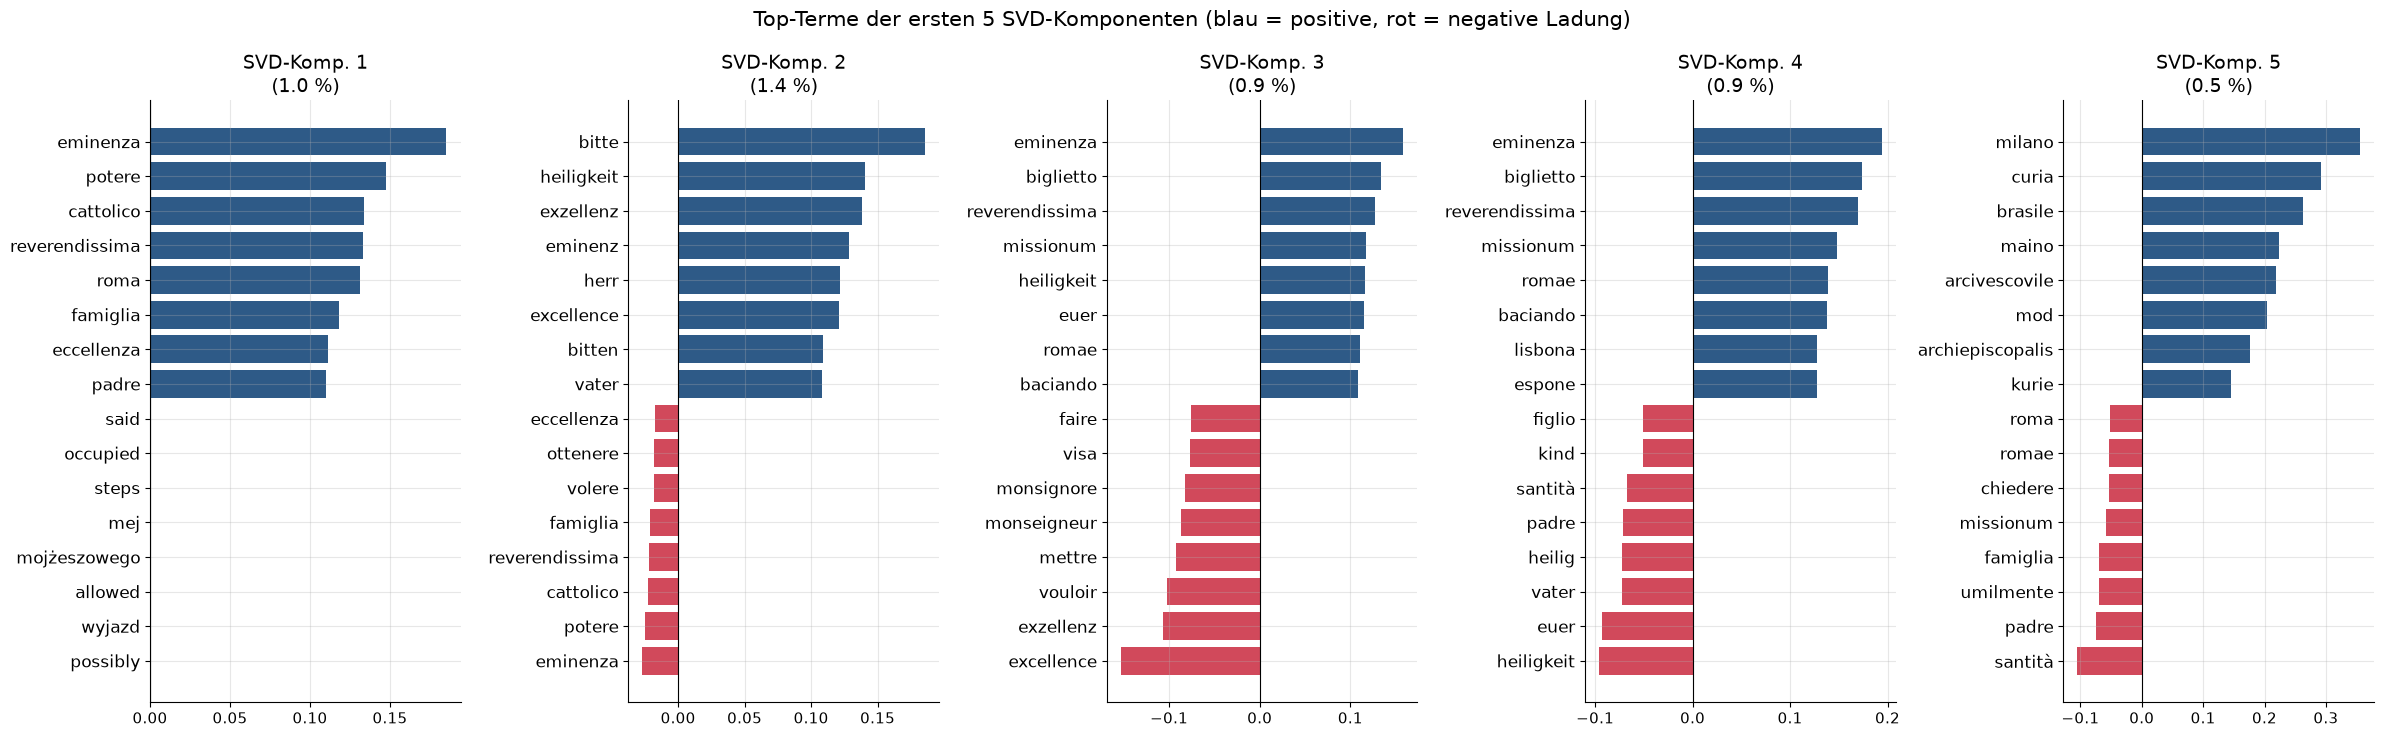

,Komponente,positiv,negativ
0,1,"eminenza, potere, cattolico, reverendissima, roma, famiglia, eccellenza, padre","possibly, wyjazd, allowed, mojżeszowego, mej, steps, occupied, said"
1,2,"bitte, heiligkeit, exzellenz, eminenz, herr, excellence, bitten, vater","eminenza, potere, cattolico, reverendissima, famiglia, volere, ottenere, eccellenza"
2,3,"eminenza, biglietto, reverendissima, missionum, heiligkeit, euer, romae, baciando","excellence, exzellenz, vouloir, mettre, monseigneur, monsignore, visa, faire"
3,4,"eminenza, biglietto, reverendissima, missionum, romae, baciando, lisbona, espone","heiligkeit, euer, vater, heilig, padre, santità, kind, figlio"
4,5,"milano, curia, brasile, maino, arcivescovile, mod, archiepiscopalis, kurie","santità, padre, umilmente, famiglia, missionum, chiedere, romae, roma"


In [15]:
terms = vec_all.get_feature_names_out()
NT = 8
fig, axes = plt.subplots(1, 5, figsize=(24, 7.5))
rows = []
for k, ax in enumerate(axes):
    comp = svd_all.components_[k]
    pos = np.argsort(comp)[::-1][:NT]
    neg = np.argsort(comp)[:NT]
    sel = list(pos) + list(neg[::-1])
    vals = comp[sel]
    ax.barh(range(len(sel)), vals, color=[PALETTE["main"] if v > 0 else PALETTE["outlier"] for v in vals])
    ax.set_yticks(range(len(sel)), [terms[i] for i in sel])
    ax.invert_yaxis()
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"SVD-Komp. {k+1}\n({100 * svd_all.explained_variance_ratio_[k]:.1f} %)")
    ax.tick_params(axis="x", labelsize=11)
    rows.append({"Komponente": k + 1, "positiv": ", ".join(terms[i] for i in pos),
                 "negativ": ", ".join(terms[i] for i in neg)})
fig.suptitle("Top-Terme der ersten 5 SVD-Komponenten (blau = positive, rot = negative Ladung)")
fig.tight_layout()
save_fig(fig, "svd_top_terms", FIG)
plt.show()
top_terms = pd.DataFrame(rows)
top_terms.to_csv(RES / "svd_top_terms.csv", index=False)
display(top_terms)

**Interpretation:** Zwei Komponenten erklären nur 2,4 % der Varianz, 50 Komponenten 13 %, 100 Komponenten 18,5 %. Die Textvarianz verteilt sich also auf sehr viele Richtungen. Die ersten Komponenten bilden vor allem **Sprache** ab: Komp. 1 italienische Anredeformeln (eminenza, reverendissima) gegen englisch/polnisch, Komp. 2 deutsch (bitte, heiligkeit) gegen italienisch. Danach folgen **Korrespondenz-Serien**: Komp. 3/4 Formularbriefe um Fahrkarten und den St. Raphaels-Verein (biglietto, raphaelsverein, lisbona) gegen persönliche Bittbriefe (padre, figlio, santità, razza), Komp. 5 die Mailänder Kurie und Brasilien-Visa (milano, curia, brasile).

### 12. PCA-2D (erste zwei SVD-Komponenten)

**Vorlesung:** PCA ist linear und deterministisch, erhält globale Struktur und bietet ein explizites Mapping. Lokale Nachbarschaften bleiben aber nicht erhalten.

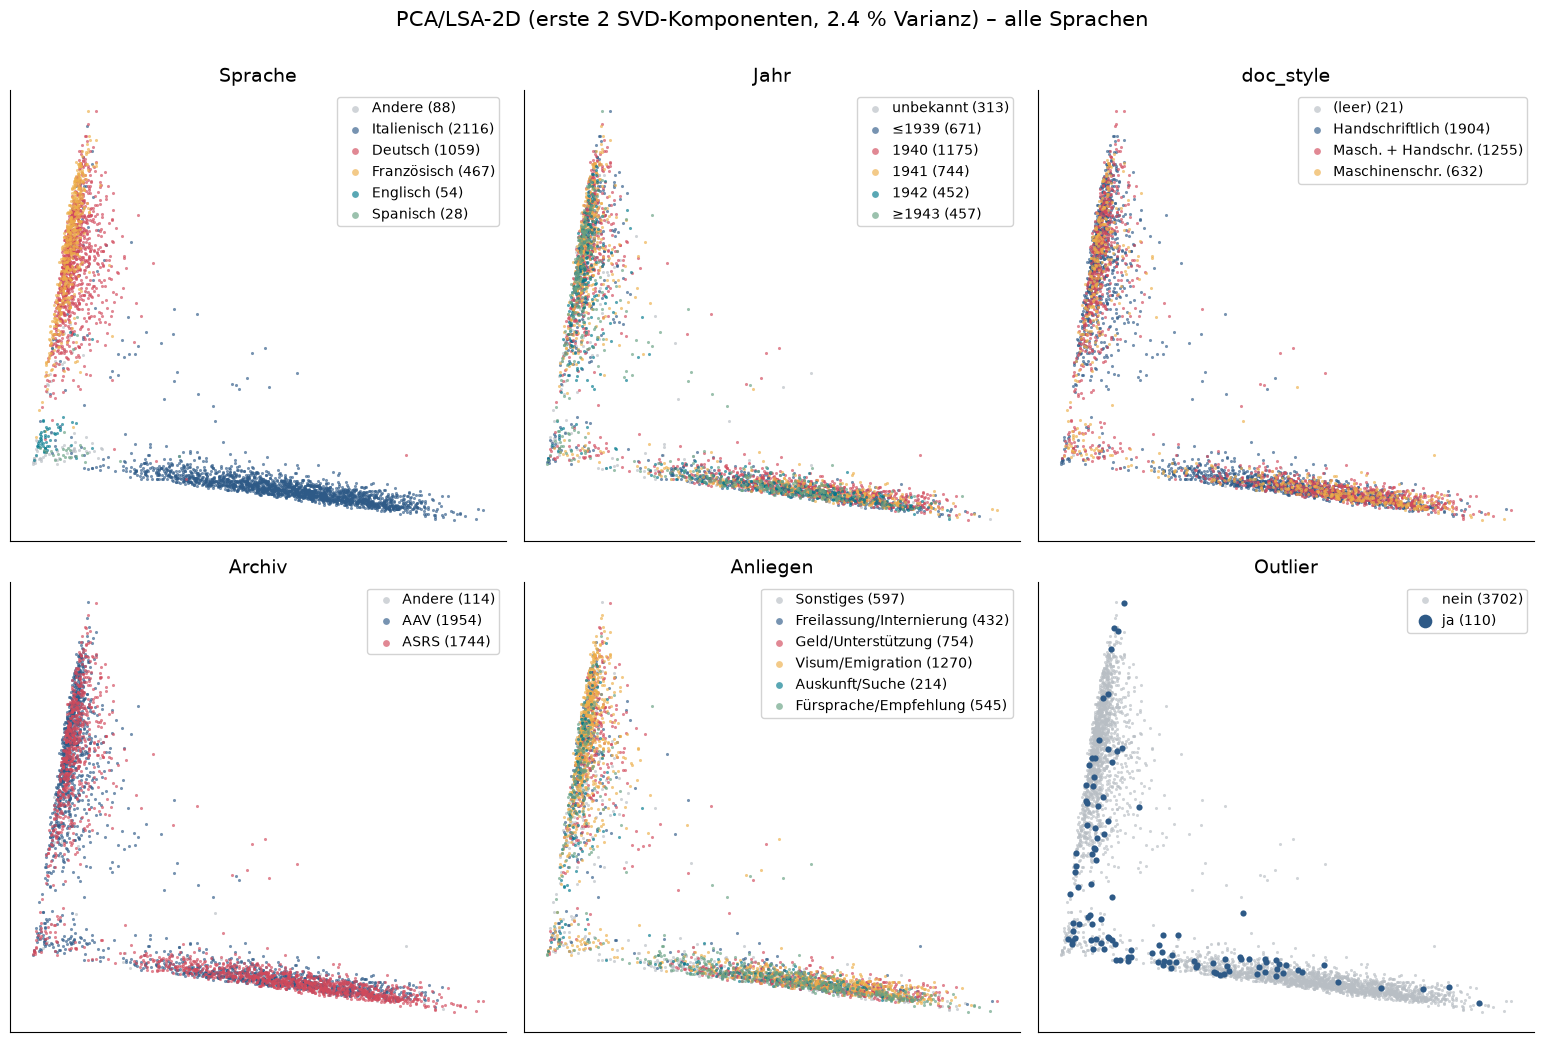

In [16]:
Y_pca_all = Z_all[:, :2]
np.save(PROJ / "pca2d_all.npy", Y_pca_all)
fig = D.plot_projection(Y_pca_all, COLORS, f"PCA/LSA-2D (erste 2 SVD-Komponenten, {svd_ev.loc['2 Komp.', 'alle Sprachen']:.1f} % Varianz) – alle Sprachen",
                        orders=ORDERS)
save_fig(fig, "projection_pca_all", FIG)
plt.show()

**Interpretation:** Die PCA/LSA-Projektion bildet einen Keil: Italienische Briefe ziehen sich entlang des einen Arms, deutsche und französische entlang des anderen. Kurze, unspezifische Briefe liegen an der Spitze nahe dem Ursprung. Bei nur 2,4 % erklärter Varianz ist der Plot eine grobe globale Übersicht, keine Nachbarschaftskarte.

### 13. t-SNE

t-SNE läuft auf den **ersten 50 SVD-Komponenten** und nicht auf der rohen TF-IDF-Matrix. Das ist die übliche Vorstufe
(van der Maaten & Hinton): Sie entfernt Rauschen aus den kleinen Komponenten, und die $O(N^2)$-Distanzberechnung wird auf 50 statt mehreren
Tausend Dimensionen deutlich schneller.

Untersucht werden: Perplexity ∈ {5, 30, 50, 100} (Init `pca`), Initialisierung `random` vs. `pca` bei Perplexity 30 und 3 Seeds bei
zufälliger Initialisierung (Stochastizität).

> **Warnung (Vorlesung, Wattenberg et al. 2016):** Clustergrößen und Abstände **zwischen** Clustern sind in t-SNE-Plots nicht
> interpretierbar. Nur die Nachbarschaft innerhalb eines Clusters ist aussagekräftig.

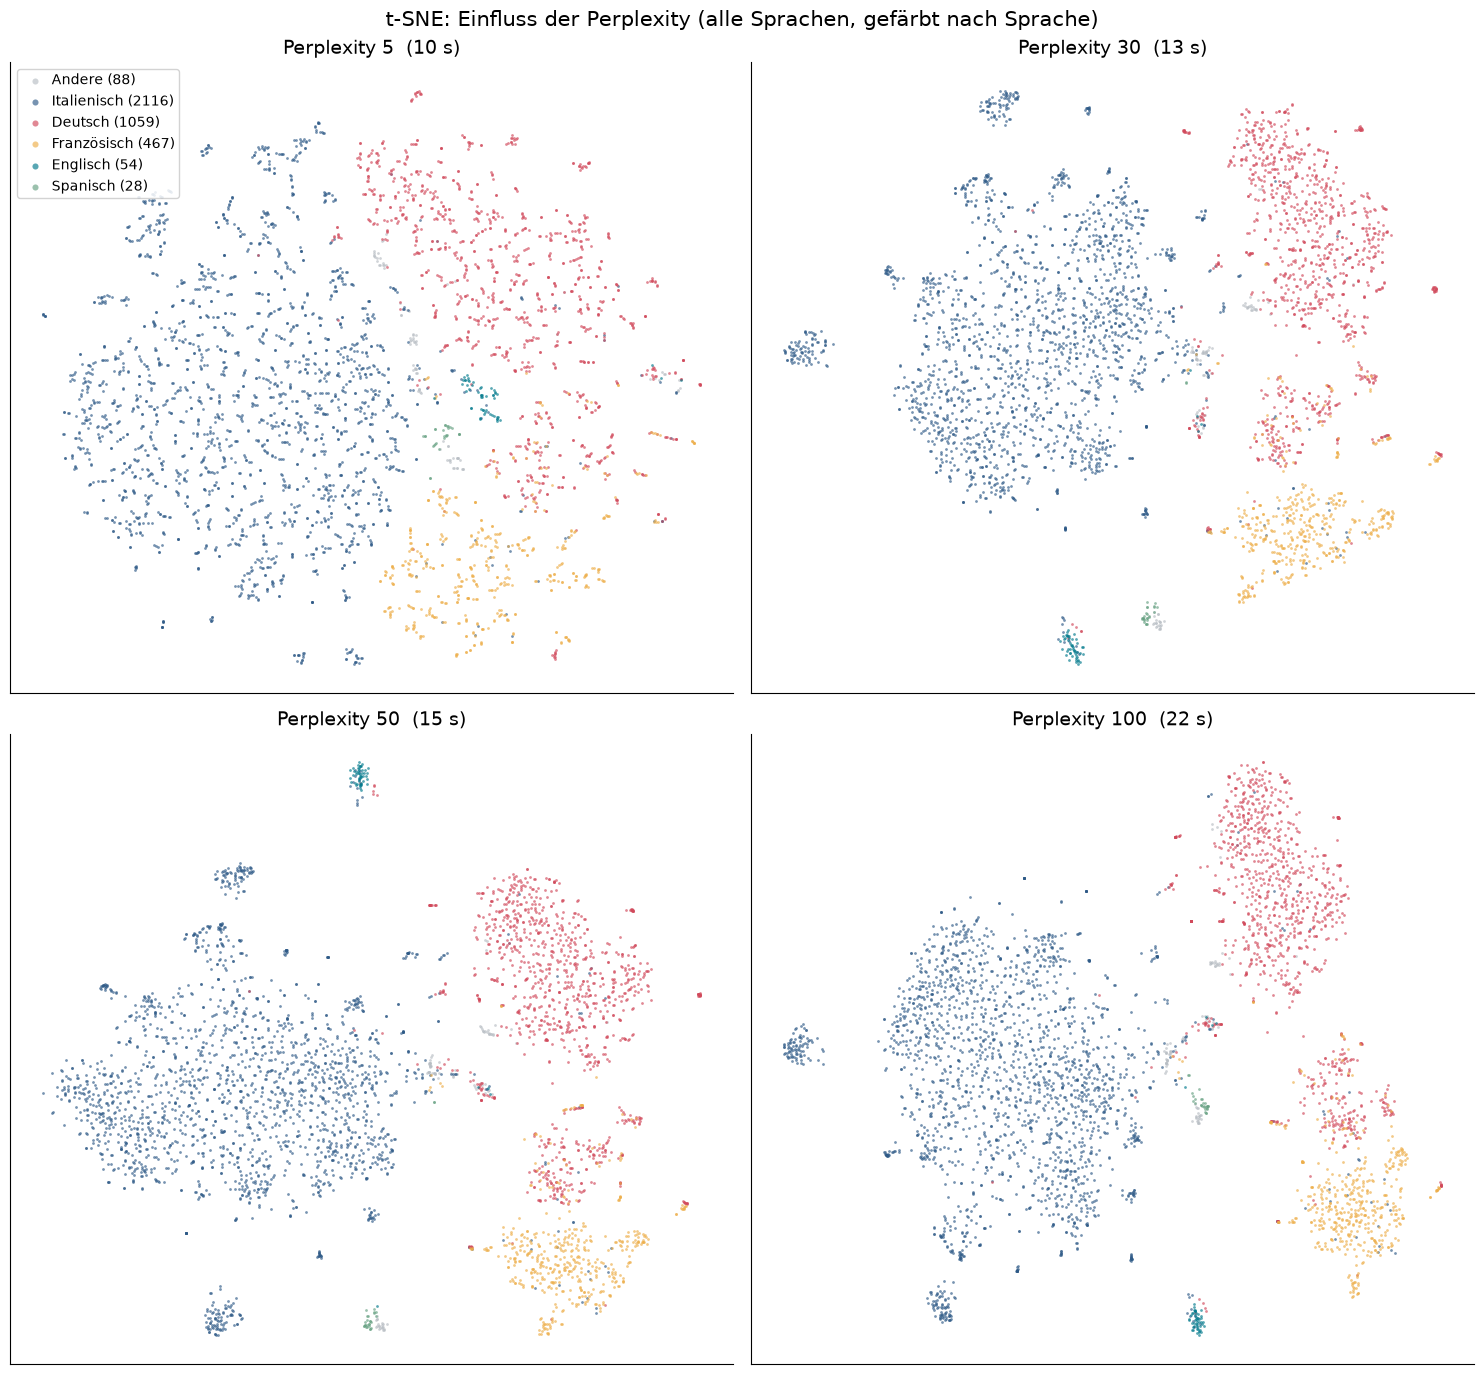

In [17]:
from sklearn.manifold import TSNE

def tsne(X, name, perplexity=30, init="pca", seed=RANDOM_STATE):
    return D.cached_projection(PROJ / f"tsne_{name}_p{perplexity}_{init}_s{seed}.npy",
                               lambda: TSNE(n_components=2, perplexity=perplexity, init=init,
                                            learning_rate="auto", random_state=seed).fit_transform(X), force=REBUILD)

X50_all = Z_all[:, :50]
PERPS = [5, 30, 50, 100]
ts_grid = {p: tsne(X50_all, "all", p) for p in PERPS}
fig, axes = plt.subplots(2, 2, figsize=(15, 14))
for ax, p in zip(axes.ravel(), PERPS):
    D.scatter_by(ax, ts_grid[p][0], COLORS["Sprache"], s=4, legend=(p == 5))
    ax.set_title(f"Perplexity {p}  ({ts_grid[p][1]:.0f} s)")
fig.suptitle("t-SNE: Einfluss der Perplexity (alle Sprachen, gefärbt nach Sprache)")
fig.tight_layout()
save_fig(fig, "tsne_perplexity_grid", FIG)
plt.show()

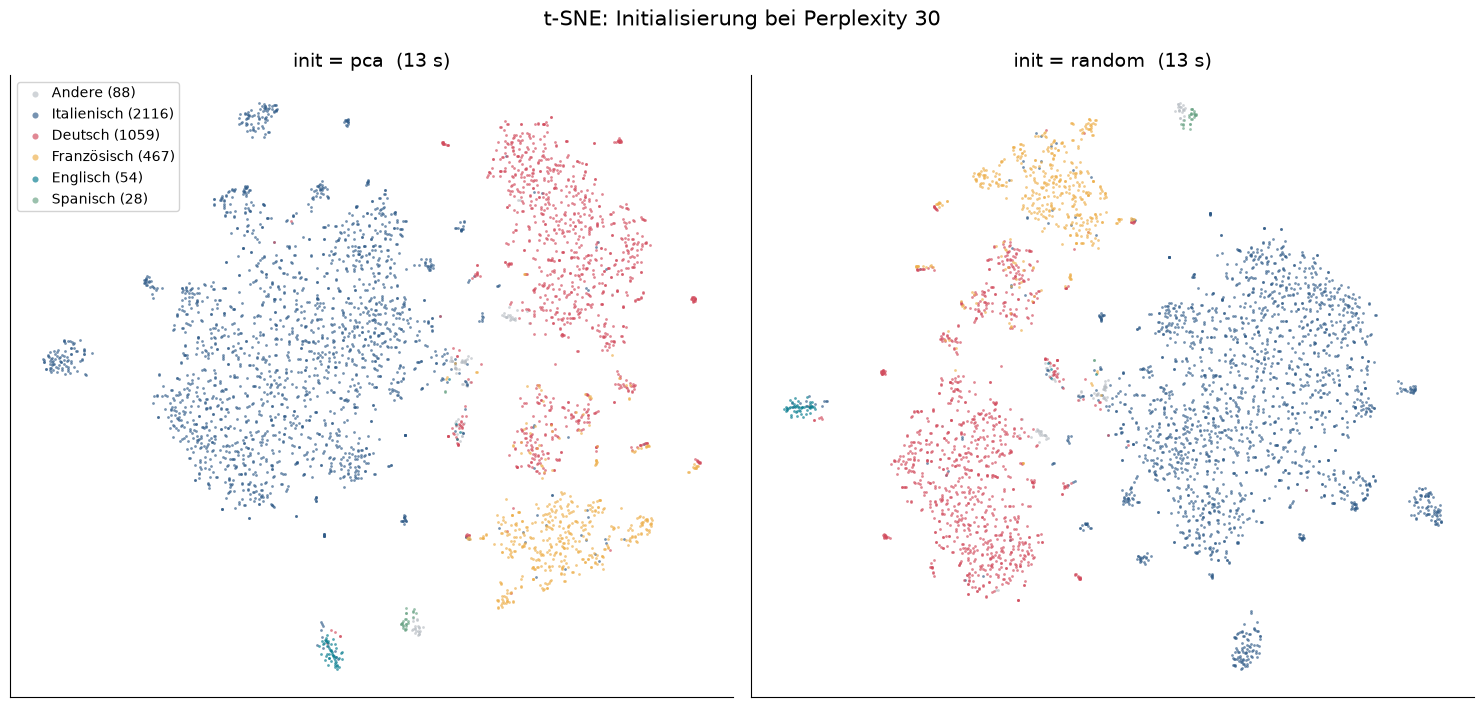

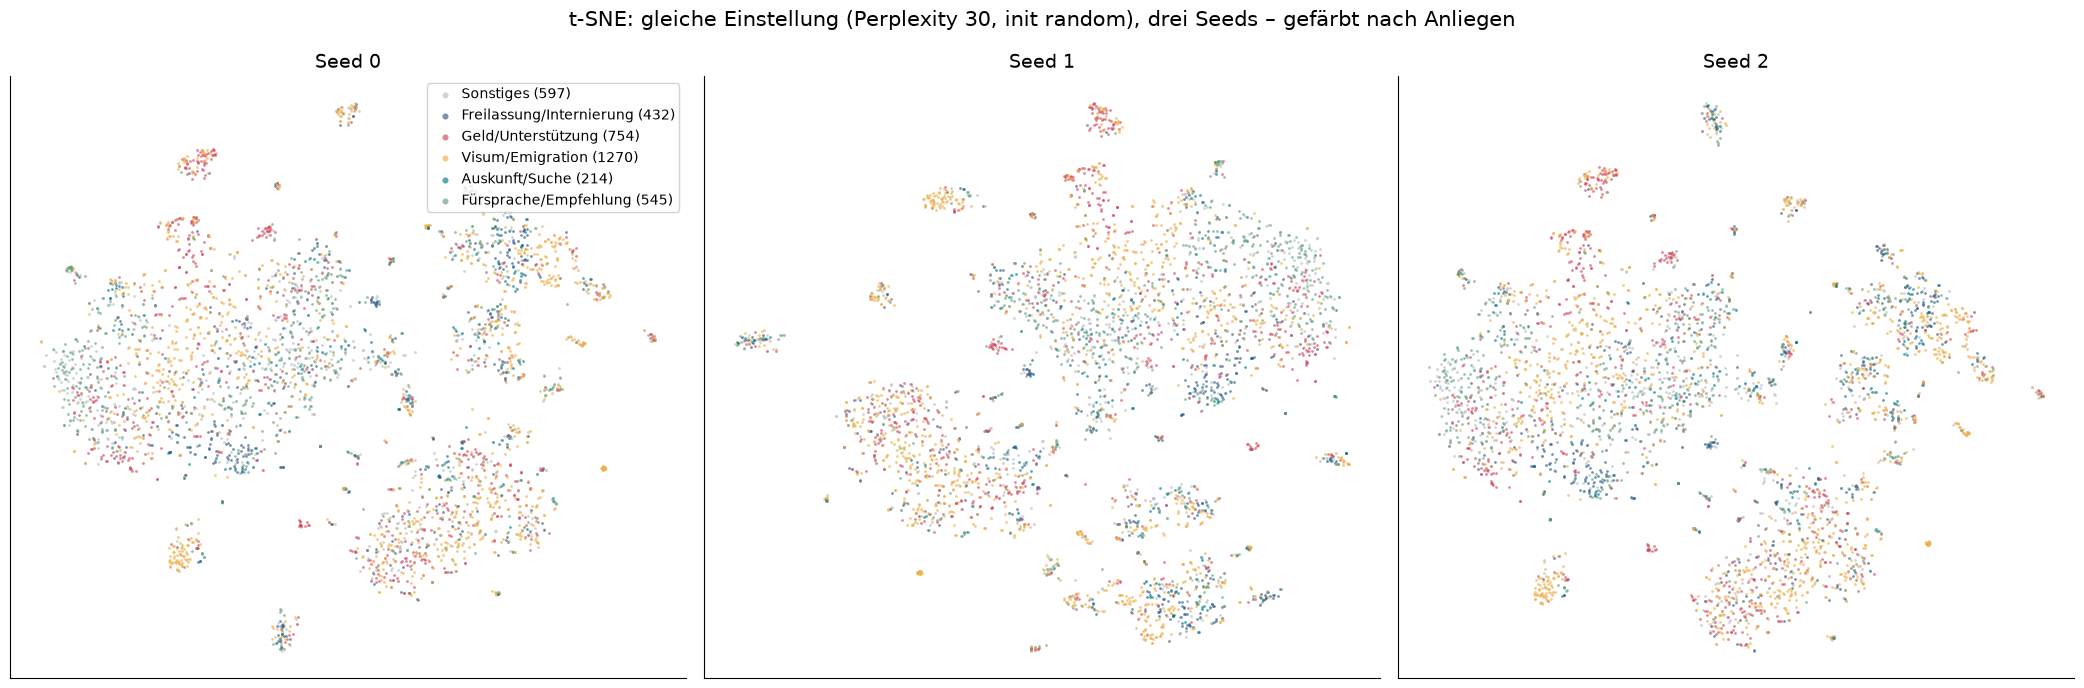

Procrustes-Disparität zwischen Seeds (0 = identisch bis auf Drehung/Skalierung, 1 = völlig verschieden): {'0 vs 1': np.float64(0.495), '0 vs 2': np.float64(0.177), '1 vs 2': np.float64(0.589)}


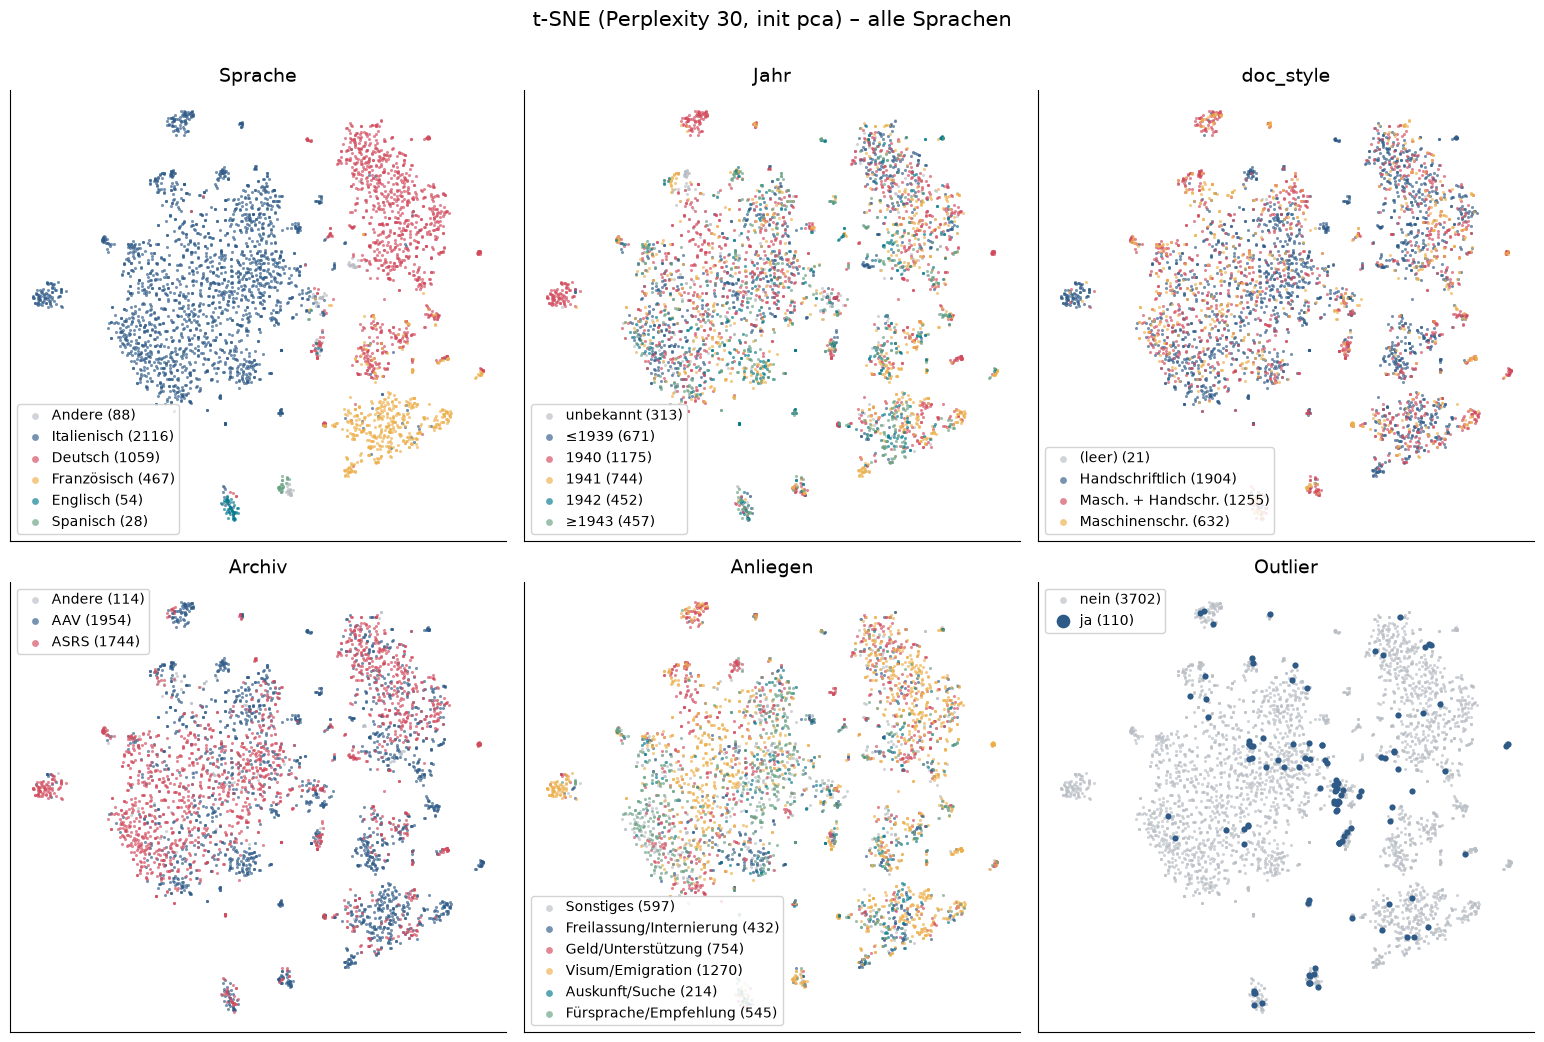

In [18]:
ts_rand = tsne(X50_all, "all", 30, "random")
fig, axes = plt.subplots(1, 2, figsize=(15, 7.2))
for ax, (Y, rt), ttl in [(axes[0], ts_grid[30], "init = pca"), (axes[1], ts_rand, "init = random")]:
    D.scatter_by(ax, Y, COLORS["Sprache"], s=4, legend=(ttl == "init = pca"))
    ax.set_title(f"{ttl}  ({rt:.0f} s)")
fig.suptitle("t-SNE: Initialisierung bei Perplexity 30")
fig.tight_layout()
save_fig(fig, "tsne_init_comparison", FIG)
plt.show()

seeds = {s: tsne(X50_all, "all", 30, "random", s) for s in (0, 1, 2)}
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, s in zip(axes, seeds):
    D.scatter_by(ax, seeds[s][0], COLORS["Anliegen"], order=ORDERS["Anliegen"], s=4, legend=(s == 0))
    ax.set_title(f"Seed {s}")
fig.suptitle("t-SNE: gleiche Einstellung (Perplexity 30, init random), drei Seeds – gefärbt nach Anliegen")
fig.tight_layout()
save_fig(fig, "tsne_seeds", FIG)
plt.show()
from scipy.spatial import procrustes
disp = {f"{a} vs {b}": procrustes(seeds[a][0], seeds[b][0])[2] for a, b in [(0, 1), (0, 2), (1, 2)]}
print("Procrustes-Disparität zwischen Seeds (0 = identisch bis auf Drehung/Skalierung, 1 = völlig verschieden):",
      {k: round(v, 3) for k, v in disp.items()})
STATS["tsne_seed_procrustes_disparity"] = {k: round(float(v), 4) for k, v in disp.items()}

Y_tsne_all, rt_tsne_all = ts_grid[30]
fig = D.plot_projection(Y_tsne_all, COLORS, "t-SNE (Perplexity 30, init pca) – alle Sprachen", orders=ORDERS)
save_fig(fig, "projection_tsne_all", FIG)
plt.show()

**Interpretation:** Perplexity 5 zersplittert die Daten in viele kleine Gruppen. Ab 30 entstehen zusammenhängende Sprachinseln mit kleinen Satelliten, bei 100 sind die Inseln glatter und runder. Die Seeds verschieben Lage und Form der Inseln stark (Procrustes-Disparität 0,18–0,59). Die Zerlegung in Sprachinseln bleibt aber gleich. Deshalb: Clustergrößen und Abstände zwischen den Inseln nicht deuten.

### 14. UMAP

UMAP läuft auf denselben 50 SVD-Komponenten mit `metric = 'cosine'`. Variiert werden:
- `n_neighbors` ∈ {5, 15, 50, 200} (lokale vs. globale Sicht) × `min_dist` ∈ {0.0, 0.1, 0.5} (Kompaktheit),
- Initialisierung `spectral` vs. `random`. Kobak & Linderman (2021, in der Vorlesung zitiert) zeigen, dass die bessere globale Struktur
  von UMAP vor allem an der Initialisierung liegt.
- `transform()`: UMAP wird auf 80 % gefittet, die restlichen 20 % werden nachträglich hineinprojiziert. Diese explizite Abbildung fehlt t-SNE.

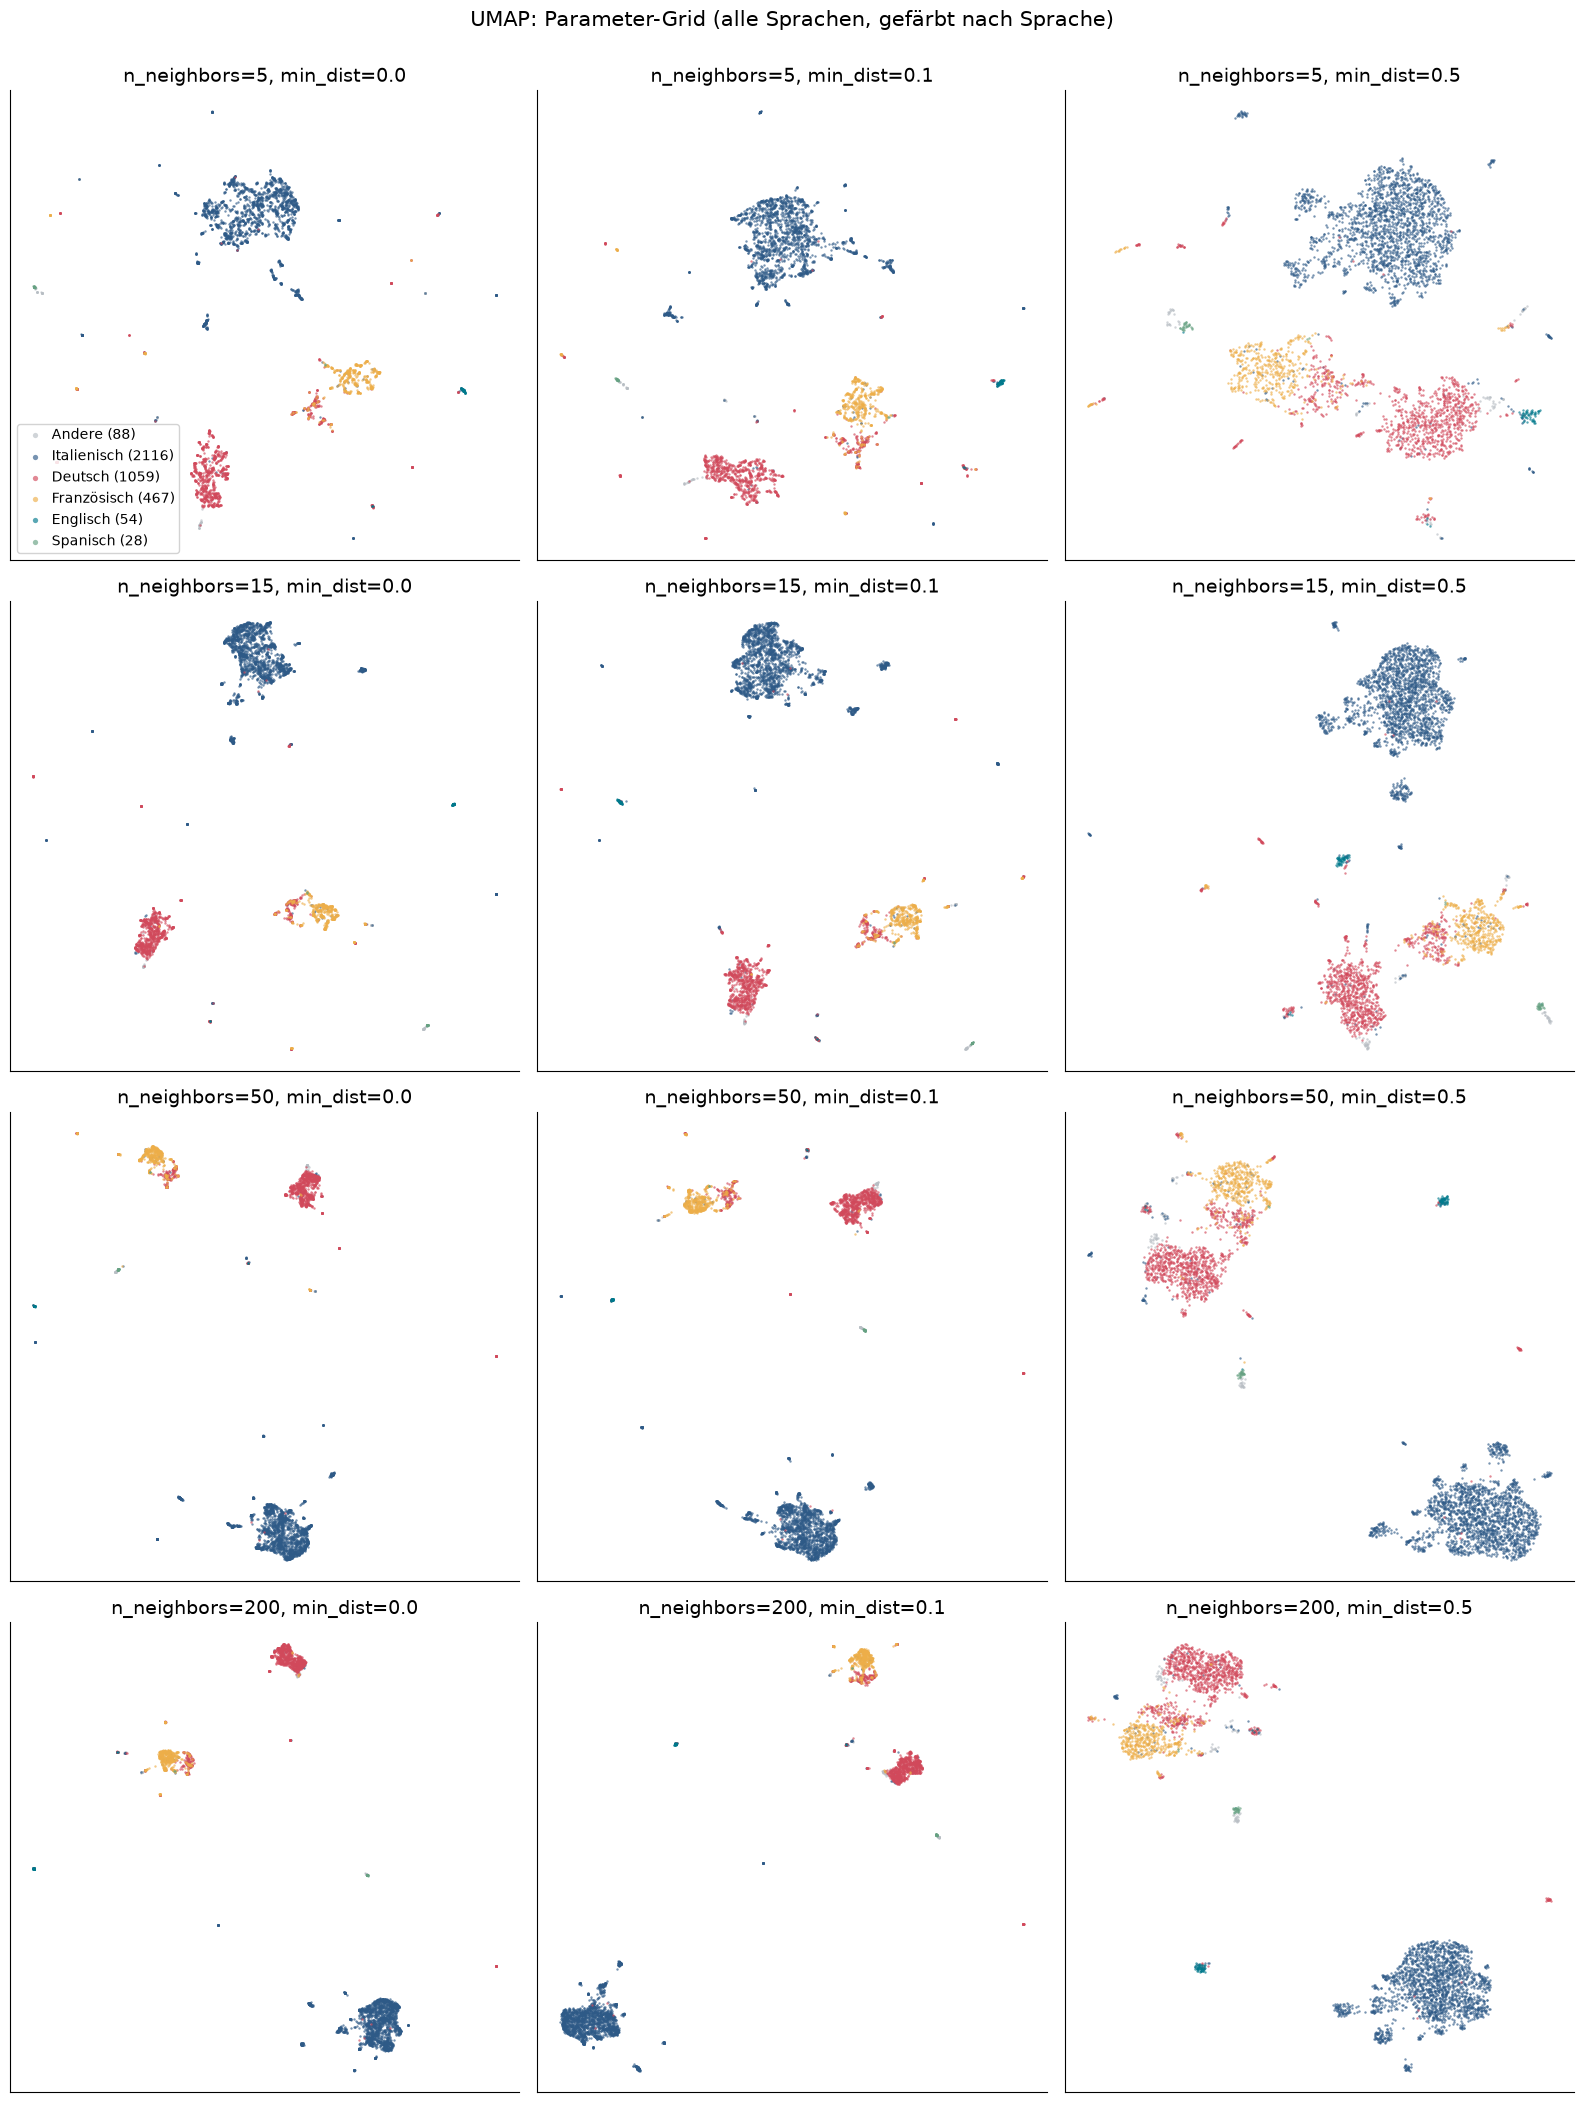

In [19]:
import umap

def run_umap(X, name, nn=15, md_=0.1, init="spectral", seed=RANDOM_STATE):
    return D.cached_projection(PROJ / f"umap_{name}_nn{nn}_md{md_}_{init}.npy",
                               lambda: umap.UMAP(n_neighbors=nn, min_dist=md_, metric="cosine", init=init,
                                                 random_state=seed).fit_transform(X), force=REBUILD)

NNS, MDS = [5, 15, 50, 200], [0.0, 0.1, 0.5]
um_grid = {(nn, m): run_umap(X50_all, "all", nn, m) for nn in NNS for m in MDS}
fig, axes = plt.subplots(len(NNS), len(MDS), figsize=(16, 21))
for r, nn in enumerate(NNS):
    for c, m in enumerate(MDS):
        ax = axes[r, c]
        D.scatter_by(ax, um_grid[(nn, m)][0], COLORS["Sprache"], s=3, legend=(r == 0 and c == 0))
        ax.set_title(f"n_neighbors={nn}, min_dist={m}")
fig.suptitle("UMAP: Parameter-Grid (alle Sprachen, gefärbt nach Sprache)", y=1.0)
fig.tight_layout()
save_fig(fig, "umap_param_grid", FIG)
plt.show()

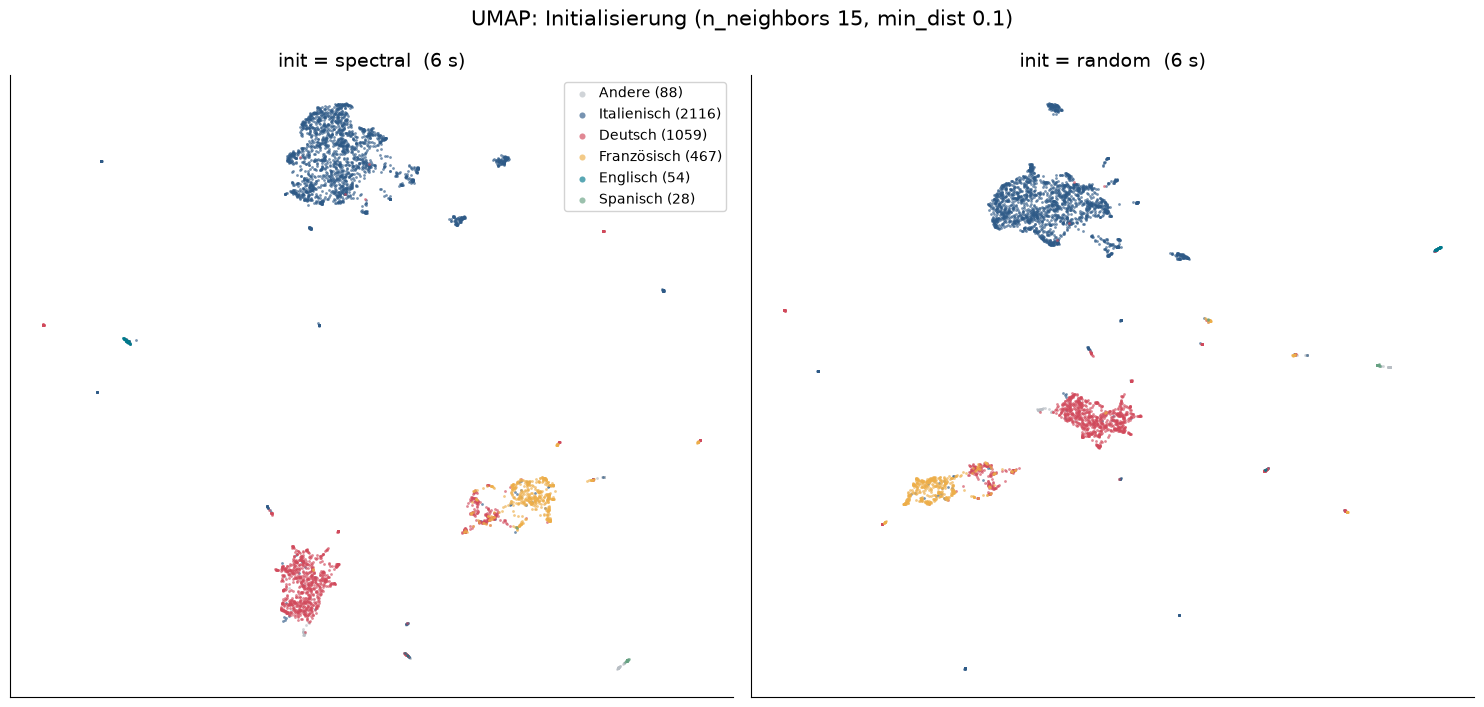

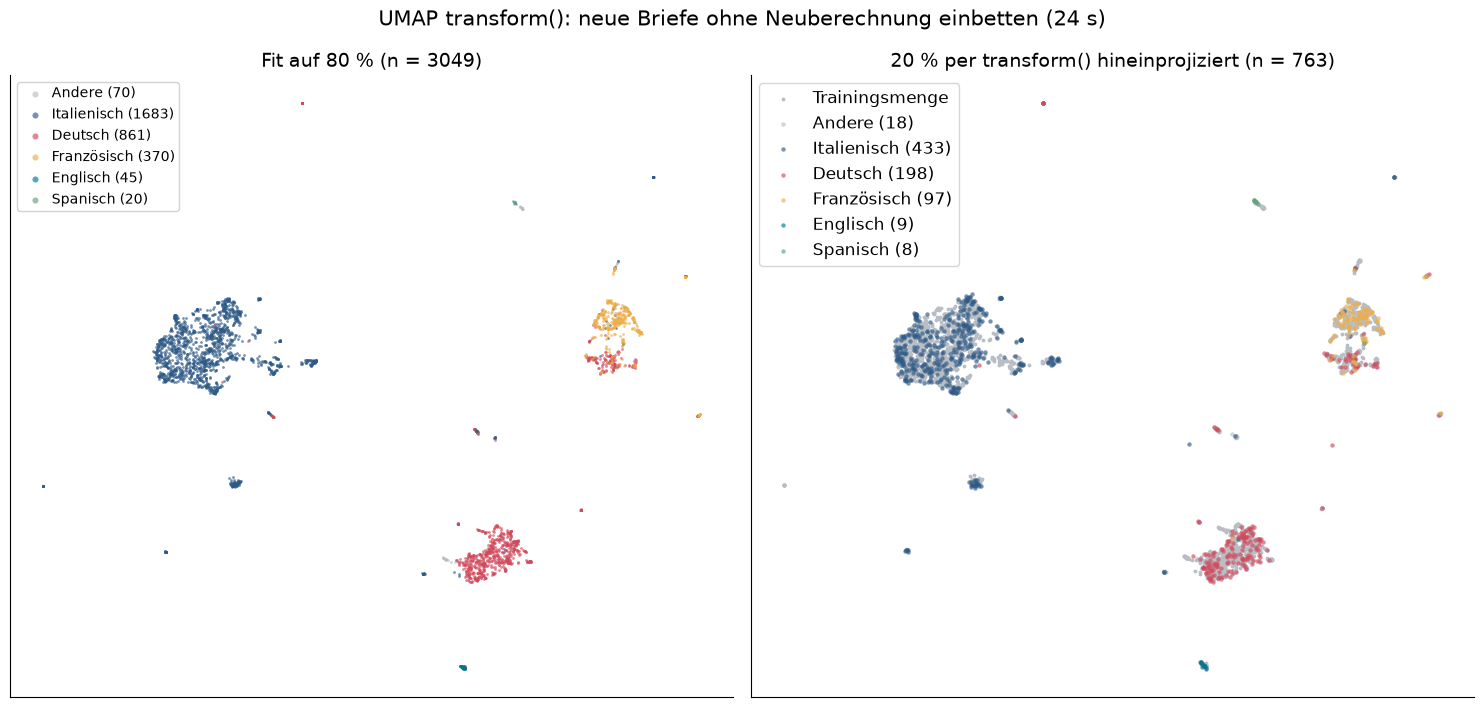

Sprache der 20 % per 10-NN in der 2D-Einbettung korrekt wiedergefunden: 95.5 %


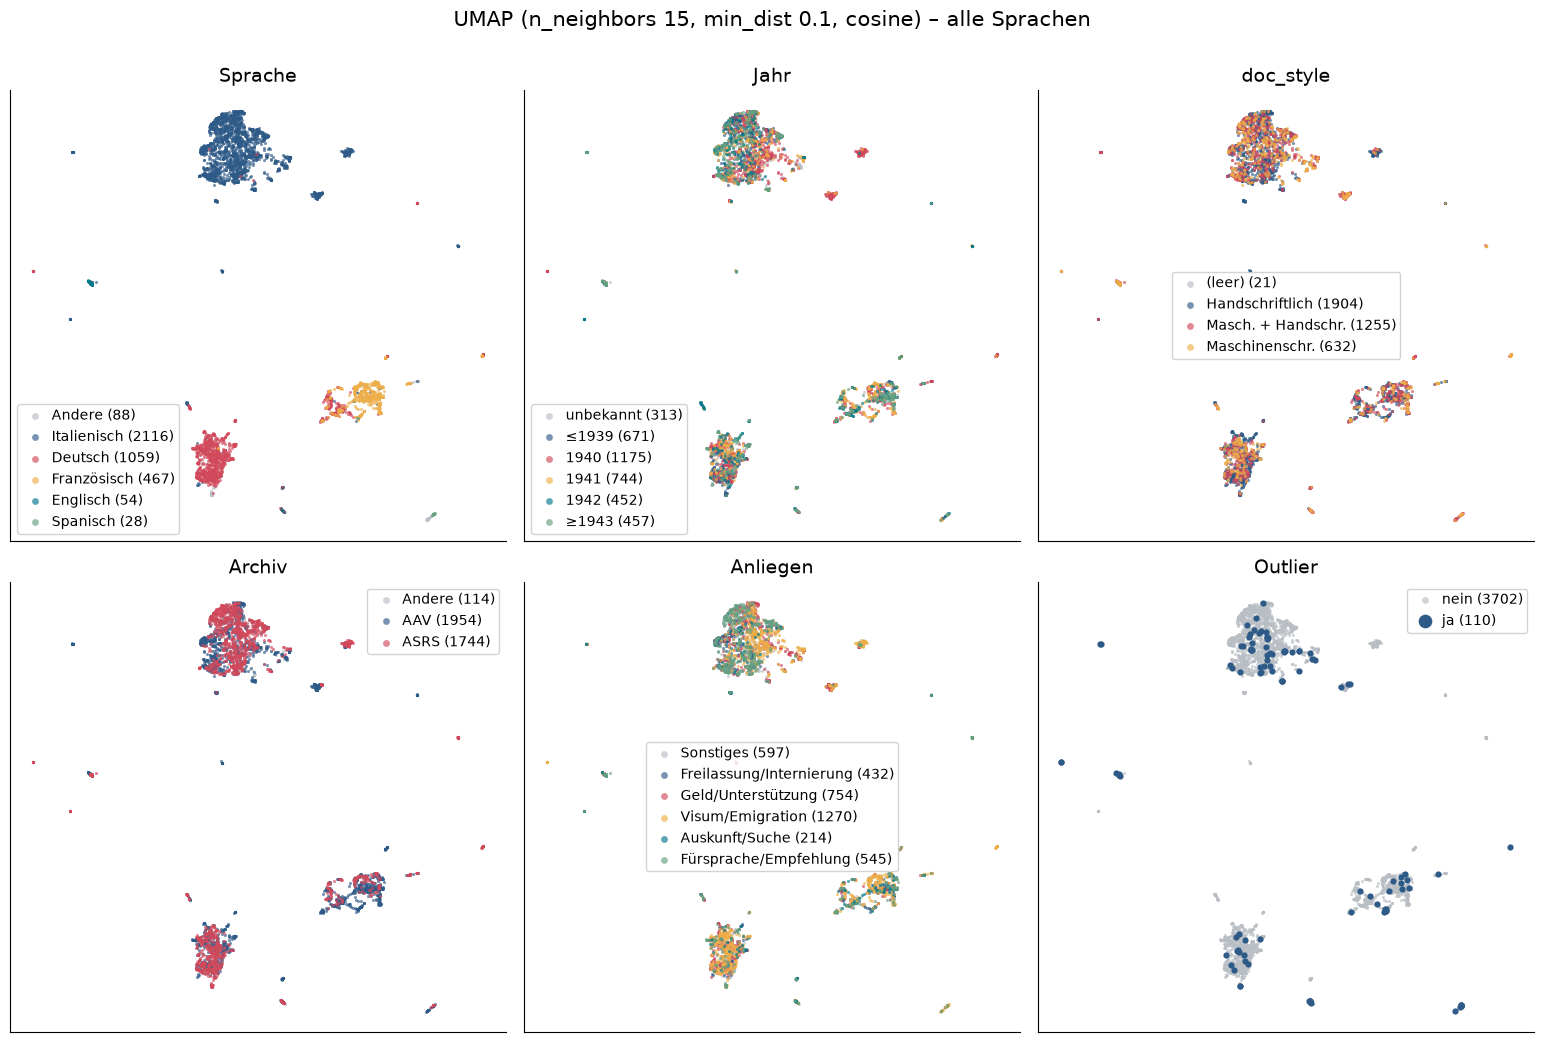

In [20]:
um_rand = run_umap(X50_all, "all", 15, 0.1, "random")
fig, axes = plt.subplots(1, 2, figsize=(15, 7.2))
for ax, (Y, rt), ttl in [(axes[0], um_grid[(15, 0.1)], "init = spectral"), (axes[1], um_rand, "init = random")]:
    D.scatter_by(ax, Y, COLORS["Sprache"], s=4, legend=(ttl == "init = spectral"))
    ax.set_title(f"{ttl}  ({rt:.0f} s)")
fig.suptitle("UMAP: Initialisierung (n_neighbors 15, min_dist 0.1)")
fig.tight_layout()
save_fig(fig, "umap_init_comparison", FIG)
plt.show()

# transform(): fit auf 80 %, Projektion der 20 %
rng = np.random.default_rng(RANDOM_STATE)
perm = rng.permutation(len(X50_all))
n_tr = int(0.8 * len(perm))
tr_idx, te_idx = perm[:n_tr], perm[n_tr:]
t0 = time.perf_counter()
um_tr = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=RANDOM_STATE).fit(X50_all[tr_idx])
Y_te = um_tr.transform(X50_all[te_idx])
rt_tf = time.perf_counter() - t0
fig, axes = plt.subplots(1, 2, figsize=(15, 7.2))
lab_tr = COLORS["Sprache"].iloc[tr_idx].reset_index(drop=True)
lab_te = COLORS["Sprache"].iloc[te_idx].reset_index(drop=True)
D.scatter_by(axes[0], um_tr.embedding_, lab_tr, s=4)
axes[0].set_title(f"Fit auf 80 % (n = {n_tr})")
axes[1].scatter(um_tr.embedding_[:, 0], um_tr.embedding_[:, 1], s=3, color=D.OTHER_COLOR, label="Trainingsmenge")
D.scatter_by(axes[1], Y_te, lab_te, s=10, legend=False)
axes[1].set_title(f"20 % per transform() hineinprojiziert (n = {len(te_idx)})")
axes[1].legend(loc="best")
fig.suptitle(f"UMAP transform(): neue Briefe ohne Neuberechnung einbetten ({rt_tf:.0f} s)")
fig.tight_layout()
save_fig(fig, "umap_transform", FIG)
plt.show()
# Wie gut landen Testbriefe bei Trainingsbriefen derselben Sprache?
from sklearn.neighbors import KNeighborsClassifier
knn_lang = KNeighborsClassifier(n_neighbors=10).fit(um_tr.embedding_, lab_tr)
acc_tf = (knn_lang.predict(Y_te) == lab_te).mean()
print(f"Sprache der 20 % per 10-NN in der 2D-Einbettung korrekt wiedergefunden: {100 * acc_tf:.1f} %")
STATS["umap_transform_language_knn_accuracy_pct"] = round(100 * float(acc_tf), 2)

Y_umap_all, rt_umap_all = um_grid[(15, 0.1)]
fig = D.plot_projection(Y_umap_all, COLORS, "UMAP (n_neighbors 15, min_dist 0.1, cosine) – alle Sprachen", orders=ORDERS)
save_fig(fig, "projection_umap_all", FIG)
plt.show()

**Interpretation:** Kleine n_neighbors erzeugen viele kleine Satelliten, große verbinden mehr. Mit min_dist 0,5 werden die Inseln breiter und füllen den Raum gleichmäßiger. In fast allen Einstellungen liegen Deutsch und Französisch nebeneinander, mit einer gemischten Brücke aus zweisprachiger Korrespondenz. Bei transform() landen 95,5 % der neu eingebetteten Briefe neben Trainingsbriefen derselben Sprache. Die explizite Abbildung funktioniert also.

### 15. PaCMAP  *[Erweiterung, nicht Vorlesung]*

PaCMAP (Wang et al. 2021) optimiert gleichzeitig drei Arten von Paaren: **Nah-Paare** (Nachbarn, anziehend), **Mittel-Paare**
(moderat entfernt, schwach anziehend) und **Fern-Paare** (zufällig, abstoßend). Die Gewichte ändern sich über die Iterationen.
Ziel ist, lokale **und** globale Struktur zugleich besser zu erhalten als t-SNE/UMAP.

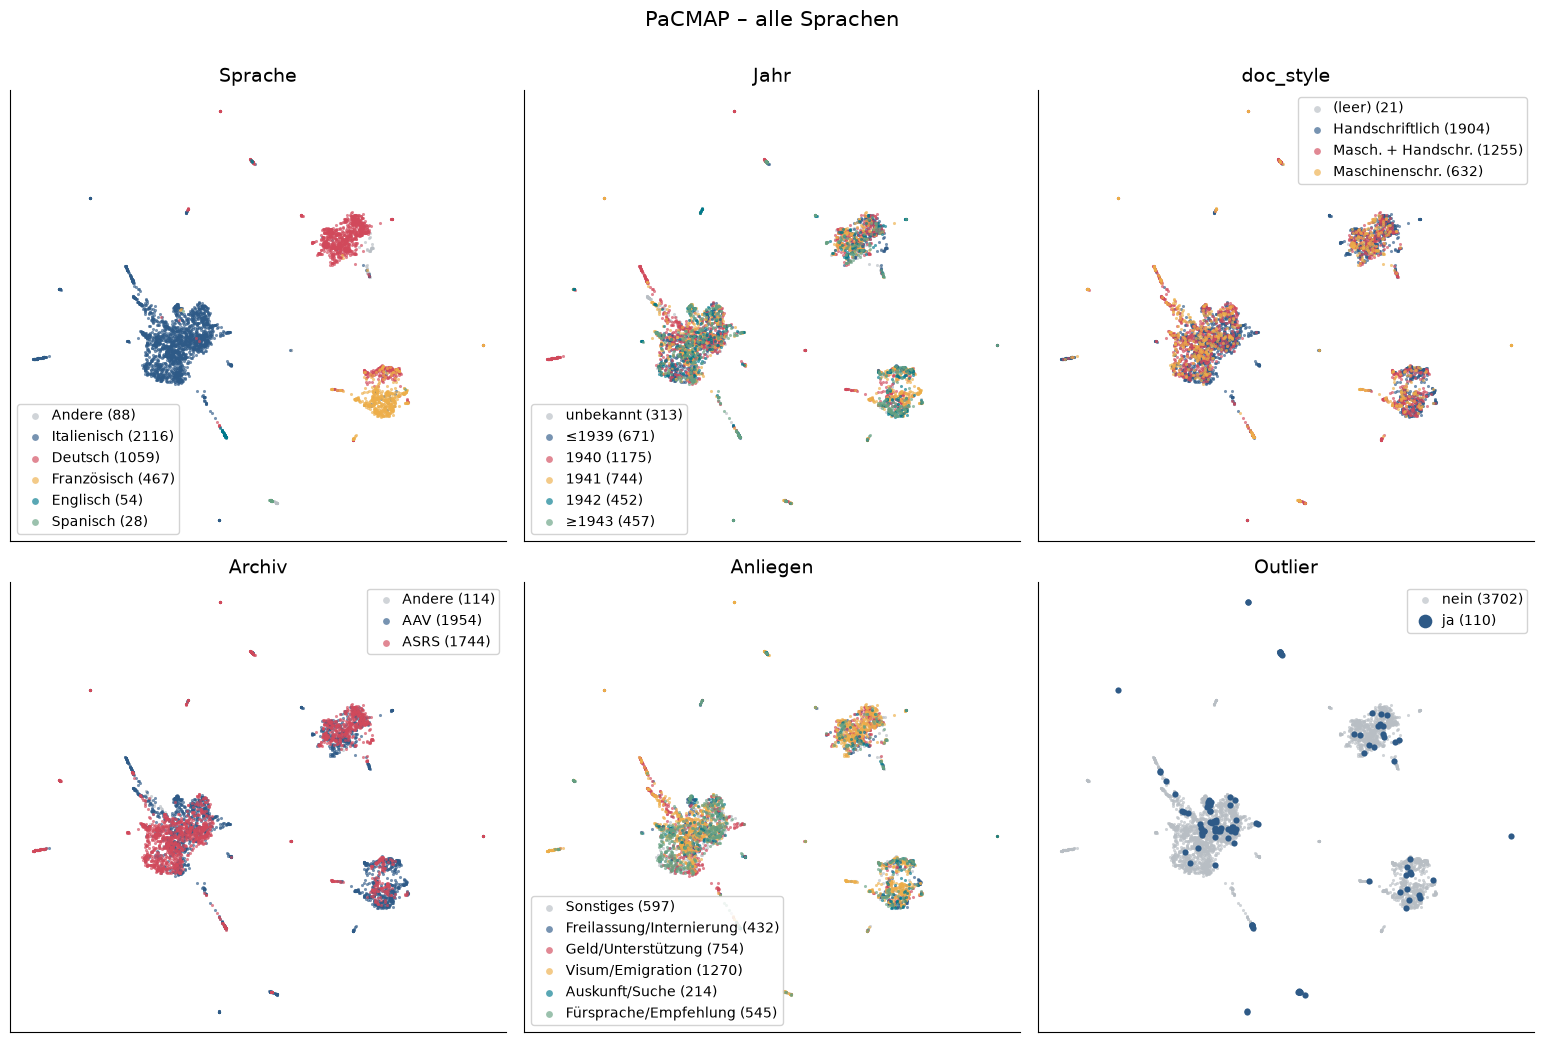

In [21]:
import pacmap

def run_pacmap(X, name):
    return D.cached_projection(PROJ / f"pacmap_{name}.npy",
                               lambda: pacmap.PaCMAP(n_components=2, random_state=RANDOM_STATE).fit_transform(X, init="pca"), force=REBUILD)

Y_pac_all, rt_pac_all = run_pacmap(X50_all, "all")
fig = D.plot_projection(Y_pac_all, COLORS, "PaCMAP – alle Sprachen", orders=ORDERS)
save_fig(fig, "projection_pacmap_all", FIG)
plt.show()

**Interpretation:** PaCMAP ist mit 1,5 s das schnellste nichtlineare Verfahren. Es liefert kompakte Sprachinseln mit klar abgesetzten Satelliten und erhält globale Distanzen fast so gut wie UMAP (Spearman 0,68 vs. 0,70, siehe Schritt 19).

### 16. Autoencoder  *[Vorlesung]*

Ein kleines PyTorch-Netz auf den 100 SVD-Komponenten: **100–64–16–2–16–64–100**, ReLU, linearer Bottleneck, MSE-Verlust, Adam (lr 1e-3),
Batches à 128, höchstens 300 Epochen mit **Early Stopping** (Geduld 15 Epochen auf 10 % Validierungsdaten).
Die Eingabe wird zentriert und mit **einer** globalen Standardabweichung skaliert. So bleiben die relativen Varianzen der SVD-Komponenten erhalten.

Zusätzlich wird ein **linearer Autoencoder** gleicher Architektur ohne Aktivierungen trainiert. Laut Vorlesung (Baldi & Hornik 1989)
spannt sein Decoder denselben Unterraum auf wie die ersten 2 PCs. Das wird über die **Hauptwinkel** zwischen den Unterräumen geprüft.

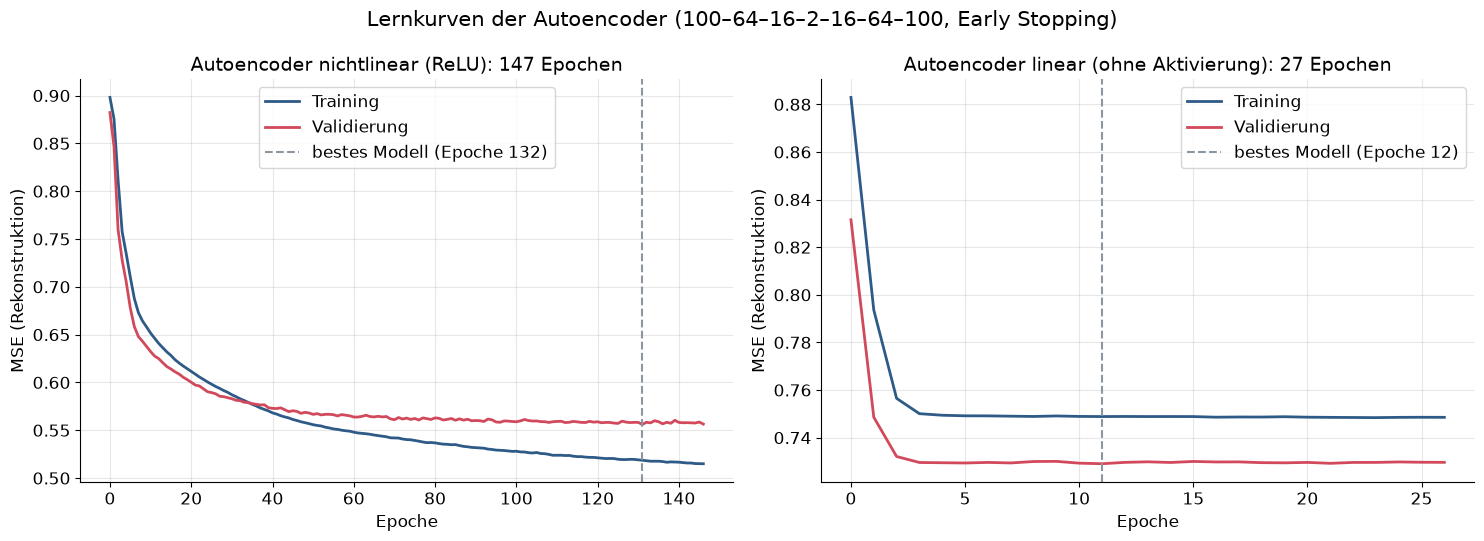

In [22]:
def run_ae(Zin, name, linear=False):
    p_Z, p_h = CACHE / f"ae_{name}_{'lin' if linear else 'relu'}.npy", CACHE / f"ae_{name}_{'lin' if linear else 'relu'}_hist.json"
    p_M = CACHE / f"ae_{name}_lin_decoder.npy"
    if p_Z.exists() and p_h.exists() and (not linear or p_M.exists()) and not REBUILD:
        h = json.loads(p_h.read_text())
        return np.load(p_Z), h["hist"], h["runtime_s"], (np.load(p_M) if linear else None)
    Xa = (Zin - Zin.mean(0)) / Zin.std()
    t0 = time.perf_counter()
    Z, hist, enc, dec = D.train_autoencoder(Xa, linear=linear)
    rt = time.perf_counter() - t0
    np.save(p_Z, Z)
    p_h.write_text(json.dumps({"hist": hist, "runtime_s": rt}))
    M = None
    if linear:
        M = D.linear_decoder_matrix(dec)
        np.save(p_M, M)
    return Z, hist, rt, M

Y_ae_all, hist_ae, rt_ae_all, _ = run_ae(Z_all, "all")
Y_lae_all, hist_lae, rt_lae_all, M_lae = run_ae(Z_all, "all", linear=True)
np.save(PROJ / "autoencoder_all.npy", Y_ae_all)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, h, ttl in [(axes[0], hist_ae, "nichtlinear (ReLU)"), (axes[1], hist_lae, "linear (ohne Aktivierung)")]:
    ax.plot(h["train"], color=PALETTE["main"], lw=2, label="Training")
    ax.plot(h["val"], color=PALETTE["outlier"], lw=2, label="Validierung")
    best = int(np.argmin(h["val"]))
    ax.axvline(best, color=PALETTE["grey"], ls="--", label=f"bestes Modell (Epoche {best + 1})")
    ax.set_xlabel("Epoche"); ax.set_ylabel("MSE (Rekonstruktion)")
    ax.set_title(f"Autoencoder {ttl}: {len(h['train'])} Epochen")
    ax.legend()
fig.suptitle("Lernkurven der Autoencoder (100–64–16–2–16–64–100, Early Stopping)")
fig.tight_layout()
save_fig(fig, "autoencoder_loss", FIG)
plt.show()

Hauptwinkel zwischen Decoder-Unterraum (linearer AE) und PC1/PC2: [66.02  2.95] Grad
R² (PCA-Scores linear aus Codes erklärbar): linearer AE 0.589 | ReLU-AE 0.404
PCA-Eigenwerte der AE-Eingabe λ1–λ3: [10.398  4.363  4.334]  → λ2 ≈ λ3: 2D-Unterraum kaum eindeutig bestimmt


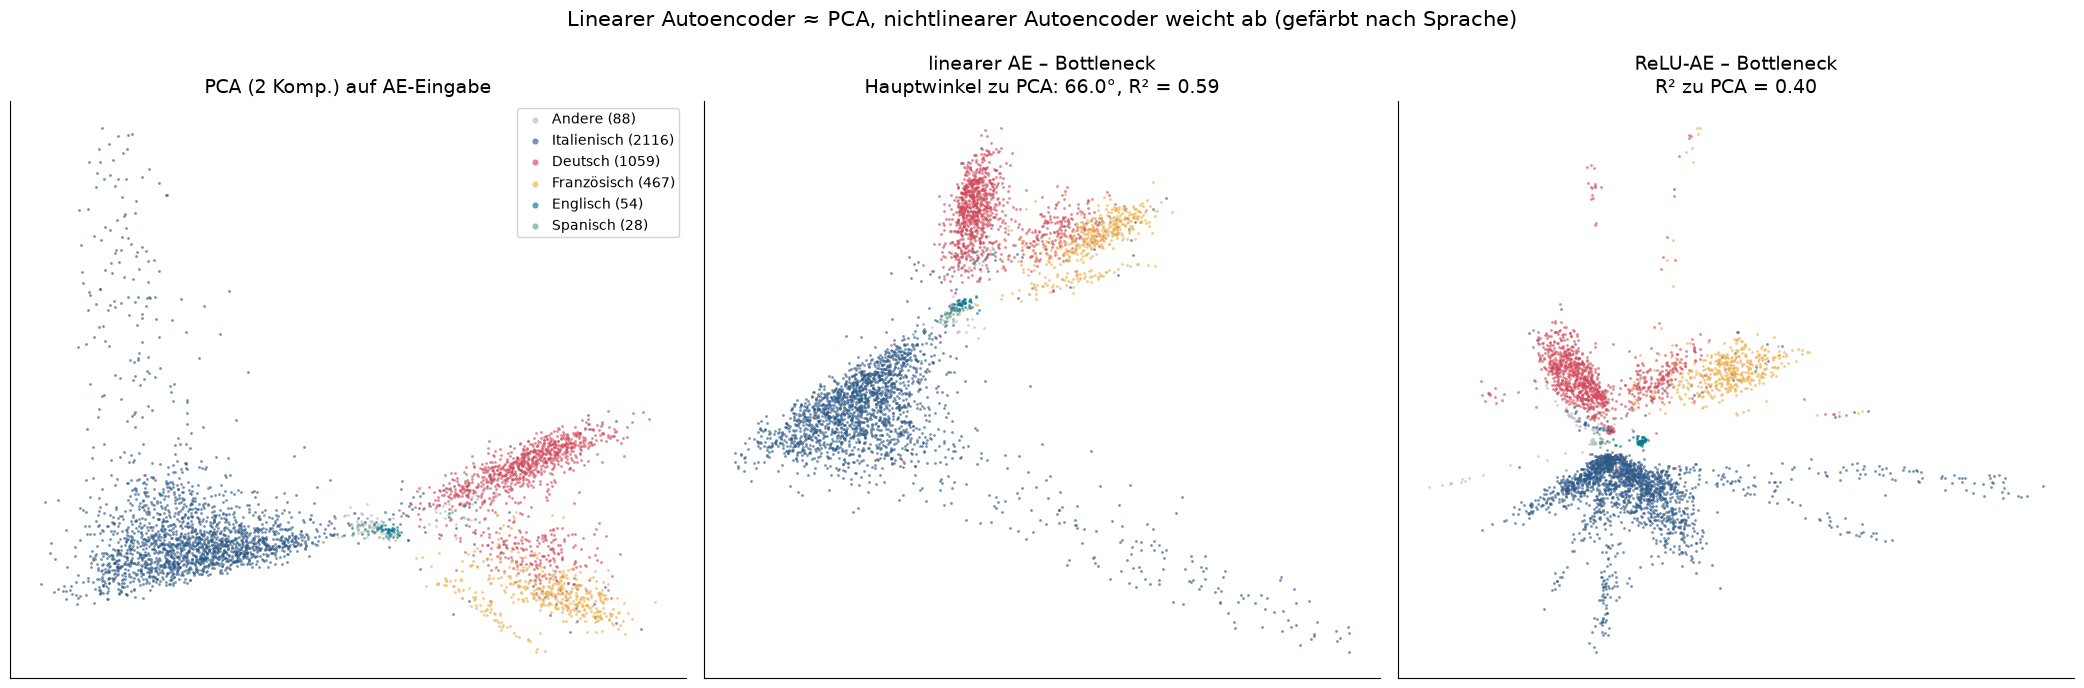

In [23]:
from scipy.linalg import subspace_angles
from sklearn.linear_model import LinearRegression

Xa = (Z_all - Z_all.mean(0)) / Z_all.std()
pca_ae = PCA(n_components=2, random_state=RANDOM_STATE).fit(Xa)
Y_pca_ae = pca_ae.transform(Xa)
angles = np.degrees(subspace_angles(M_lae, pca_ae.components_.T))
r2_lin = LinearRegression().fit(Y_lae_all, Y_pca_ae).score(Y_lae_all, Y_pca_ae)
r2_relu = LinearRegression().fit(Y_ae_all, Y_pca_ae).score(Y_ae_all, Y_pca_ae)
print(f"Hauptwinkel zwischen Decoder-Unterraum (linearer AE) und PC1/PC2: {np.round(angles, 2)} Grad")
print(f"R² (PCA-Scores linear aus Codes erklärbar): linearer AE {r2_lin:.3f} | ReLU-AE {r2_relu:.3f}")
STATS["linear_ae_vs_pca"] = {"principal_angles_deg": np.round(angles, 3).tolist(), "r2_linear_ae": round(float(r2_lin), 4),
                             "r2_relu_ae": round(float(r2_relu), 4)}
ev3 = PCA(n_components=3, random_state=RANDOM_STATE).fit(Xa).explained_variance_
print(f"PCA-Eigenwerte der AE-Eingabe λ1–λ3: {np.round(ev3, 3)}  → λ2 ≈ λ3: 2D-Unterraum kaum eindeutig bestimmt")
STATS["linear_ae_vs_pca"]["pca_eigenvalues_1_3"] = np.round(ev3, 4).tolist()

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, Y, ttl in [(axes[0], Y_pca_ae, "PCA (2 Komp.) auf AE-Eingabe"),
                   (axes[1], Y_lae_all, f"linearer AE – Bottleneck\nHauptwinkel zu PCA: {angles.max():.1f}°, R² = {r2_lin:.2f}"),
                   (axes[2], Y_ae_all, f"ReLU-AE – Bottleneck\nR² zu PCA = {r2_relu:.2f}")]:
    D.scatter_by(ax, Y, COLORS["Sprache"], s=4, legend=(ax is axes[0]))
    ax.set_title(ttl)
fig.suptitle("Linearer Autoencoder ≈ PCA, nichtlinearer Autoencoder weicht ab (gefärbt nach Sprache)")
fig.tight_layout()
save_fig(fig, "autoencoder_linear_vs_pca", FIG)
plt.show()

**Interpretation:** Der ReLU-Autoencoder stoppt per Early Stopping, sobald der Validierungsfehler nicht mehr sinkt. Sein Bottleneck trennt die Sprachen, ist aber unschärfer als t-SNE/UMAP, wie in der Vorlesung als Nachteil genannt. Beim **linearen** Autoencoder trifft die eine Decoder-Richtung PC2 fast exakt (Hauptwinkel ≈ 3°), die andere weicht ab (≈ 66°, R² = 0,59). Der Grund steht in der Ausgabe: Die PCA-Eigenwerte λ₂ und λ₃ der AE-Eingabe sind fast gleich (4,36 vs. 4,33). Der 2D-Unterraum ist damit kaum eindeutig bestimmt, und tiefe lineare Netze konvergieren entlang so flacher Richtungen sehr langsam. Theoretisch spannt das Optimum denselben Unterraum wie PCA auf (Baldi & Hornik). Dieser Lauf zeigt das nur teilweise.

### 17. Großer Vergleich (zentrale Folie)

PCA | t-SNE | UMAP | PaCMAP | Autoencoder auf denselben Briefen, einmal nach **Sprache**, einmal nach **Anliegen** gefärbt.

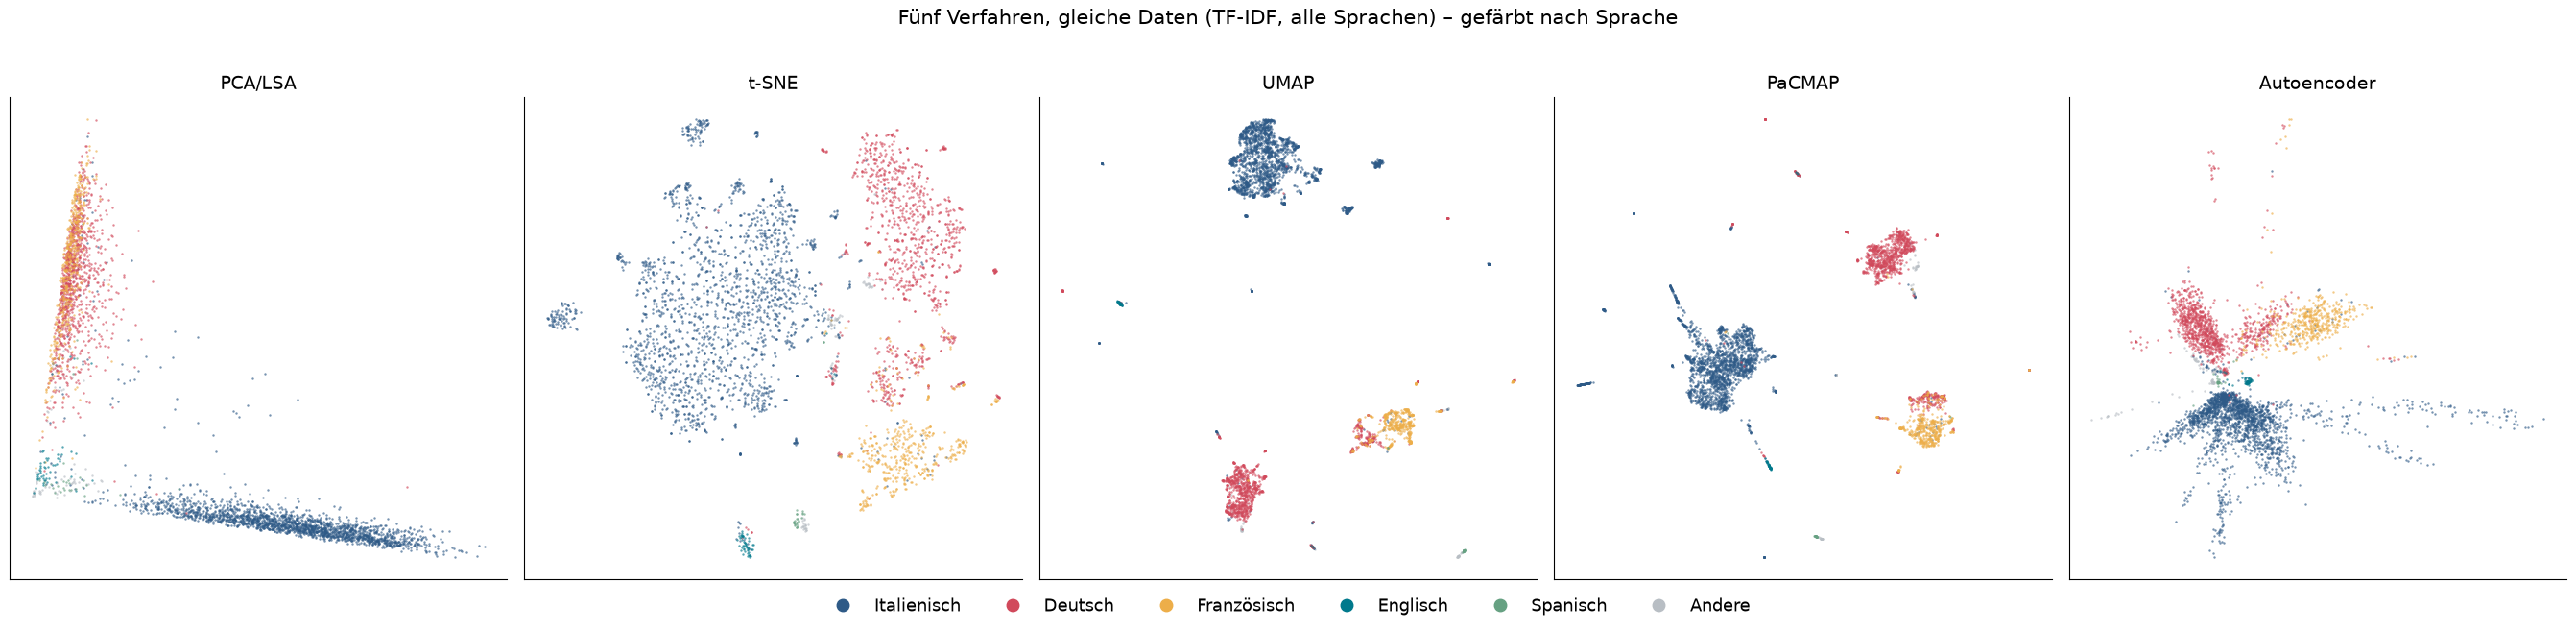

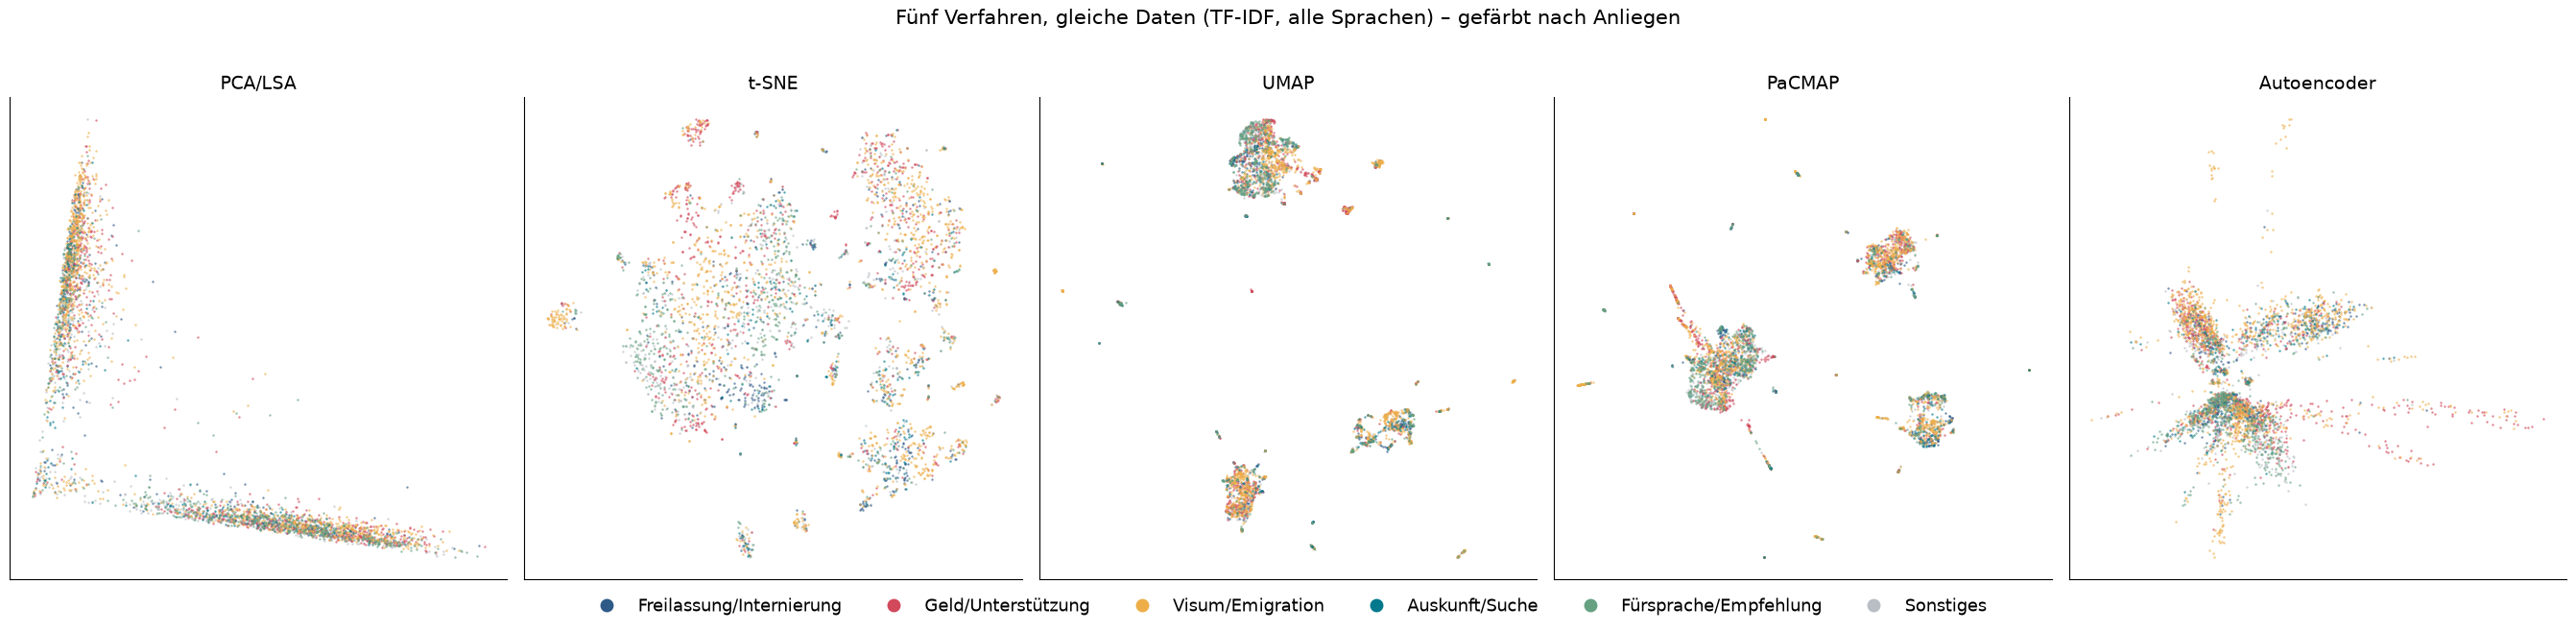

In [24]:
METHODS_ALL = {"PCA/LSA": (Y_pca_all, rt_svd_all), "t-SNE": (Y_tsne_all, rt_tsne_all), "UMAP": (Y_umap_all, rt_umap_all),
               "PaCMAP": (Y_pac_all, rt_pac_all), "Autoencoder": (Y_ae_all, rt_ae_all)}
for name, (Y, _) in METHODS_ALL.items():
    np.save(PROJ / f"final_{name.split('/')[0].lower().replace('-', '')}_all.npy", Y)

def comparison(methods, labels, order, title, fname):
    fig, axes = plt.subplots(1, len(methods), figsize=(5.4 * len(methods), 6))
    for k, (ax, (name, (Y, rt))) in enumerate(zip(axes, methods.items())):
        D.scatter_by(ax, Y, labels, order=order, s=3, legend=False)
        ax.set_title(name)
    handles = [plt.Line2D([], [], marker="o", ls="", ms=9, color=c, label=l)
               for l, c in D.scatter_by(plt.figure().gca(), methods["PCA/LSA"][0], labels, order=order, legend=False).items()]
    plt.close()
    fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 7), fontsize=13, frameon=False,
               bbox_to_anchor=(0.5, -0.06))
    fig.suptitle(title, y=1.02)
    fig.tight_layout()
    save_fig(fig, fname, FIG)
    plt.show()

comparison(METHODS_ALL, COLORS["Sprache"], None, "Fünf Verfahren, gleiche Daten (TF-IDF, alle Sprachen) – gefärbt nach Sprache",
           "method_comparison_language")
comparison(METHODS_ALL, COLORS["Anliegen"], ORDERS["Anliegen"],
           "Fünf Verfahren, gleiche Daten (TF-IDF, alle Sprachen) – gefärbt nach Anliegen", "method_comparison_request")

**Interpretation:** **Zentrale Folie:** Alle fünf Verfahren trennen zuerst nach **Sprache**, TF-IDF ist ein Sprachraum. Nach Anliegen gefärbt sind die großen Sprachinseln gemischt. Nur die kleinen Satelliten sind thematisch homogen (z. B. Visum- oder Geldanfragen). t-SNE, UMAP und PaCMAP zeigen diese Satelliten deutlich, PCA/LSA und der Autoencoder kaum.

### 18. Variante „nur Italienisch“

Damit die Sprache als dominanter Faktor wegfällt, werden die Schritte 12–14 und 17 auf den italienischen Briefen wiederholt
(eigene TF-IDF und SVD aus Schritt 10/11). Gefärbt wird nach Anliegen, Jahr und Archiv.

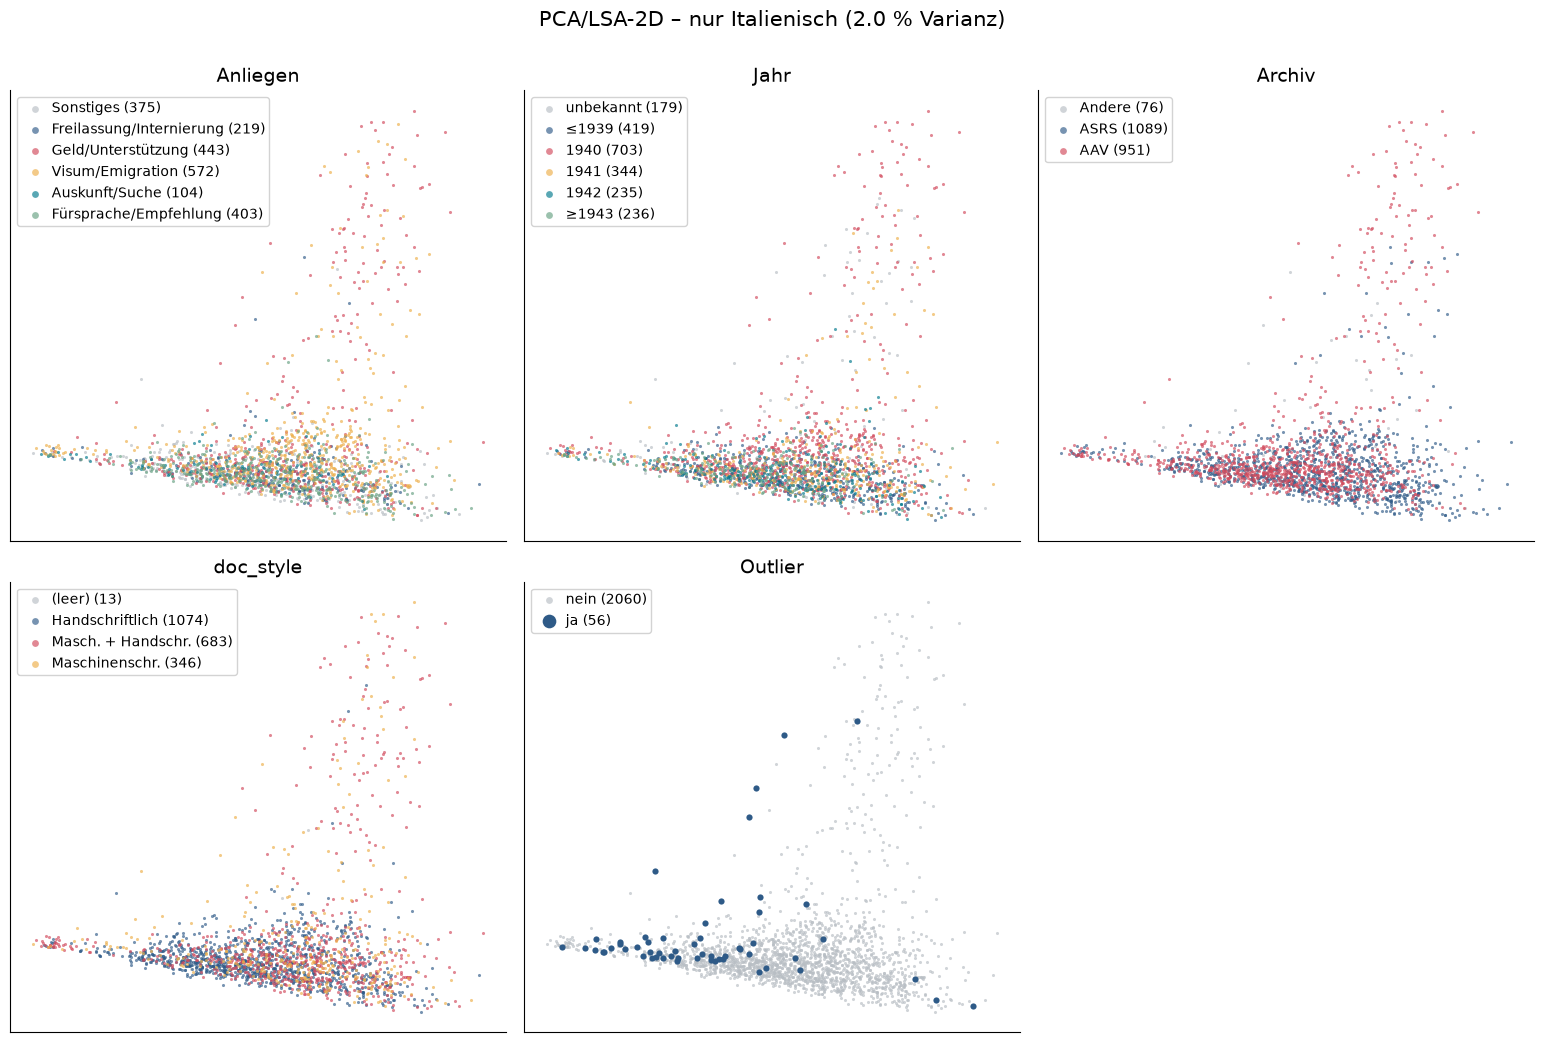

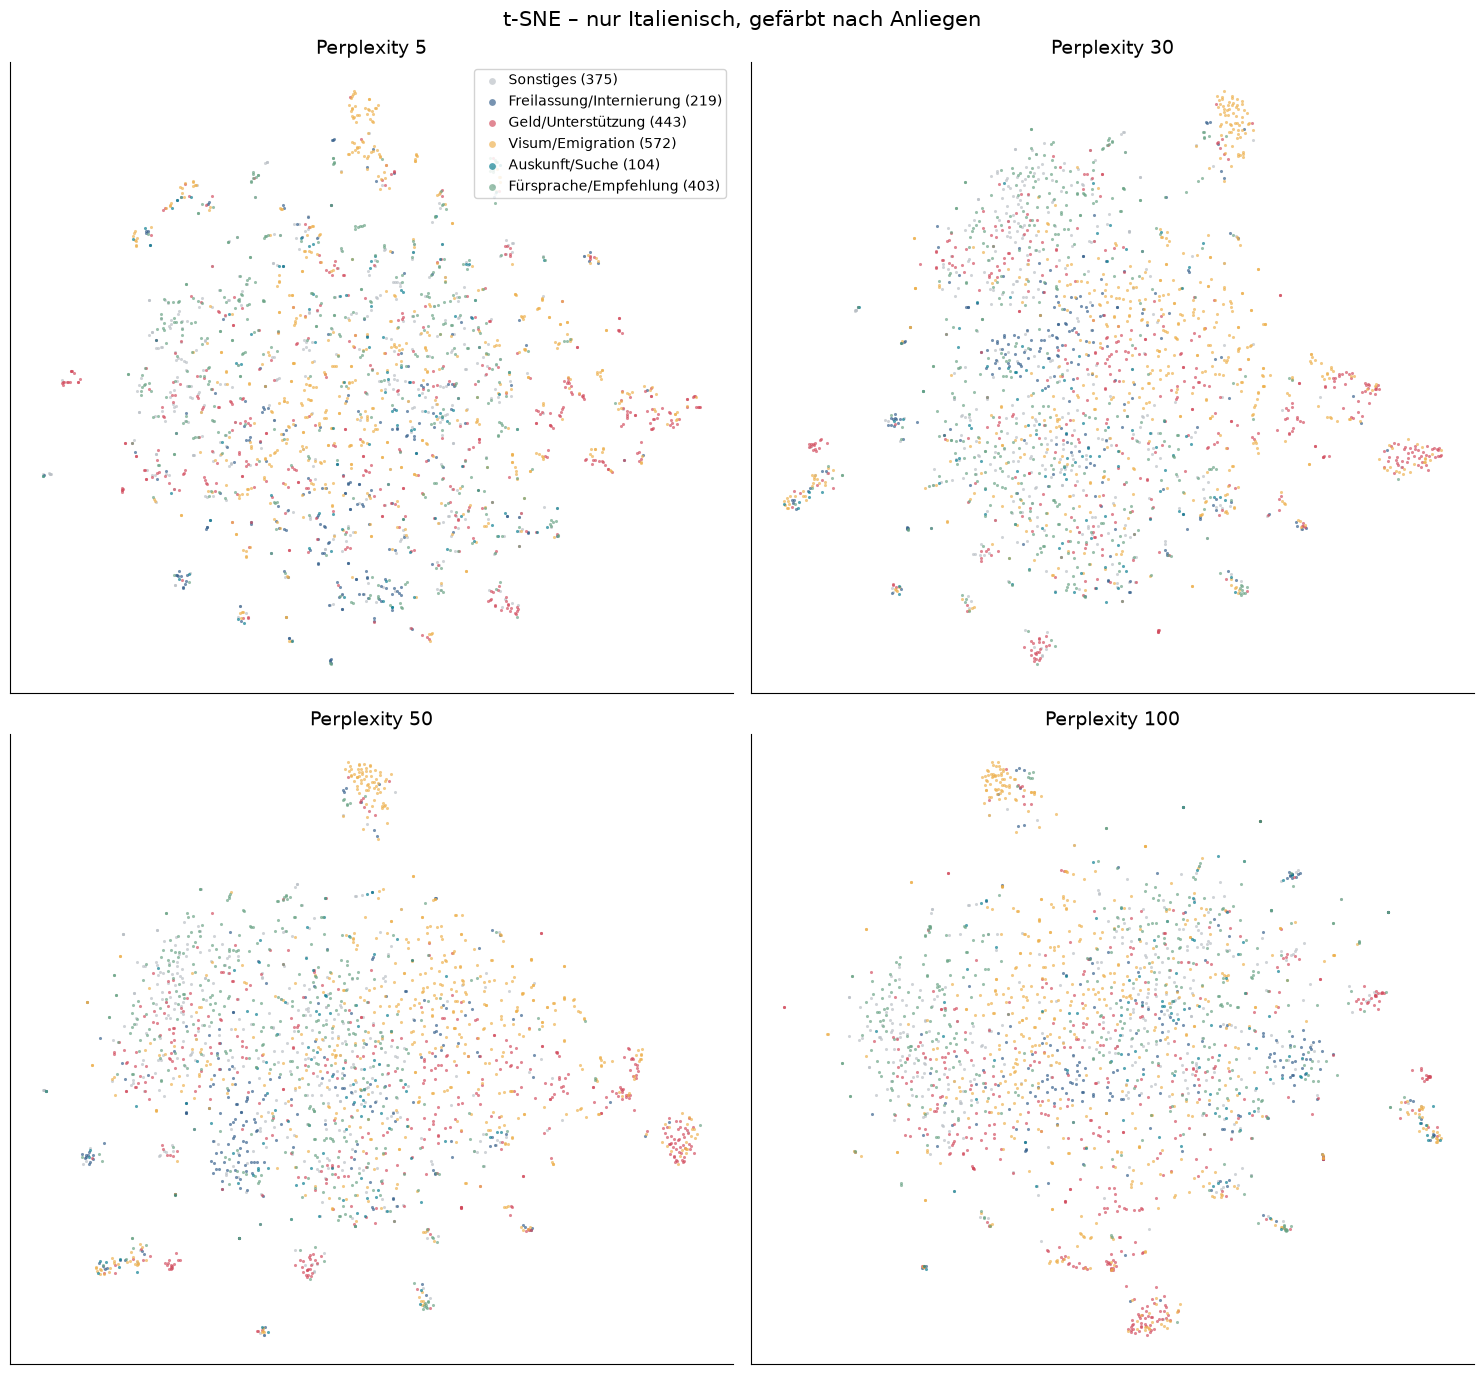

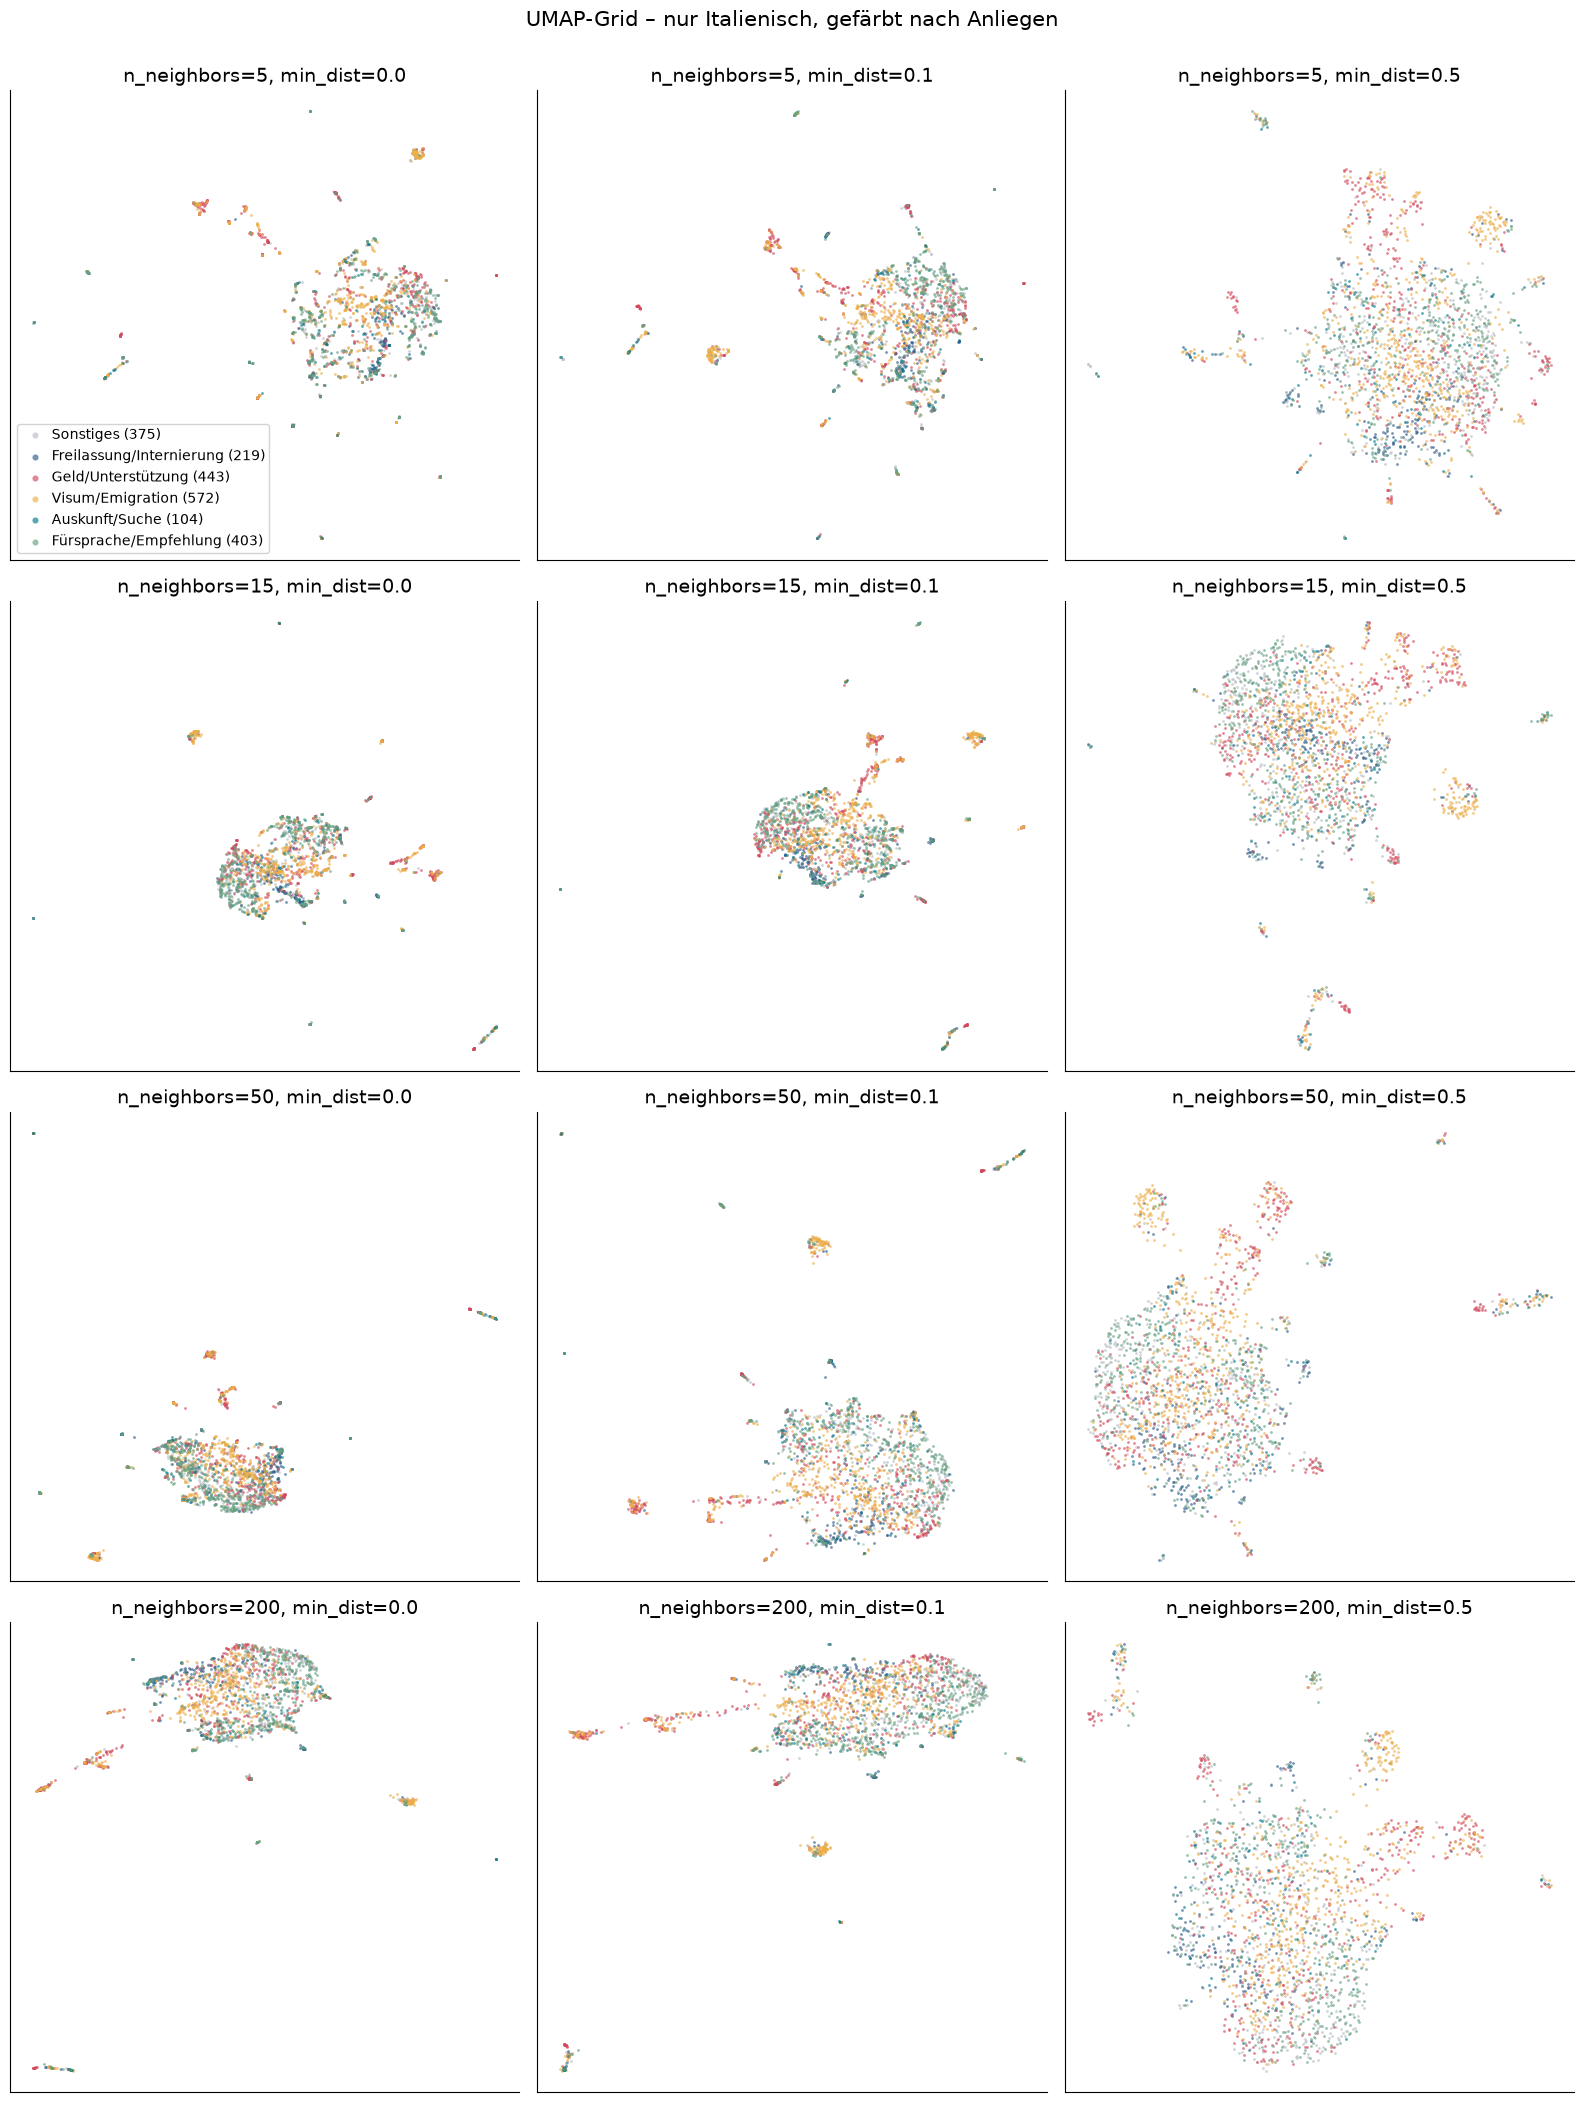

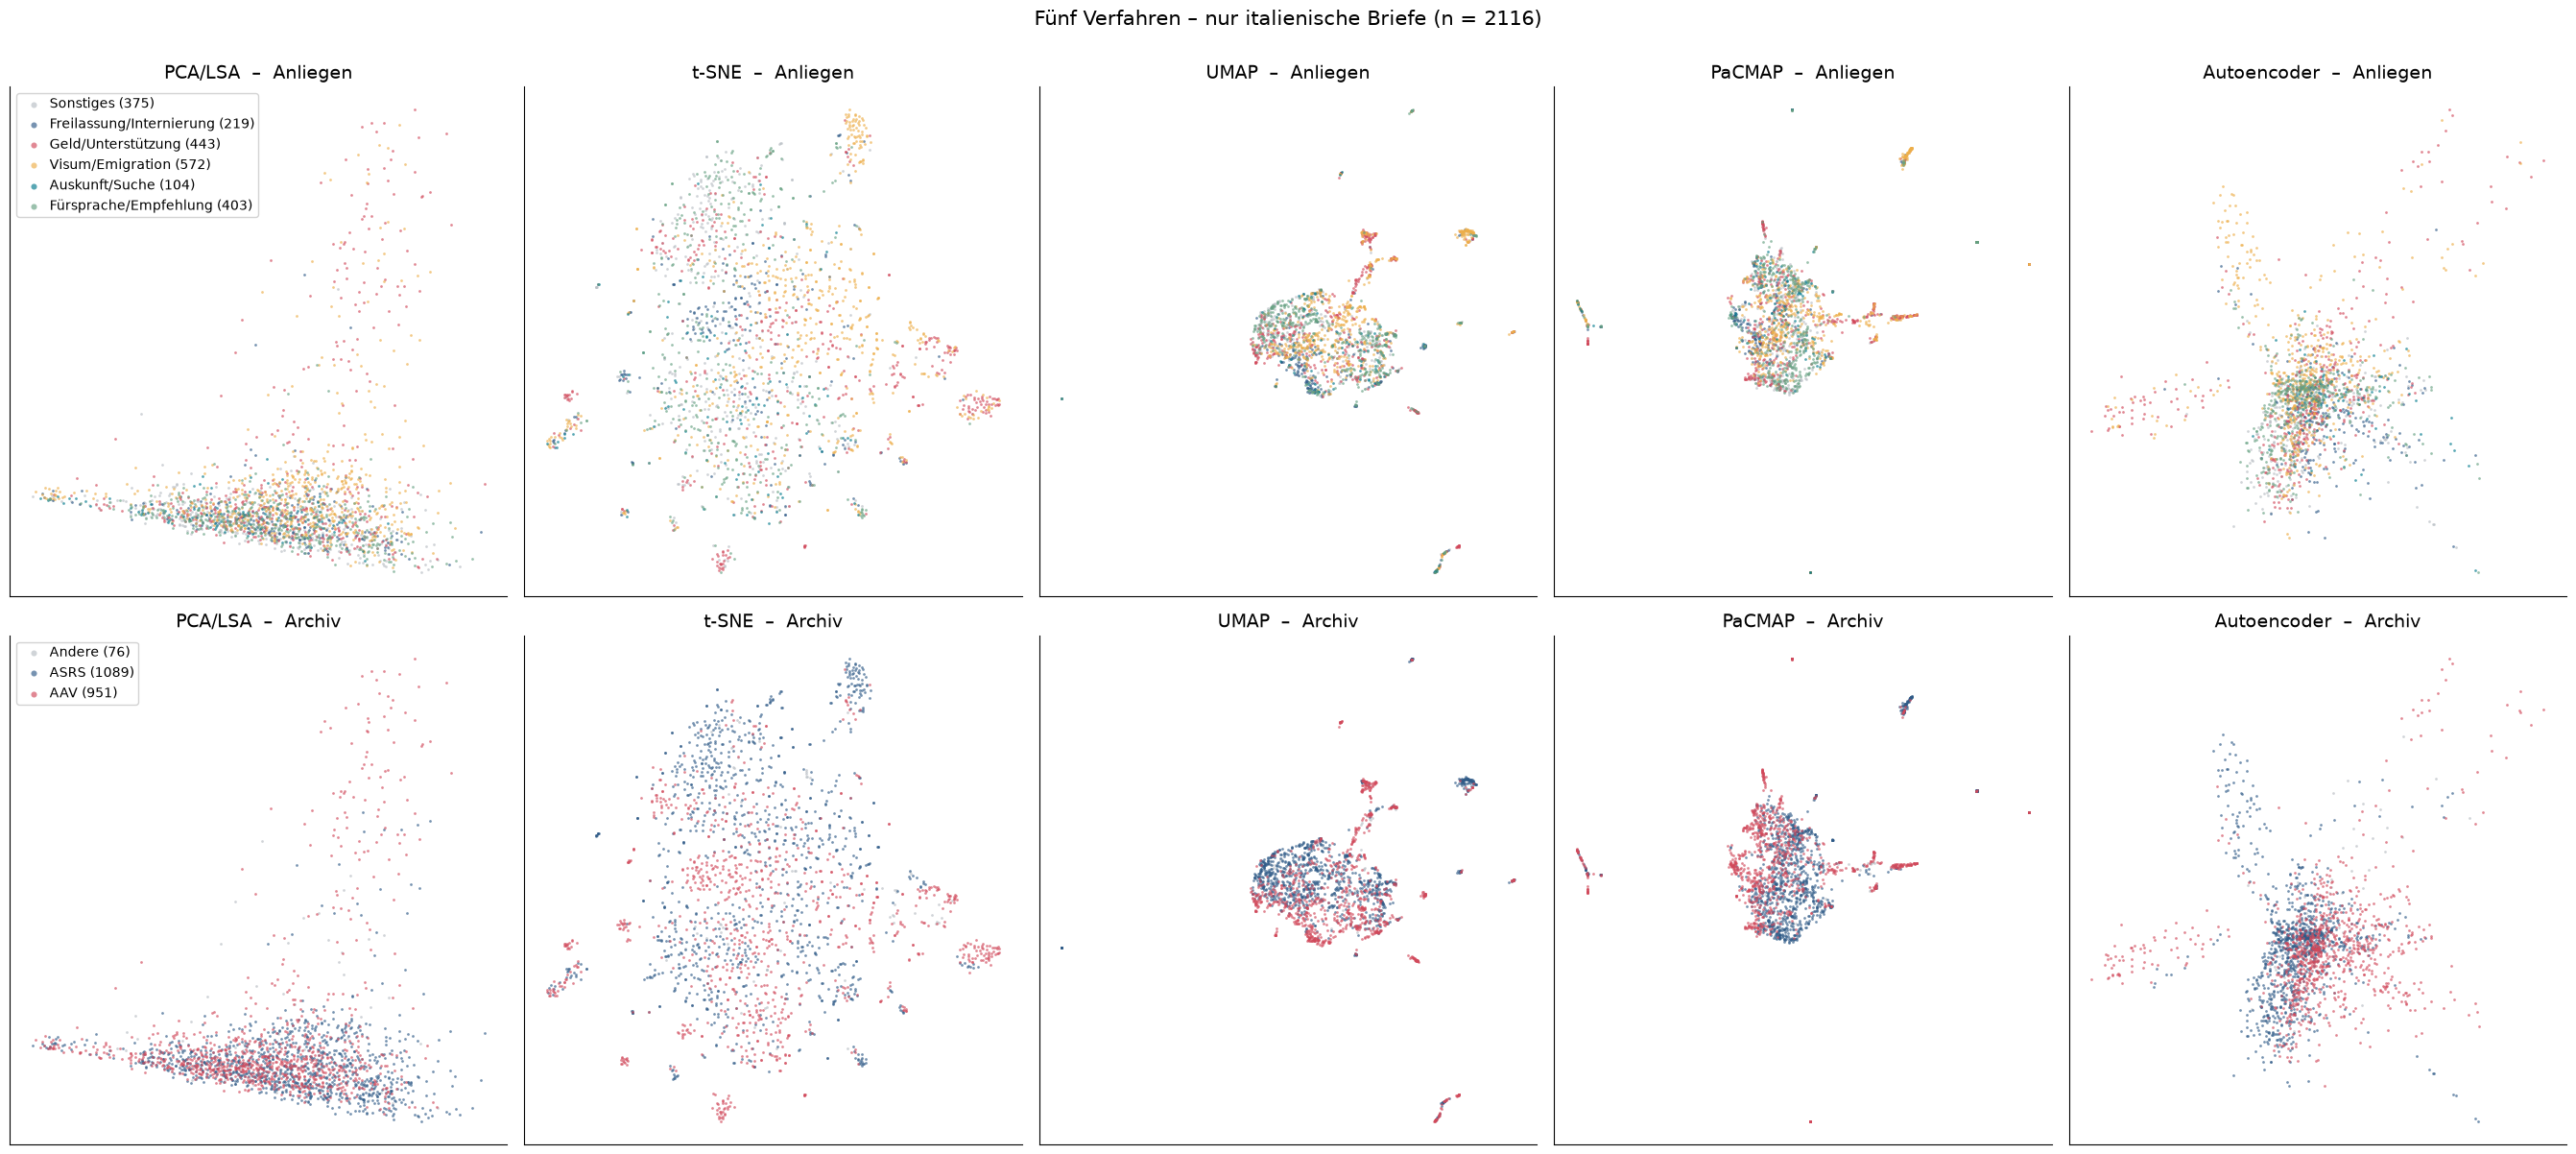

In [25]:
C_it = COLORS.loc[it_mask].reset_index(drop=True)
X50_it = Z_it[:, :50]
Y_pca_it = Z_it[:, :2]
np.save(PROJ / "pca2d_italian.npy", Y_pca_it)
ts_grid_it = {p: tsne(X50_it, "italian", p) for p in PERPS}
um_grid_it = {(nn, m): run_umap(X50_it, "italian", nn, m) for nn in NNS for m in MDS}
Y_tsne_it, rt_tsne_it = ts_grid_it[30]
Y_umap_it, rt_umap_it = um_grid_it[(15, 0.1)]
Y_pac_it, rt_pac_it = run_pacmap(X50_it, "italian")
Y_ae_it, hist_ae_it, rt_ae_it, _ = run_ae(Z_it, "italian")
np.save(PROJ / "autoencoder_italian.npy", Y_ae_it)

fig = D.plot_projection(Y_pca_it, C_it, f"PCA/LSA-2D – nur Italienisch ({svd_ev.loc['2 Komp.', 'nur Italienisch']:.1f} % Varianz)",
                        cols=["Anliegen", "Jahr", "Archiv", "doc_style", "Outlier"], orders=ORDERS)
save_fig(fig, "projection_pca_italian", FIG)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(15, 14))
for ax, p in zip(axes.ravel(), PERPS):
    D.scatter_by(ax, ts_grid_it[p][0], C_it["Anliegen"], order=ORDERS["Anliegen"], s=5, legend=(p == 5))
    ax.set_title(f"Perplexity {p}")
fig.suptitle("t-SNE – nur Italienisch, gefärbt nach Anliegen")
fig.tight_layout()
save_fig(fig, "tsne_perplexity_grid_italian", FIG)
plt.show()

fig, axes = plt.subplots(len(NNS), len(MDS), figsize=(16, 21))
for r, nn in enumerate(NNS):
    for c, m in enumerate(MDS):
        D.scatter_by(axes[r, c], um_grid_it[(nn, m)][0], C_it["Anliegen"], order=ORDERS["Anliegen"], s=4,
                     legend=(r == 0 and c == 0))
        axes[r, c].set_title(f"n_neighbors={nn}, min_dist={m}")
fig.suptitle("UMAP-Grid – nur Italienisch, gefärbt nach Anliegen", y=1.0)
fig.tight_layout()
save_fig(fig, "umap_param_grid_italian", FIG)
plt.show()

METHODS_IT = {"PCA/LSA": (Y_pca_it, rt_svd_it), "t-SNE": (Y_tsne_it, rt_tsne_it), "UMAP": (Y_umap_it, rt_umap_it),
              "PaCMAP": (Y_pac_it, rt_pac_it), "Autoencoder": (Y_ae_it, rt_ae_it)}
fig, axes = plt.subplots(2, 5, figsize=(27, 12))
for r, (var, order) in enumerate([("Anliegen", ORDERS["Anliegen"]), ("Archiv", None)]):
    for c, (name, (Y, _)) in enumerate(METHODS_IT.items()):
        D.scatter_by(axes[r, c], Y, C_it[var], order=order, s=4, legend=(c == 0))
        axes[r, c].set_title(f"{name}  –  {var}")
fig.suptitle(f"Fünf Verfahren – nur italienische Briefe (n = {it_mask.sum()})", y=1.0)
fig.tight_layout()
save_fig(fig, "method_comparison_italian", FIG)
plt.show()

**Interpretation:** Ohne den Faktor Sprache gibt es keine dominante Trennung mehr. Der Hauptkörper ist nach Anliegen gemischt. t-SNE, UMAP und PaCMAP zeigen aber eigene Satelliten, die von Visum/Emigration bzw. Geld/Unterstützung dominiert sind. Nach Archiv gefärbt trennen sich AAV und ASRS teilweise: Archivbestände entsprechen offenbar unterschiedlichen Korrespondenz-Serien mit eigenem Vokabular. PCA/LSA zeigt davon kaum etwas.

## Teil E – Qualität der Projektionen messen  *[Erweiterung, nicht Vorlesung]*

### 19. Trustworthiness, kNN-Erhalt, globale Distanzkorrelation, Laufzeit

Referenz ist immer der **Originalraum: TF-IDF mit Kosinus-Distanz**.
- **Trustworthiness** (`sklearn.manifold.trustworthiness`, k = 10): Bestraft 2D-Nachbarn, die im Original keine Nachbarn sind. 1 = perfekt.
- **kNN-Erhalt**: Anteil der 10 nächsten Original-Nachbarn, die auch in 2D unter den 10 nächsten sind (**lokale** Struktur).
- **Spearman ρ** zwischen Original- und 2D-Distanzen auf 2.000 zufälligen Paaren (**globale** Struktur).
- **Laufzeit**: Die Zeit für die vorgeschaltete SVD (gemeinsam für alle) ist bei PCA/LSA enthalten, bei den anderen nicht.

,Daten,Methode,trustworthiness,knn_preservation,spearman_global,Laufzeit_s
0,alle Sprachen,PCA/LSA,0.763,0.024,0.690,0.742
1,alle Sprachen,t-SNE,0.939,0.236,0.561,12.616
2,alle Sprachen,UMAP,0.928,0.198,0.697,6.103
3,alle Sprachen,PaCMAP,0.905,0.168,0.676,1.476
4,alle Sprachen,Autoencoder,0.882,0.093,0.500,8.527
5,nur Italienisch,PCA/LSA,0.642,0.030,0.228,0.304
6,nur Italienisch,t-SNE,0.879,0.241,0.292,13.904
7,nur Italienisch,UMAP,0.862,0.207,0.356,3.420
8,nur Italienisch,PaCMAP,0.821,0.178,0.308,0.842
9,nur Italienisch,Autoencoder,0.738,0.075,0.059,1.694


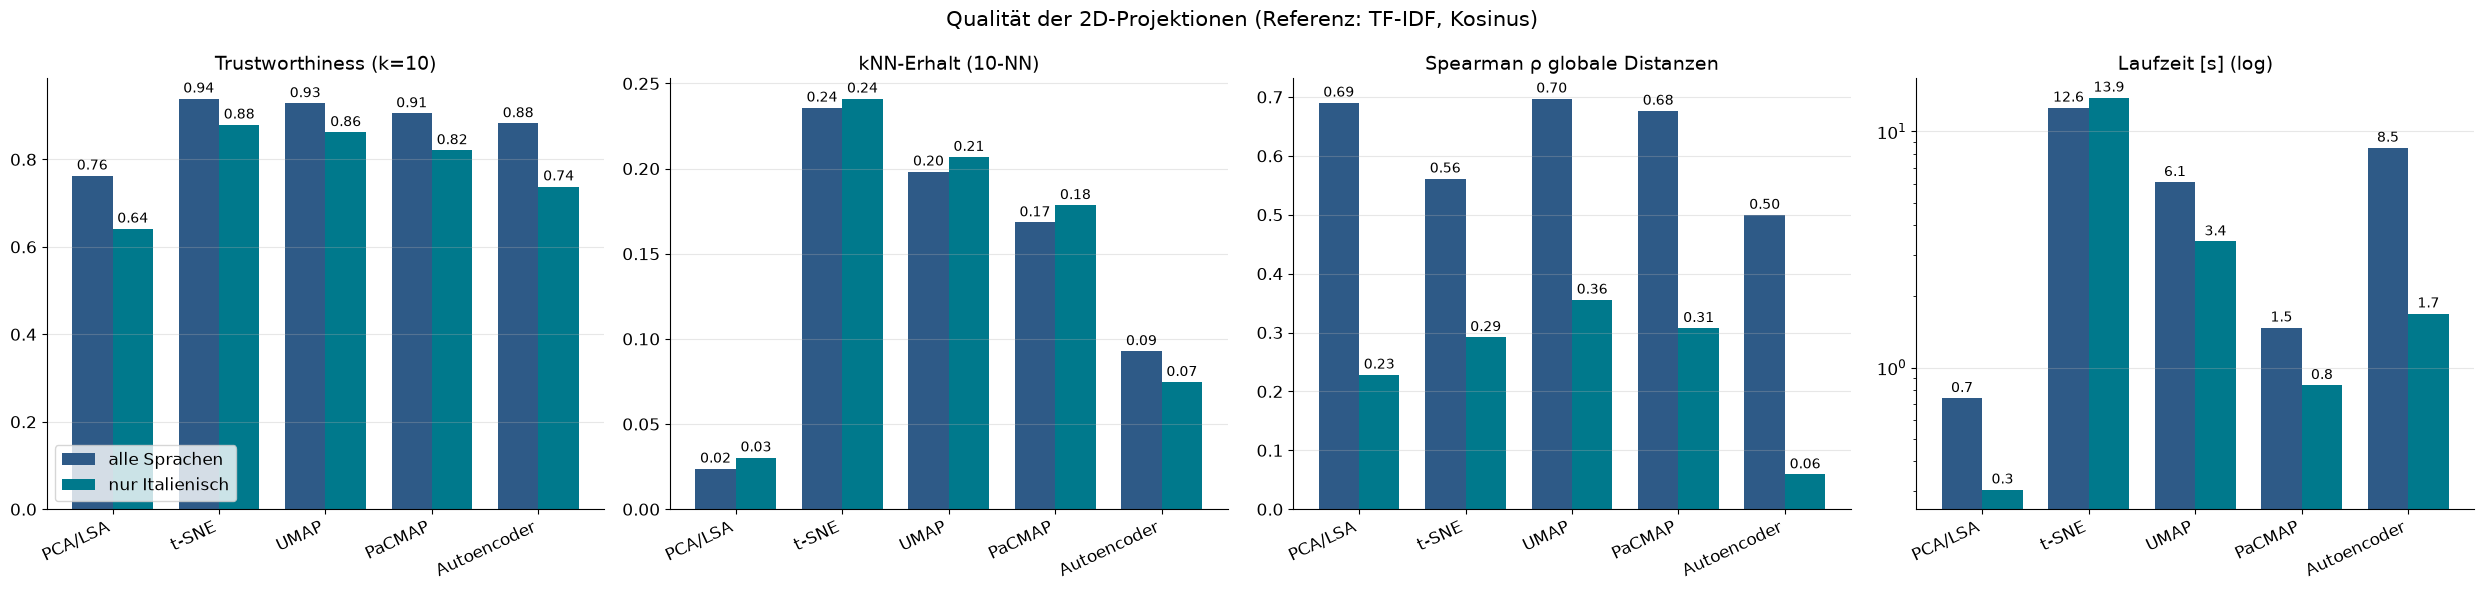

In [26]:
knn_all = D.knn_sets(X_all, 10, "cosine")
knn_it = D.knn_sets(X_it, 10, "cosine")
rows = []
for ds, methods, X, knn in [("alle Sprachen", METHODS_ALL, X_all, knn_all), ("nur Italienisch", METHODS_IT, X_it, knn_it)]:
    for name, (Y, rt) in methods.items():
        rows.append({"Daten": ds, "Methode": name, **D.quality_metrics(X, Y, knn), "Laufzeit_s": rt})
quality = pd.DataFrame(rows)
quality.to_csv(RES / "dimred_quality.csv", index=False)
display(quality.round(3))

metrics = [("trustworthiness", "Trustworthiness (k=10)"), ("knn_preservation", "kNN-Erhalt (10-NN)"),
           ("spearman_global", "Spearman ρ globale Distanzen"), ("Laufzeit_s", "Laufzeit [s] (log)")]
fig, axes = plt.subplots(1, 4, figsize=(25, 6))
mnames = list(METHODS_ALL)
x = np.arange(len(mnames))
for ax, (m, ttl) in zip(axes, metrics):
    for k, (ds, col) in enumerate([("alle Sprachen", PALETTE["main"]), ("nur Italienisch", PALETTE["teal"])]):
        v = quality[quality["Daten"] == ds].set_index("Methode").loc[mnames, m]
        bars = ax.bar(x + (k - 0.5) * 0.38, v, width=0.38, color=col, label=ds)
        ax.bar_label(bars, fmt="%.2f" if m != "Laufzeit_s" else "%.1f", fontsize=10, padding=2)
    ax.set_xticks(x, mnames, rotation=25, ha="right")
    ax.set_title(ttl)
    if m == "Laufzeit_s":
        ax.set_yscale("log")
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="lower left")
fig.suptitle("Qualität der 2D-Projektionen (Referenz: TF-IDF, Kosinus)")
fig.tight_layout()
save_fig(fig, "quality_metrics", FIG)
plt.show()
STATS["quality"] = {f"{r['Daten']} | {r['Methode']}": {k: round(float(r[k]), 4) for k in
                    ["trustworthiness", "knn_preservation", "spearman_global", "Laufzeit_s"]} for r in rows}

In [27]:
# Zusatz: Qualität aller UMAP-Grid-Einstellungen (alle Sprachen) → Auswahl der „besten“ UMAP-Projektion für Teil F
grid_rows = []
for (nn, m), (Y, rt) in um_grid.items():
    grid_rows.append({"n_neighbors": nn, "min_dist": m, **D.quality_metrics(X_all, Y, knn_all), "Laufzeit_s": rt})
umap_q = pd.DataFrame(grid_rows)
umap_q.to_csv(RES / "umap_grid_quality.csv", index=False)
display(umap_q.pivot(index="n_neighbors", columns="min_dist", values="knn_preservation").round(3)
        .style.background_gradient(cmap="Blues").set_caption("kNN-Erhalt je UMAP-Einstellung"))
display(umap_q.pivot(index="n_neighbors", columns="min_dist", values="spearman_global").round(3)
        .style.background_gradient(cmap="Blues").set_caption("Spearman ρ (global) je UMAP-Einstellung"))
best = umap_q.sort_values(["knn_preservation", "trustworthiness"], ascending=False).iloc[0]
BEST = (int(best["n_neighbors"]), float(best["min_dist"]))
print(f"Beste UMAP-Einstellung nach kNN-Erhalt: n_neighbors={BEST[0]}, min_dist={BEST[1]} "
      f"(kNN-Erhalt {best['knn_preservation']:.3f}, Trustworthiness {best['trustworthiness']:.3f})")
STATS["umap_best_setting"] = {"n_neighbors": BEST[0], "min_dist": BEST[1],
                              "knn_preservation": round(float(best["knn_preservation"]), 4)}

min_dist,0.000000,0.100000,0.500000
n_neighbors,,,
5,0.220000,0.217000,0.192000
15,0.202000,0.198000,0.175000
50,0.180000,0.175000,0.156000
200,0.168000,0.161000,0.144000


min_dist,0.000000,0.100000,0.500000
n_neighbors,,,
5,0.629000,0.641000,0.595000
15,0.675000,0.697000,0.697000
50,0.732000,0.727000,0.718000
200,0.696000,0.720000,0.688000


Beste UMAP-Einstellung nach kNN-Erhalt: n_neighbors=5, min_dist=0.0 (kNN-Erhalt 0.220, Trustworthiness 0.936)


**Interpretation:** **Lokal:** t-SNE erhält 24 % der 10 nächsten Nachbarn, UMAP 20 %, PaCMAP 17 %, der Autoencoder 9 % und PCA/LSA nur 2 %. Die Trustworthiness liegt bei t-SNE/UMAP bei 0,93–0,94 gegenüber 0,76 bei PCA. **Global:** UMAP (ρ = 0,70), PCA/LSA (0,69) und PaCMAP (0,68) erhalten die Distanzrangfolge am besten, t-SNE am schlechtesten (0,56). Die Vorlesung bestätigt sich: t-SNE/UMAP lokal stark, PCA global besser als t-SNE. UMAP erreicht hier aber auch global PCA-Niveau, weil die globale Struktur vor allem „gleiche vs. andere Sprache“ ist. In der italienischen Variante sind alle ρ niedrig (0,06–0,36): Es gibt kaum globale Struktur. Dass kein Verfahren mehr als ein Viertel der 10-NN erhält, ist die Folge des Curse of Dimensionality aus Teil A. Die beste UMAP-Einstellung nach kNN-Erhalt ist n_neighbors = 5, min_dist = 0.

### 20. Optional: Embeddings

Dieser Schritt läuft nur, wenn bereits Embeddings unter `data/emb_*.npy` (im Ordner `new_results`) liegen. Sie werden hier **nicht** erzeugt.

In [28]:
emb_files = sorted((ROOT / "data").glob("emb_*.npy"))
if not emb_files:
    print("Keine Embeddings unter data/emb_*.npy gefunden → Schritt 20 entfällt (dokumentiert, nicht stillschweigend übersprungen).")
    STATS["embeddings_step"] = "übersprungen: keine data/emb_*.npy vorhanden"
else:
    print("Gefundene Embeddings:", [f.name for f in emb_files])
    E = np.load(emb_files[0])
    ids_path = emb_files[0].with_name(emb_files[0].stem + "_ids.npy")
    if ids_path.exists():
        ids = np.load(ids_path, allow_pickle=True)
        pos = pd.Series(np.arange(len(ids)), index=ids)
        E = E[pos.loc[df["id"]].to_numpy()]
    from sklearn.decomposition import PCA as _PCA
    E50 = _PCA(n_components=50, random_state=RANDOM_STATE).fit_transform(E)
    emb_methods = {"PCA": (E50[:, :2], 0.0),
                   "t-SNE": D.cached_projection(PROJ / "tsne_emb.npy", lambda: TSNE(perplexity=30, init="pca", random_state=RANDOM_STATE).fit_transform(E50)),
                   "UMAP": D.cached_projection(PROJ / "umap_emb.npy", lambda: umap.UMAP(metric="cosine", random_state=RANDOM_STATE).fit_transform(E50))}
    knn_e = D.knn_sets(E, 10, "cosine")
    emb_q = pd.DataFrame([{"Methode": n, **D.quality_metrics(E, Y, knn_e)} for n, (Y, _) in emb_methods.items()])
    display(emb_q)
    comparison(emb_methods, COLORS["Sprache"], None, "Embeddings – gefärbt nach Sprache", "embeddings_comparison_language")
    STATS["embeddings_step"] = emb_q.round(4).to_dict("records")

Keine Embeddings unter data/emb_*.npy gefunden → Schritt 20 entfällt (dokumentiert, nicht stillschweigend übersprungen).


## Teil F – Inhaltliche Exploration der Projektion

### 21. Regionen auf der besten UMAP-Projektion

Auf der UMAP-Einstellung mit dem besten kNN-Erhalt (Schritt 19) werden auffällige Regionen **per Hand als Koordinaten-Rechteck** gewählt.
Das ist bewusst **kein** Clustering-Algorithmus. Je Region werden die Terme mit der höchsten mittleren TF-IDF, die häufigsten `summary_keywords`
und 3 Beispiel-Summaries ausgegeben.

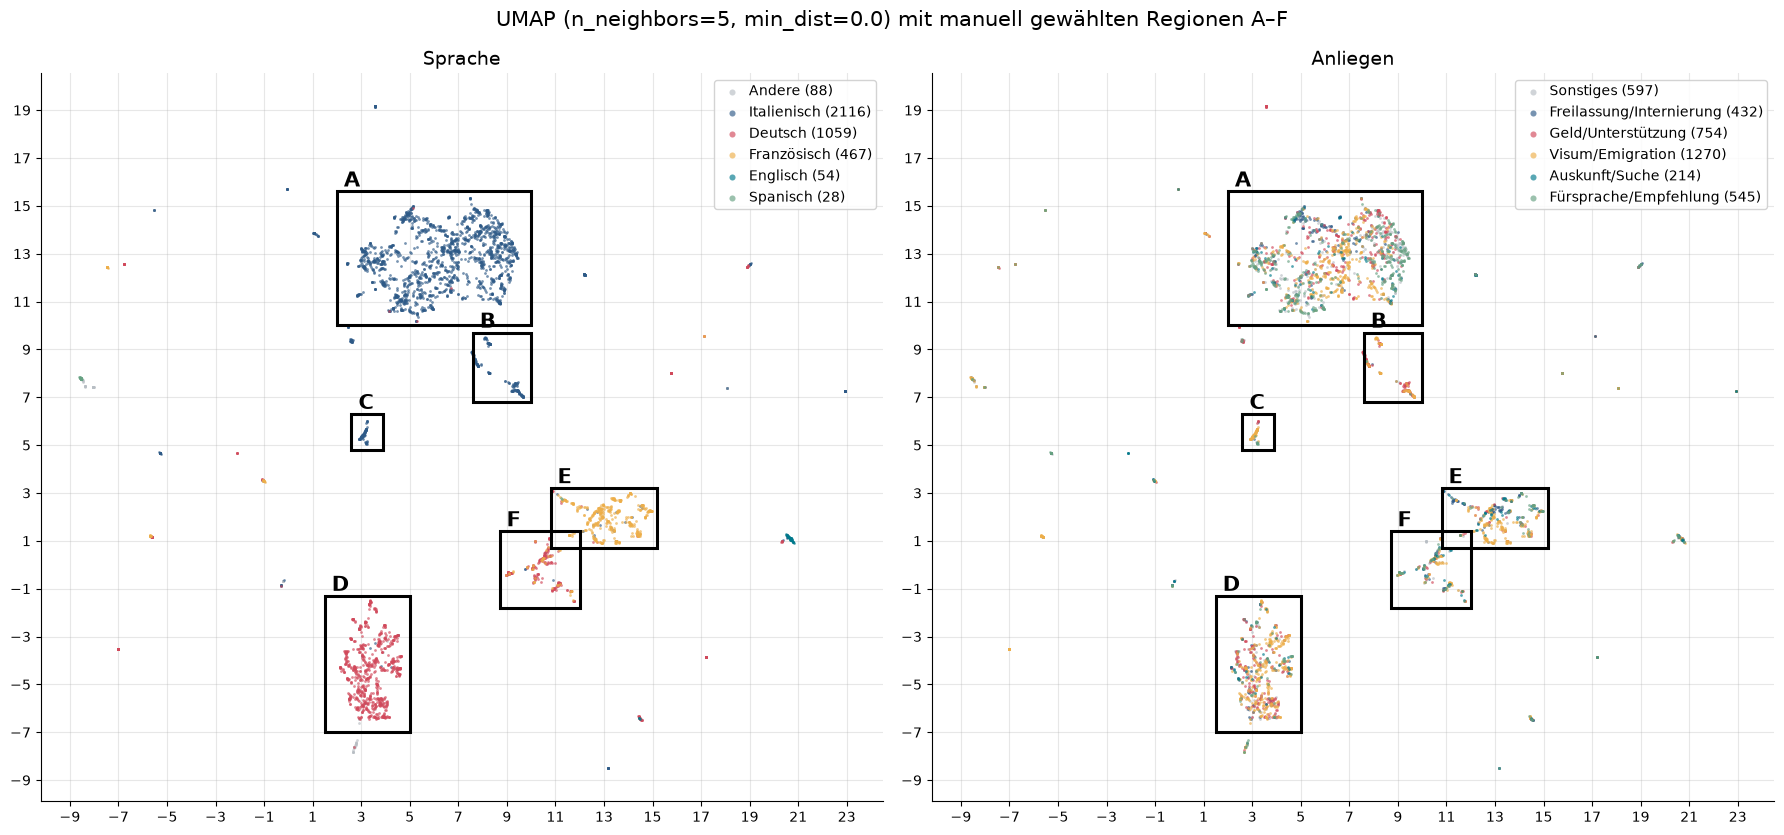

#### Region A: Italienische Hauptinsel (1653 Briefe)
*Sprachen:* Italienisch 100 %, Deutsch 0 %, Andere 0 % · *Anliegen:* Visum/Emigration 25 %, Fürsprache/Empfehlung 22 %  
*Top-Terme:* potere, roma, eccellenza, santità, padre, eminenza, volere, cattolico, famiglia, permettere, figlio, presso  
*Top-Keywords:* racial laws, recommendation, emigration, internment, baptism, mixed marriage, rome, gratitude

- **D13235** (Italienisch): Michele Simonelli requests intervention from a religious authority to help Giuseppe Sinigaglia, a fervent Catholic, gain recognition as Aryan from the Ministry of Interior after a negative outcome.
- **D13327** (Italienisch): Maria Spitzer requests Pope's intervention for her husband Giuseppe Spitzer's release from an Italian concentration camp, arguing his innocence and conversion to Catholicism.
- **D03550** (Italienisch): Stefano Bertolo requests Monsignor Tacchini to assist in advocating for Dr. Ettore De Benedetti's legal discrimination appeal due to his unique religious and familial background.

#### Region B: Italienischer Seitenstrang (151 Briefe)
*Sprachen:* Italienisch 100 % · *Anliegen:* Geld/Unterstützung 57 %, Visum/Emigration 36 %  
*Top-Terme:* eminenza, biglietto, reverendissima, baciando, espone, missionum, raphaelsverein, rappresentante, sottoscritto, romae, umilmente, lisbona  
*Top-Keywords:* financial aid, raphaelsverein, brazil visa, emigration, non-aryan, non-aryan catholic, brazilian visa, travel tickets

- **D07819** (Italienisch): Schechner Majer-Leib, a Polish citizen, requests financial assistance from Cardinal Maglione for travel expenses to Brazil, as he is alone and lacks family support under Russian occupation.
- **D05064** (Italienisch): The letter requests the recommendation of the Gefter family for a Brazilian visa due to their risk of deportation from Italy because of their German passport marked with "J".
- **D00898** (Italienisch): Ilse Nathan requests financial assistance from the Reverend to support her and her husband for one or two months until they can immigrate to Brazil due to their desperate situation.

#### Region C: Italienische Kleingruppe (Mitte links) (92 Briefe)
*Sprachen:* Italienisch 100 % · *Anliegen:* Visum/Emigration 74 %, Geld/Unterstützung 9 %  
*Top-Terme:* milano, curia, arcivescovile, maino, mod, brasile, archiepiscopalis, eminenza, erzbischöflichen, kurie, devoto, ambasciatore  
*Top-Keywords:* brazil visa, emigration, non-aryan, recommendation, milan curia, milan, baptism, racial laws

- **D06512** (Italienisch): The letter requests a special consideration for a visa for Reinheimer Milton and his family to move to Brazil for work, emphasizing their Catholic faith and good references.
- **D06393** (Italienisch): The letter requests support from the Brazilian Embassy for the emigration of Felice and Paolina Regenweter from Milan to Brazil. They are non-Aryan, baptized Catholics seeking assistance.
- **D00619** (Italienisch): Canonico Giuseppe Maino requests expedited visa assistance for Paul Bergel, a 45-year-old Catholic non-Aryan war invalid, to emigrate to Brazil due to special circumstances.

#### Region D: Deutsche Hauptinsel (752 Briefe)
*Sprachen:* Deutsch 97 %, Italienisch 2 %, Andere 1 % · *Anliegen:* Visum/Emigration 42 %, Geld/Unterstützung 27 %  
*Top-Terme:* bitte, heiligkeit, euer, heilig, vater, herr, eminenz, hilfe, frau, wien, rom, katholisch  
*Top-Keywords:* emigration, brazil visa, internment, vienna, rome, destitution, mixed marriage, trieste

- **D00391** (Deutsch): Olga Weitzmann requests Reverendo Brini's assistance in inquiring about her son's application and her letter to the Holy Father, due to her dire situation and imminent relocation to a camp.
- **D00342** (Deutsch): The Archbishop of Vienna requests $3,500 be transferred to Jointdisco New York for Jewish emigrants' travel expenses, following the closure of the USA consulates and Sankt Raphael’s Association.
- **D00274** (Deutsch): Norbert Redisch requests assistance from a Nuntius for expedited immigration to Brazil due to financial hardship and lack of work, after fleeing Austria due to non-Aryan descent.

#### Region E: Französische Insel (427 Briefe)
*Sprachen:* Französisch 92 %, Italienisch 5 %, Deutsch 3 % · *Anliegen:* Visum/Emigration 44 %, Freilassung/Internierung 22 %  
*Top-Terme:* excellence, mettre, vouloir, exzellenz, visa, hab, monseigneur, pouvoir, faire, catholique, prier, permettre  
*Top-Keywords:* brazil visa, emigration, deportation, intervention, internment, brazil, transit visa, spain

- **D08813** (Französisch): The letter requests assistance from the Apostolic Nuncio to expedite a Spanish transit visa for Peter Dor, a young Catholic refugee, before the deadline of April 16, 1941.
- **D03562** (Französisch): Julius Marcus requests Cardinal Maglione to intervene with the Italian Ministry of the Interior to reinstate or modify his travel visa to Spain for his wife's urgent medical treatment.
- **D00264** (Französisch): Armin and Alice Ball request financial assistance from the Vatican to pay for their ship passage to Brazil, citing their inability to cover the cost themselves.

#### Region F: Deutsch/gemischt neben FR (246 Briefe)
*Sprachen:* Deutsch 78 %, Französisch 20 %, Italienisch 2 % · *Anliegen:* Visum/Emigration 35 %, Sonstiges 18 %  
*Top-Terme:* exzellenz, excellence, eminence, monseigneur, bitte, monsignore, herr, eminenz, bitten, prie, nou, vichy  
*Top-Keywords:* emigration, brazil visa, gratitude, nice, financial aid, lisbon, brazilian visa, recommendation

- **D07058** (Französisch): Bishop of Berlin requests Cardinal Luigi Maglione to intervene again in obtaining a Brazilian visa for Mr. Adolph Thune, facing delays due to extraordinary circumstances and passive resistance from authorities.
- **D00712** (Französisch): The letter requests permission to immigrate to Brazil due to dire circumstances, expressing willingness to undertake any work to secure their child's future, and seeking a supportive response from the Vatican.
- **D14921** (Deutsch): Hans H Meyerowitz requests confirmation of receipt and a response to his previous letters regarding a troubling matter, sent two weeks ago, from the recipient, Monseigneur.

In [29]:
Y_best = um_grid[BEST][0]
np.save(PROJ / "umap_best_all.npy", Y_best)
REGIONS = [("Italienische Hauptinsel", 2.0, 10.0, 10.0, 15.6), ("Italienischer Seitenstrang", 7.6, 10.0, 6.8, 9.7), ("Italienische Kleingruppe (Mitte links)", 2.6, 3.9, 4.8, 6.3), ("Deutsche Hauptinsel", 1.5, 5.0, -7.0, -1.3), ("Französische Insel", 10.8, 15.2, 0.7, 3.2), ("Deutsch/gemischt neben FR", 8.7, 12.0, -1.8, 1.4)]   # (Name, x_min, x_max, y_min, y_max) – nach Sichtung der Projektion festgelegt

fig, axes = plt.subplots(1, 2, figsize=(18, 8.5))
D.scatter_by(axes[0], Y_best, COLORS["Sprache"], s=4)
D.scatter_by(axes[1], Y_best, COLORS["Anliegen"], order=ORDERS["Anliegen"], s=4)
for ax in axes:
    ax.set_xticks(np.arange(np.floor(Y_best[:, 0].min()), np.ceil(Y_best[:, 0].max()) + 1, 2))
    ax.set_yticks(np.arange(np.floor(Y_best[:, 1].min()), np.ceil(Y_best[:, 1].max()) + 1, 2))
    ax.tick_params(labelsize=10)
    ax.grid(True, alpha=0.3)
    for k, (name, x0, x1, y0, y1) in enumerate(REGIONS):
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=2.2, ec="black", zorder=6))
        ax.text(x0, y1, f" {chr(65 + k)}", fontsize=15, fontweight="bold", va="bottom", zorder=7)
axes[0].set_title("Sprache"); axes[1].set_title("Anliegen")
fig.suptitle(f"UMAP (n_neighbors={BEST[0]}, min_dist={BEST[1]}) mit manuell gewählten Regionen A–{chr(64 + max(len(REGIONS), 1))}")
fig.tight_layout()
save_fig(fig, "umap_regions", FIG)
plt.show()

terms_all = vec_all.get_feature_names_out()
reg_rows = []
for k, (name, x0, x1, y0, y1) in enumerate(REGIONS):
    m = (Y_best[:, 0] >= x0) & (Y_best[:, 0] <= x1) & (Y_best[:, 1] >= y0) & (Y_best[:, 1] <= y1)
    mean_tfidf = np.asarray(X_all[m].mean(axis=0)).ravel()
    top_t = [terms_all[i] for i in np.argsort(mean_tfidf)[::-1][:12]]
    kw = (df.loc[m, "summary_keywords"].dropna().str.split(",").explode().str.strip().str.lower().value_counts().head(8))
    lang_mix = COLORS.loc[m, "Sprache"].value_counts(normalize=True).head(3)
    req_mix = COLORS.loc[m, "Anliegen"].value_counts(normalize=True).head(2)
    reg_rows.append({"Region": f"{chr(65 + k)}: {name}", "Briefe": int(m.sum()),
                     "Sprachen": ", ".join(f"{l} {100 * v:.0f} %" for l, v in lang_mix.items()),
                     "Anliegen": ", ".join(f"{l} {100 * v:.0f} %" for l, v in req_mix.items()),
                     "Top-TF-IDF-Terme": ", ".join(top_t), "Top-summary_keywords": ", ".join(kw.index)})
    ex = df.loc[m].sample(min(3, int(m.sum())), random_state=RANDOM_STATE)
    display(Markdown(f"#### Region {chr(65 + k)}: {name} ({int(m.sum())} Briefe)\n"
                     f"*Sprachen:* {reg_rows[-1]['Sprachen']} · *Anliegen:* {reg_rows[-1]['Anliegen']}  \n"
                     f"*Top-Terme:* {reg_rows[-1]['Top-TF-IDF-Terme']}  \n"
                     f"*Top-Keywords:* {reg_rows[-1]['Top-summary_keywords']}\n\n" +
                     "\n".join(f"- **{r.id}** ({r.language_filled}): {r.gpt4o_summary}" for r in ex.itertuples())))
regions_tab = pd.DataFrame(reg_rows)
regions_tab.to_csv(RES / "umap_regions.csv", index=False)

**Interpretation:** Die Regionen zeigen, was die Projektion strukturiert. Die großen Inseln sind **Sprachen**: A Italienisch (1.653 Briefe), D Deutsch (752), E Französisch (427). Innerhalb einer Insel sind die Anliegen gemischt. Die kleinen Satelliten sind **Korrespondenz-Serien** mit eigenem Formular-Vokabular. Region B (151 Briefe) sind italienische Anfragen um Fahrkarten über den St. Raphaels-Verein und Lissabon (Geld 57 %, Visum 36 %). Region C (92) ist die Korrespondenz der Mailänder Kurie um Brasilien-Visa (Visum 74 %). Region F (246) ist deutsch-französische Korrespondenz mit Nuntiaturen und Vichy, erkennbar an den Anreden „Exzellenz/excellence“. Für das spätere Clustering heißt das: Ohne Gegenmaßnahme (Sprachtrennung oder multilinguale Embeddings) findet ein Clustering vor allem Sprachen und Absender-Serien statt Inhalte.

### 22. Outlier in der Projektion

Briefe mit `n_flags_all ≥ 3` aus dem Outlier-Notebook werden hervorgehoben. Liegen sie am Rand? Gemessen wird das über zwei Größen:
- die **lokale Dünnbesiedlung**: Distanz zum 10. Nachbarn in 2D, als Perzentil unter allen Briefen,
- die **Randlage**: Distanz zum Median-Zentrum der Projektion, als Perzentil.

Beides wird für die 2D-Projektion (UMAP) und zum Vergleich im TF-IDF-Originalraum (Kosinus-Distanz zum 10. Nachbarn) berechnet.

,Median-Perzentil Outlier,Median-Perzentil übrige,Mann-Whitney p (Outlier > übrige)
Distanz zum 10. Nachbarn (UMAP-2D),42,50,9.7e-01
Distanz zum Zentrum (UMAP-2D),52,50,2.0e-01
"Distanz zum 10. Nachbarn (TF-IDF, Kosinus)",73,50,4.1e-06


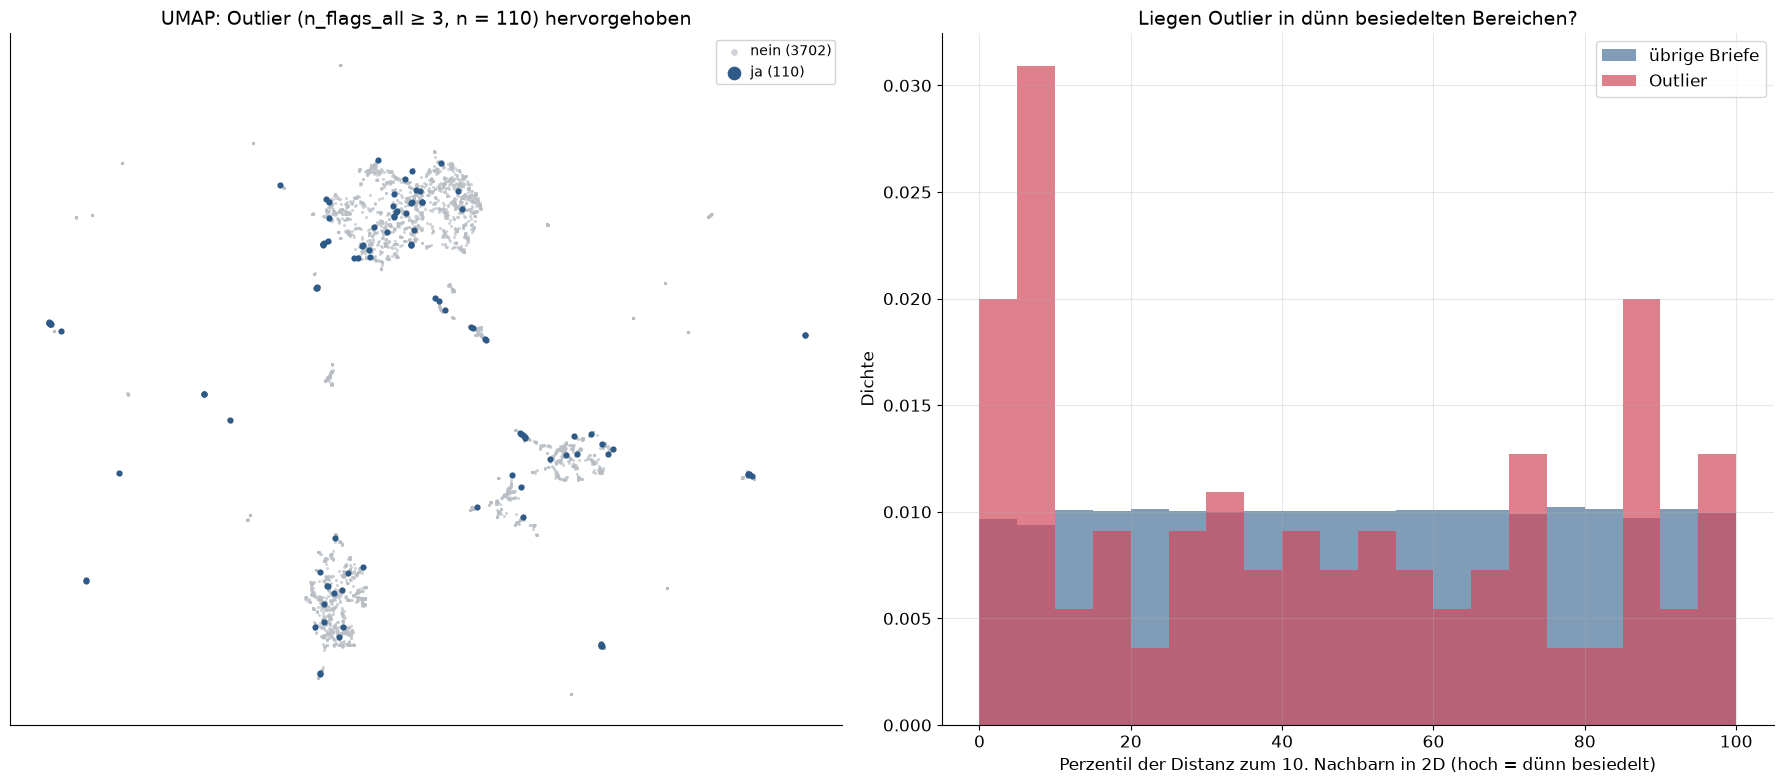

In [30]:
from sklearn.neighbors import NearestNeighbors
is_out = (COLORS["Outlier"] == "ja").to_numpy()
d10_2d = NearestNeighbors(n_neighbors=11).fit(Y_best).kneighbors(Y_best)[0][:, -1]
d10_hd = NearestNeighbors(n_neighbors=11, metric="cosine", algorithm="brute").fit(X_all).kneighbors(X_all)[0][:, -1]
d_center = np.linalg.norm(Y_best - np.median(Y_best, axis=0), axis=1)
pct = lambda v: stats.rankdata(v) / len(v) * 100
out_tab = pd.DataFrame({
    "Median-Perzentil Outlier": [np.median(pct(d10_2d)[is_out]), np.median(pct(d_center)[is_out]), np.median(pct(d10_hd)[is_out])],
    "Median-Perzentil übrige": [np.median(pct(d10_2d)[~is_out]), np.median(pct(d_center)[~is_out]), np.median(pct(d10_hd)[~is_out])],
}, index=["Distanz zum 10. Nachbarn (UMAP-2D)", "Distanz zum Zentrum (UMAP-2D)", "Distanz zum 10. Nachbarn (TF-IDF, Kosinus)"])
mw = [stats.mannwhitneyu(v[is_out], v[~is_out], alternative="greater").pvalue for v in (d10_2d, d_center, d10_hd)]
out_tab["Mann-Whitney p (Outlier > übrige)"] = mw
display(out_tab.style.format({"Median-Perzentil Outlier": "{:.0f}", "Median-Perzentil übrige": "{:.0f}",
                              "Mann-Whitney p (Outlier > übrige)": "{:.1e}"}))

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
D.scatter_by(axes[0], Y_best, COLORS["Outlier"], s=5, highlight="ja")
axes[0].set_title(f"UMAP: Outlier (n_flags_all ≥ 3, n = {is_out.sum()}) hervorgehoben")
ax = axes[1]
ax.hist(pct(d10_2d)[~is_out], bins=20, range=(0, 100), density=True, alpha=0.6, color=PALETTE["main"], label="übrige Briefe")
ax.hist(pct(d10_2d)[is_out], bins=20, range=(0, 100), density=True, alpha=0.7, color=PALETTE["outlier"], label="Outlier")
ax.set_xlabel("Perzentil der Distanz zum 10. Nachbarn in 2D (hoch = dünn besiedelt)")
ax.set_ylabel("Dichte")
ax.set_title("Liegen Outlier in dünn besiedelten Bereichen?")
ax.legend()
fig.tight_layout()
save_fig(fig, "outliers_in_projection", FIG)
plt.show()
STATS["outliers_in_projection"] = {"n_outliers": int(is_out.sum()),
                                   **{k: {"median_pct_outlier": round(float(r["Median-Perzentil Outlier"]), 1),
                                          "median_pct_rest": round(float(r["Median-Perzentil übrige"]), 1)}
                                      for k, r in out_tab.iterrows()}}

**Interpretation:** Im TF-IDF-Originalraum liegen die Outlier deutlich isolierter als die übrigen Briefe: Median-Perzentil der Distanz zum 10. Nachbarn 73 gegenüber 50, p = 4·10⁻⁶. In der UMAP-Projektion ist davon nichts mehr zu sehen (Perzentil 42 vs. 50 für die lokale Dichte, 52 vs. 50 für die Randlage, beide nicht signifikant). UMAP zieht isolierte Briefe in bestehende Nachbarschaften. Outlier sollten deshalb im Originalraum gesucht werden, nicht in der 2D-Projektion. Das bestätigt das Vorgehen im Outlier-Notebook.

## Teil G – Output

Kennzahlen nach `results/dimred/dimred_stats.json`, Plot-Übersicht mit Kernaussagen nach `results/dimred/DIMRED_README.md`.

In [31]:
q = quality.set_index(["Daten", "Methode"])
STATS["runtimes_s"] = {f"{d} | {m}": round(float(r["Laufzeit_s"]), 2) for (d, m), r in q.iterrows()}
with open(RES / "dimred_stats.json", "w", encoding="utf-8") as fh:
    json.dump(STATS, fh, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print(json.dumps({k: STATS[k] for k in ["n_used", "n_excluded", "features_pca", "tfidf", "svd_explained_variance_pct"]},
                 ensure_ascii=False, indent=1)[:2500])

{
 "n_used": 3812,
 "n_excluded": 27,
 "features_pca": {
  "eigenvalues": [
   3.2774,
   1.5706,
   1.0852,
   0.9677,
   0.7342,
   0.6483,
   0.559,
   0.1576,
   0.0
  ],
  "explained_variance_pc1_3_pct": [
   36.42,
   17.45,
   12.06
  ],
  "trace_check": 9.0,
  "recommended_n_components": {
   "Scree-Ellbogen": 2,
   "Kaiser (λ > 1)": 3,
   "kumuliert ≥ 80 %": 5,
   "Parallel Analysis (95 %)": 3
  }
 },
 "tfidf": {
  "all": {
   "n_docs": 3812,
   "n_terms": 12546,
   "sparsity_pct": 99.279,
   "empty_rows": 0
  },
  "italian": {
   "n_docs": 2116,
   "n_terms": 4912,
   "sparsity_pct": 98.55,
   "empty_rows": 0
  }
 },
 "svd_explained_variance_pct": {
  "all": {
   "2": 2.363,
   "10": 6.395,
   "50": 13.161,
   "100": 18.522
  },
  "italian": {
   "2": 2.031,
   "10": 6.606,
   "50": 16.054,
   "100": 24.054
  }
 }
}


In [32]:
S = STATS
de = lambda x: f"{x:,}".replace(",", ".")
pf = S["features_pca"]
rec = pf["recommended_n_components"]
kq = lambda d, m: q.loc[(d, m)]
readme = f'''# Dimensionality Reduction – Ergebnisse für die Präsentation

Erzeugt von `notebooks/03_dimensionality_reduction.ipynb` (Hilfsfunktionen: `src/dimred.py`).
Datengrundlage: {de(S["n_used"])} Briefe ({S["n_excluded"]} laut Outlier-Notebook ausgeschlossen: Fragmente/Archivverweise).
Alle Abbildungen liegen als PNG (300 dpi) und SVG in `figures/dimred/`, die 2D-Projektionen als `.npy` in `results/dimred/projections/`.

## Kernaussagen für die Folien

1. **Features: wenige, gut interpretierbare Achsen.** Die Korrelations-PCA der 9 Text-/Metadaten-Features erklärt mit PC1–PC3
   {pf["explained_variance_pc1_3_pct"][0]:.0f} % / {pf["explained_variance_pc1_3_pct"][1]:.0f} % / {pf["explained_variance_pc1_3_pct"][2]:.0f} % der Varianz.
   Empfohlene Komponentenzahl: Kaiser {rec["Kaiser (λ > 1)"]}, 80-%-Regel {rec["kumuliert ≥ 80 %"]}, Parallel Analysis {rec["Parallel Analysis (95 %)"]}.
2. **Ohne Standardisierung dominiert die Skala:** In der Kovarianz-PCA bestimmen die Längen-Features PC1, die Anteils-Features gehen unter (Gewicht ≈ 0).
3. **TF-IDF ist hochdimensional und dünn:** {de(S["tfidf"]["all"]["n_terms"])} Terme, {S["tfidf"]["all"]["sparsity_pct"]:.1f} % Nullen.
   2 SVD-Komponenten erklären nur {S["svd_explained_variance_pct"]["all"]["2"]:.1f} % der Varianz, 100 Komponenten {S["svd_explained_variance_pct"]["all"]["100"]:.1f} %.
4. **TF-IDF trennt vor allem nach Sprache:** In allen Verfahren bilden Italienisch, Deutsch und Französisch getrennte Inseln.
   Inhaltliche Struktur (Anliegen) wird erst in der Variante „nur Italienisch“ sichtbar.
5. **Lokal vs. global (Vorlesung bestätigt):** UMAP erhält {100 * kq("alle Sprachen", "UMAP")["knn_preservation"]:.0f} % der 10 nächsten Nachbarn,
   t-SNE {100 * kq("alle Sprachen", "t-SNE")["knn_preservation"]:.0f} %, PCA/LSA nur {100 * kq("alle Sprachen", "PCA/LSA")["knn_preservation"]:.0f} %.
   Globale Distanzen (Spearman ρ): PCA/LSA {kq("alle Sprachen", "PCA/LSA")["spearman_global"]:.2f}, UMAP {kq("alle Sprachen", "UMAP")["spearman_global"]:.2f},
   t-SNE {kq("alle Sprachen", "t-SNE")["spearman_global"]:.2f}.
6. **Outlier verschwinden in 2D:** Im TF-IDF-Raum liegen die Outlier deutlich isolierter (Median-Perzentil der 10-NN-Distanz
   {S["outliers_in_projection"]["Distanz zum 10. Nachbarn (TF-IDF, Kosinus)"]["median_pct_outlier"]:.0f} vs. 50), in der UMAP-Projektion nicht
   ({S["outliers_in_projection"]["Distanz zum 10. Nachbarn (UMAP-2D)"]["median_pct_outlier"]:.0f} vs. 50). Outlier also im Originalraum suchen.
7. **Linearer Autoencoder vs. PCA:** Eine Richtung trifft PC2 (Winkel {min(S["linear_ae_vs_pca"]["principal_angles_deg"]):.0f}°), die andere nicht
   ({max(S["linear_ae_vs_pca"]["principal_angles_deg"]):.0f}°), weil λ₂ ≈ λ₃ ({S["linear_ae_vs_pca"]["pca_eigenvalues_1_3"][1]:.2f} vs. {S["linear_ae_vs_pca"]["pca_eigenvalues_1_3"][2]:.2f}).
   Der 2D-Unterraum ist damit kaum eindeutig bestimmt.

## Abbildungen (`figures/dimred/`)

| Datei | Erklärung |
|---|---|
| `curse_of_dimensionality` | Simulation Unif([0,1]^d): Der relative Distanzkontrast fällt von d = 2 bis d = 1000 um Größenordnungen, die Distanzverteilung wird schmal. |
| `curse_of_dimensionality_tfidf` | Echte Daten: Die Kosinus-Distanzen der TF-IDF-Vektoren ballen sich nahe 1 (fast alle Briefe gleich unähnlich), anders als im 9-Feature-Raum. |
| `pca_cov_vs_corr` | PCA auf Kovarianz vs. Korrelation: Ohne Standardisierung dominieren die großvarianten Längen-Features PC1. |
| `scree_kaiser_parallel` | Scree-Plot mit Kaiser-Linie (λ = 1) und Parallel Analysis (95-%-Quantil von 100 Permutationen). |
| `cumulative_variance` | Kumulierte erklärte Varianz der Feature-PCA mit 80-%-Schwelle. |
| `loadings_heatmap` | Loadings der ersten 4 PCs, Grundlage für die inhaltliche Benennung der Achsen. |
| `biplot_pc1_pc2`, `biplot_pc1_pc3` | Biplots (Scores + Loading-Pfeile), gefärbt nach Sprache bzw. Outlier-Flag. |
| `svd_explained_variance` | Erklärte Varianz der TruncatedSVD (alle Sprachen / nur Italienisch). |
| `svd_top_terms` | Terme mit den stärksten positiven/negativen Ladungen der ersten 5 SVD-Komponenten. |
| `projection_pca_all`, `projection_tsne_all`, `projection_umap_all`, `projection_pacmap_all` | Je eine Projektion, gefärbt nach allen 6 Färbe-Variablen. |
| `tsne_perplexity_grid` | t-SNE mit Perplexity 5/30/50/100: Kleine Werte zersplittern, große glätten. |
| `tsne_init_comparison`, `tsne_seeds` | Initialisierung pca vs. random und drei Seeds: Lage und Form der Inseln ändern sich, die Nachbarschaften bleiben. |
| `umap_param_grid` | UMAP-Grid n_neighbors × min_dist: n_neighbors steuert lokal/global, min_dist die Kompaktheit. |
| `umap_init_comparison` | UMAP spectral vs. random (Kobak & Linderman 2021). |
| `umap_transform` | UMAP transform(): 20 % neue Briefe werden ohne Neuberechnung eingebettet. |
| `autoencoder_loss` | Lernkurven (Training/Validierung) mit Early Stopping. |
| `autoencoder_linear_vs_pca` | PCA vs. linearer AE vs. ReLU-AE. Der lineare AE trifft PC2, die andere Richtung ist wegen λ₂ ≈ λ₃ unbestimmt. |
| `method_comparison_language` | **Zentrale Folie:** PCA, t-SNE, UMAP, PaCMAP, Autoencoder nebeneinander, gefärbt nach Sprache. |
| `method_comparison_request` | Dieselben Projektionen, gefärbt nach Anliegen-Kategorie. |
| `projection_pca_italian`, `tsne_perplexity_grid_italian`, `umap_param_grid_italian` | Variante nur italienische Briefe. |
| `method_comparison_italian` | Fünf Verfahren nur auf italienischen Briefen, gefärbt nach Anliegen und Archiv. |
| `quality_metrics` | Trustworthiness, kNN-Erhalt, Spearman ρ und Laufzeit je Verfahren (alle Sprachen / Italienisch). |
| `umap_regions` | Beste UMAP-Projektion mit manuell gewählten Regionen A–… (Inhalte: `results/dimred/umap_regions.csv`). |
| `outliers_in_projection` | Outlier aus dem Outlier-Notebook in der UMAP-Projektion und ihre lokale Dichte. |

## Tabellen (`results/dimred/`)

- `dimred_quality.csv` – Qualitätsmetriken + Laufzeit je Verfahren und Datensatz
- `umap_grid_quality.csv` – Qualitätsmetriken aller UMAP-Einstellungen
- `features_pca_loadings.csv`, `features_pca_n_components.csv` – Loadings und Komponentenwahl der Feature-PCA
- `svd_top_terms.csv`, `umap_regions.csv`
- `dimred_stats.json` – alle Kennzahlen
- `projections/*.npy` – alle 2D-Projektionen (Reihenfolge der Briefe = Reihenfolge nach Ausschluss; IDs in `projections/ids_*.npy`)
'''
np.save(PROJ / "ids_all.npy", df["id"].to_numpy(dtype=str))
np.save(PROJ / "ids_italian.npy", df.loc[it_mask, "id"].to_numpy(dtype=str))
(RES / "DIMRED_README.md").write_text(readme, encoding="utf-8")
print(readme[:2500])

# Dimensionality Reduction – Ergebnisse für die Präsentation

Erzeugt von `notebooks/03_dimensionality_reduction.ipynb` (Hilfsfunktionen: `src/dimred.py`).
Datengrundlage: 3.812 Briefe (27 laut Outlier-Notebook ausgeschlossen: Fragmente/Archivverweise).
Alle Abbildungen liegen als PNG (300 dpi) und SVG in `figures/dimred/`, die 2D-Projektionen als `.npy` in `results/dimred/projections/`.

## Kernaussagen für die Folien

1. **Features: wenige, gut interpretierbare Achsen.** Die Korrelations-PCA der 9 Text-/Metadaten-Features erklärt mit PC1–PC3
   36 % / 17 % / 12 % der Varianz.
   Empfohlene Komponentenzahl: Kaiser 3, 80-%-Regel 5, Parallel Analysis 3.
2. **Ohne Standardisierung dominiert die Skala:** In der Kovarianz-PCA bestimmen die Längen-Features PC1, die Anteils-Features gehen unter (Gewicht ≈ 0).
3. **TF-IDF ist hochdimensional und dünn:** 12.546 Terme, 99.3 % Nullen.
   2 SVD-Komponenten erklären nur 2.4 % der Varianz, 100 Komponenten 18.5 %.
4. **TF-IDF trennt vor allem nach S

## Zusammenfassung

- **Vorlesung 09:** Curse of Dimensionality (Simulation + TF-IDF), PCA auf Kovarianz vs. Korrelation, Eigenzerlegung von Hand, Komponentenwahl (Scree, Kaiser, 80 %), Loadings und Biplots. **Erweiterung:** Parallel Analysis.
- **Vorlesung Projections & Encoders:** PCA/LSA, t-SNE (Perplexity, Init, Seeds), UMAP (Grid, Init, transform), Autoencoder (ReLU + linear). **Erweiterungen:** TruncatedSVD, PaCMAP, Qualitätsmaße.
- **Kernergebnis:** Die 9 Features lassen sich gut auf 3 interpretierbare Achsen verdichten. Im TF-IDF-Raum dominieren zuerst die Sprache und danach Korrespondenz-Serien, inhaltliche Anliegen spielen eine nachgeordnete Rolle. t-SNE und UMAP erhalten lokale Nachbarschaften klar besser als PCA.
- **Abweichungen/Hinweise:** Schritt 20 entfällt (keine Embeddings in `new_results/data/`). Der lineare Autoencoder trifft den PCA-Unterraum nur teilweise, weil λ₂ ≈ λ₃. Das Pre-Processing routet nach der erkannten Sprache und nutzt eine gemeinsame Stopword-Liste.